# Module 6: Model Inference & Route Optimization — Chennai MTC (Unseen City)

**Project:** RouteRanker — AI-Based Public Transit Route Analysis for Indian Cities  
**Training Cities (Modules 1–5):** Ahmedabad, Bengaluru, Davangere, Delhi, HDBRT, Mumbai, Pune, Rajkot  
**Unseen Inference Dataset:** Chennai MTC GTFS (`NEW CITY/GTFS/`, Date: 21/11/2026)  

### Governing Rules
1. **Scheduled Supply Only:** GTFS represents planned transit service, not passenger ridership or demand. No synthetic passenger counts or labels like *overcrowded*, *underutilised*, or *inefficient* are permitted.
2. **Exact Pipeline Reuse:** All feature definitions, formulas, and column schemas strictly replicate Module 2. Saved pipeline transformers (`processed/pipeline/`) are applied with `.transform()` only—never refitted.
3. **Exploratory Framing:** Cluster assignments and model predictions are candidates for further investigation, not performance rankings or guarantees.
4. **Provenance Labeling:** Every metric table and chart distinguishes `ACTUAL DATA`, `MODEL PREDICTION`, `ESTIMATE`, and `SIMULATED RESULT`.
5. **Non-Destructive Execution:** Raw GTFS feeds, training data, and saved models remain untouched. Outputs go strictly to `inference/`, `simulation/`, `visualizations/inference/`, and `reports/`.
6. **Spatial Realism & Missing Data:** Route merging/splitting considerations account for connectivity and explicitly disclose missing geometry (`shapes.txt`).
7. **Reproducible Phased Workflow:** Fixed random seed (`42`), clear step-by-step explanations, waiting for user confirmation before advancing to the next phase.


---
## Setup: Environment, Output Directories & Existing Asset Verification

Before loading the unseen city's data, we fix our random seed (`42`), ensure our Phase 1 output folders (`inference/`, `simulation/`, `visualizations/inference/`, `reports/`) exist, and verify the exact filenames of all pre-trained models and preprocessing artifacts from Modules 2–5.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

# Fixed seed for full reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 1000)

# Project paths
NEW_CITY_DIR = Path("NEW CITY/GTFS")
OUT_INFERENCE = Path("inference")
OUT_SIMULATION = Path("simulation")
OUT_VIZ = Path("visualizations/inference")
OUT_REPORTS = Path("reports")

for d in [OUT_INFERENCE, OUT_SIMULATION, OUT_VIZ, OUT_REPORTS]:
    d.mkdir(parents=True, exist_ok=True)

# Verify existing pipeline and model assets
expected_assets = [
    Path("src/feature_pipeline.py"),
    Path("processed/route_features.csv"),
    Path("processed/pipeline/feature_list.json"),
    Path("processed/pipeline/feature_scaler.joblib"),
    Path("processed/pipeline/one_hot_encoder.joblib"),
    Path("processed/pipeline/length_cap.json"),
    Path("models/kmeans_model.joblib"),
    Path("models/dbscan_model.joblib"),
]

print("Asset Verification:")
for p in expected_assets:
    status = "FOUND" if p.exists() else "MISSING"
    print(f"  [{status}] {p}")

with open("processed/pipeline/feature_list.json", "r", encoding="utf-8") as f:
    MODEL_FEATURE_LIST = json.load(f)
print(f"\nLoaded MODEL_FEATURE_LIST ({len(MODEL_FEATURE_LIST)} features): {MODEL_FEATURE_LIST}")


Asset Verification:
  [FOUND] src\feature_pipeline.py
  [FOUND] processed\route_features.csv
  [FOUND] processed\pipeline\feature_list.json
  [FOUND] processed\pipeline\feature_scaler.joblib
  [FOUND] processed\pipeline\one_hot_encoder.joblib
  [FOUND] processed\pipeline\length_cap.json
  [FOUND] models\kmeans_model.joblib
  [FOUND] models\dbscan_model.joblib

Loaded MODEL_FEATURE_LIST (12 features): ['trip_count_log1p_scaled', 'stop_count_scaled', 'route_length_km_log1p_scaled', 'service_span_hours_scaled', 'first_departure_hour_scaled', 'morning_trip_share_scaled', 'evening_trip_share_scaled', 'night_trip_share_scaled', 'period_afternoon', 'period_evening', 'period_morning', 'period_night']


---
## Phase 1.1: Inspect New City GTFS Directory, Extensions & Optional Files

First, we inspect the contents of `NEW CITY/GTFS/` to verify file extensions (`.txt` vs `.csv`), check optional files (`shapes.txt` and `frequencies.txt`), and read agency/feed metadata.


In [2]:
from src.feature_pipeline import check_optional_files

print("Files inside NEW CITY/GTFS/:")
for f in sorted(NEW_CITY_DIR.iterdir()):
    print(f"  {f.name:<20} | ext={f.suffix:<5} | size={f.stat().st_size:>12,} bytes")

opt_status = check_optional_files(NEW_CITY_DIR, ext=".txt")
print(f"\nOptional file status (.txt): {opt_status}")

# Inspect agency.txt and feed_info.txt for context
for meta_file in ["agency.txt", "feed_info.txt"]:
    mp = NEW_CITY_DIR / meta_file
    if mp.exists():
        print(f"\n--- {meta_file} (ACTUAL DATA) ---")
        print(pd.read_csv(mp).to_string(index=False))


Files inside NEW CITY/GTFS/:
  agency.txt           | ext=.txt  | size=         133 bytes
  calendar.txt         | ext=.txt  | size=         342 bytes
  feed_info.txt        | ext=.txt  | size=         269 bytes
  routes.txt           | ext=.txt  | size=     226,405 bytes
  stop_times.txt       | ext=.txt  | size=  43,537,866 bytes
  stops.txt            | ext=.txt  | size=     230,767 bytes
  trips.txt            | ext=.txt  | size=   1,049,101 bytes

Optional file status (.txt): {'shapes': False, 'frequencies': False}

--- agency.txt (ACTUAL DATA) ---
 agency_id agency_name               agency_url agency_timezone  agency_phone agency_lang
        69         MTC https://mtcbus.tn.gov.in    Asia/Kolkata    9445030516          en

--- feed_info.txt (ACTUAL DATA) ---
feed_publisher_name                   feed_publisher_url feed_lang  feed_start_date  feed_end_date  feed_version                 feed_contact_email                            feed_contact_url
   IthuUngalSoththu https://ith

---
## Phase 1.2: Load Core GTFS Tables, Prefix IDs, and Inspect Schemas

We use `load_city_gtfs()` from `src/feature_pipeline.py` (extracted directly from Module 2).  
Identifier columns (`route_id`, `agency_id`, `trip_id`, `service_id`, `stop_id`, etc.) are read explicitly as strings and prefixed with `"chennai_"` so IDs stay globally unique across cities.


In [3]:
from src.feature_pipeline import CORE_FILES, load_city_gtfs

NEW_CITY_NAME = "chennai"
chennai_data, chennai_opt, chennai_meta = load_city_gtfs(
    city=NEW_CITY_NAME,
    city_path=NEW_CITY_DIR,
    ext=".txt",
    prefix_ids=True,
)

print(f"{'File':<16} | {'Rows':>10} | {'Cols':>5} | Columns")
print("-" * 95)
for m in chennai_meta:
    print(f"{m['file']:<16} | {m['rows']:>10,} | {m['cols']:>5} | {m['columns']}")

print("\nDetailed Dtypes & Missing Values per Core File (ACTUAL DATA):")
for fn in CORE_FILES:
    df = chennai_data[fn]
    print(f"\n[{fn}.txt] shape={df.shape}")
    info_df = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isnull().sum(),
        "missing_pct": (100.0 * df.isnull().sum() / len(df)).round(2),
    })
    print(info_df.to_string())

print("\nPrefixed ID sanity check (routes.txt first 3 rows):")
print(chennai_data["routes"][["city", "route_id", "agency_id", "route_short_name"]].head(3).to_string(index=False))


File             |       Rows |  Cols | Columns
-----------------------------------------------------------------------------------------------
routes.txt       |      4,611 |     6 | ['city', 'route_id', 'route_short_name', 'route_long_name', 'route_type', 'agency_id']
trips.txt        |     47,047 |     5 | ['city', 'trip_id', 'route_id', 'service_id', 'direction_id']
stop_times.txt   |  1,360,443 |     6 | ['city', 'trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence']
stops.txt        |      5,580 |     5 | ['city', 'stop_id', 'stop_name', 'stop_lat', 'stop_lon']
calendar.txt     |          6 |    11 | ['city', 'service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date']

Detailed Dtypes & Missing Values per Core File (ACTUAL DATA):

[routes.txt] shape=(4611, 6)
                  dtype  missing_count  missing_pct
city                str              0          0.0
route_id            str              0      

                dtype  missing_count  missing_pct
city              str              0          0.0
trip_id           str              0          0.0
arrival_time      str              0          0.0
departure_time    str              0          0.0
stop_id           str              0          0.0
stop_sequence   int64              0          0.0

[stops.txt] shape=(5580, 5)
             dtype  missing_count  missing_pct
city           str              0          0.0
stop_id        str              0          0.0
stop_name      str              0          0.0
stop_lat   float64              0          0.0
stop_lon   float64              0          0.0

[calendar.txt] shape=(6, 11)
            dtype  missing_count  missing_pct
city          str              0          0.0
service_id    str              0          0.0
monday      int64              0          0.0
tuesday     int64              0          0.0
wednesday   int64              0          0.0
thursday    int64              0 

---
## Phase 1.3: Data Quality Checks (Document Only — No Silent Mutations)

We execute the exact same six data quality checks used on the 8 training cities in Module 2:
1. Missing cell values
2. Duplicate full rows and duplicate primary IDs (`route_id`, `trip_id`, `stop_id`), plus `route_short_name` inspection
3. Cross-file orphan IDs (`trips -> routes`, `stop_times -> trips`, `stop_times -> stops`, `trips -> calendar`)
4. GTFS time format validation and valid overnight departures ($\ge 24:00:00$)
5. Stop coordinate bounds check against India's geographic bounding box ($\text{lat} \in [6^\circ, 38^\circ]$, $\text{lon} \in [68^\circ, 98^\circ]$)
6. Calendar date range parsing, `end_date < start_date` check, and unscheduled route / unused service inspection


In [4]:
from src.feature_pipeline import run_data_quality_checks

dq = run_data_quality_checks(NEW_CITY_NAME, chennai_data)

print("1. MISSING VALUES:")
print("  None found." if dq["missing"].empty else dq["missing"].to_string(index=False))

print("\n2. DUPLICATE ROWS & PRIMARY IDs:")
print(dq["duplicates"].to_string(index=False))

# Additional route_short_name and unscheduled route check
r_df = chennai_data["routes"]
t_df = chennai_data["trips"]
st_df = chennai_data["stop_times"]
c_df = chennai_data["calendar"]

dup_sn = int(r_df["route_short_name"].duplicated().sum())
dup_pair = int(r_df.duplicated(subset=["route_short_name", "route_long_name"]).sum())
unsched_routes = set(r_df["route_id"]) - set(t_df["route_id"])
print(f"  Additional check -> duplicate route_short_name: {dup_sn:,} | duplicate (short, long): {dup_pair:,}")
print(f"  Additional check -> routes in routes.txt with 0 trips in trips.txt: {len(unsched_routes):,} / {len(r_df):,} ({100*len(unsched_routes)/len(r_df):.2f}%)")

print("\n3. ORPHAN CROSS-FILE IDs:")
print(dq["orphans"].to_string(index=False))

print("\n4. TIME FORMAT & OVERNIGHT (>=24h) CHECK:")
print(dq["times"].to_string(index=False))

print("\n5. STOP COORDINATES (INDIA BOUNDS 6-38 N, 68-98 E):")
print(pd.DataFrame([dq["coordinates"]]).to_string(index=False))

print("\n6. CALENDAR DATE RANGE & REFERENCED SERVICES:")
print(pd.DataFrame([dq["calendar"]]).to_string(index=False))
print("\nRaw calendar.txt rows (ACTUAL DATA):")
print(c_df.to_string(index=False))
print("\nTrips per service_id (ACTUAL DATA):")
print(t_df["service_id"].value_counts(dropna=False).to_string())


1. MISSING VALUES:
  None found.

2. DUPLICATE ROWS & PRIMARY IDs:
   city       file              check  count
chennai     routes     duplicate_rows      0
chennai     routes duplicate_route_id      0
chennai      trips     duplicate_rows      0
chennai      trips  duplicate_trip_id      0
chennai stop_times     duplicate_rows      0
chennai      stops     duplicate_rows      0
chennai      stops  duplicate_stop_id      0
chennai   calendar     duplicate_rows      0
  Additional check -> duplicate route_short_name: 2,291 | duplicate (short, long): 0
  Additional check -> routes in routes.txt with 0 trips in trips.txt: 677 / 4,611 (14.68%)

3. ORPHAN CROSS-FILE IDs:
   city child_file  child_col parent_file  orphan_count  orphan_pct note
chennai      trips   route_id      routes             0         0.0     
chennai stop_times    trip_id       trips             0         0.0     
chennai stop_times    stop_id       stops             0         0.0     
chennai      trips service_id    

### Summary of Chennai Data Quality Findings & Handling Plan (Document Only)

| Finding | Observation (`ACTUAL DATA`) | Impact & Planned Handling |
|---|---|---|
| **Missing Values & Orphans** | **0 missing cells**, **0 duplicate rows/primary IDs**, and **0 orphan cross-file IDs** across all 5 core files. | No missing-value imputation or orphan repair needed at raw ingestion stage. |
| **Unscheduled Catalog Routes** | **677 of 4,611 routes** (`14.68%`) appear in `routes.txt` with zero trips in `trips.txt`. | **Keep documented, do not delete.** Consistent with Module 2/4 (`682` unscheduled routes in training), they retain `NaN` trip metrics in `inference/new_city_route_features.csv` and are isolated into an unscheduled catalog before scaling/inference. |
| **Overnight Trips ($\ge 24:00:00$)** | **1,904 stop-time rows** (`0.14%`) have times $\ge 24:00:00$; **0 bad formats**. | Valid GTFS overnight notation; handled cleanly via integer seconds arithmetic (`gtfs_to_seconds`). |
| **Calendar Artifact Rows** | `calendar.txt` contains 6 rows, including unreferenced entries `chennai_test ` (trailing space) and `chennai_'/><script>alert(1)</script>` (XSS test string), plus `Weekend` and `Hybrid`. | **0 trips** in `trips.txt` reference these 4 rows (trips only use `Regular` [46,973] and `HSC` [74]). Documented without mutating raw files; HTML-escape identifiers if rendered in web visuals. |
| **Wide Calendar Date Span** | `start_date = 2024-05-01`, `end_date = 2030-05-01` (6-year placeholder window). | Documented as a feed-horizon convention; day-of-week columns remain valid for service-type classification. |
| **Repeated `route_short_name`** | **2,291 duplicate `route_short_name`** values, but **0 duplicate `(route_short_name, route_long_name)`** pairs. | MTC Chennai splits reverse directions or corridor variants into separate `route_id` records sharing a short name (e.g. Route `1` A→B vs B→A). Keep `route_id` as the unique key. |
| **Coordinate Sanity** | All **5,580 stops** have valid coordinates strictly inside Chennai (`lat` 12.61–13.49°N, `lon` 79.80–80.34°E). | Spatial coordinates are valid for Haversine stop-based route length estimation and connectivity checks. |


---
## Phase 1.4: Verify Extracted `src/feature_pipeline.py` Against Saved Training Features

To prove that our reusable module (`src/feature_pipeline.py`) contains the **exact** logic of Module 2 without any drift, we run `build_city_route_features()` on a training city (`rajkot`) and compare all 271 routes and 20 columns cell-by-cell against the saved `processed/route_features.csv`.


In [5]:
from src.feature_pipeline import build_city_route_features

saved_train_df = pd.read_csv(
    "processed/route_features.csv",
    dtype={
        "city": str,
        "route_id": str,
        "original_route_id": str,
        "route_short_name": str,
        "route_long_name": str,
    },
)

rebuilt_rajkot, _ = build_city_route_features("rajkot", Path("RAW DATASET/GTFS RAJKOT"), ext=".txt")
saved_rajkot = saved_train_df[saved_train_df["city"] == "rajkot"].reset_index(drop=True)
rebuilt_rajkot = rebuilt_rajkot.reset_index(drop=True)

assert list(rebuilt_rajkot.columns) == list(saved_rajkot.columns), "Column mismatch!"
assert rebuilt_rajkot.shape == saved_rajkot.shape, "Shape mismatch!"

total_diffs = 0
for col in saved_rajkot.columns:
    if pd.api.types.is_numeric_dtype(saved_rajkot[col]):
        a = pd.to_numeric(rebuilt_rajkot[col], errors="coerce")
        b = pd.to_numeric(saved_rajkot[col], errors="coerce")
        eq = (a.isna() & b.isna()) | np.isclose(a.fillna(0), b.fillna(0), atol=1e-9, rtol=1e-9)
        total_diffs += int((~eq).sum())
    else:
        a = rebuilt_rajkot[col].fillna("__NA__").astype(str)
        b = saved_rajkot[col].fillna("__NA__").astype(str)
        total_diffs += int((a != b).sum())

print(f"Verification on Rajkot (271 routes x 20 columns):")
print(f"  Total cell differences vs processed/route_features.csv: {total_diffs}")
assert total_diffs == 0, "Pipeline verification failed!"

print("\nSample 5 routes comparison (rebuilt vs saved ACTUAL DATA):")
sample_cols = ["route_id", "trip_count", "stop_count", "route_length_km", "median_headway_min", "service_span_hours"]
comp_sample = rebuilt_rajkot[sample_cols].head(5).merge(
    saved_rajkot[sample_cols].head(5),
    on="route_id",
    suffixes=("_rebuilt", "_saved"),
)
print(comp_sample.to_string(index=False))


Verification on Rajkot (271 routes x 20 columns):
  Total cell differences vs processed/route_features.csv: 0

Sample 5 routes comparison (rebuilt vs saved ACTUAL DATA):
  route_id  trip_count_rebuilt  stop_count_rebuilt  route_length_km_rebuilt  median_headway_min_rebuilt  service_span_hours_rebuilt  trip_count_saved  stop_count_saved  route_length_km_saved  median_headway_min_saved  service_span_hours_saved
rajkot_272                  16                  20                12.864244                        50.0                       13.83              16.0              20.0              12.864244                      50.0                     13.83
rajkot_274                  16                  20                12.864244                        50.0                       13.83              16.0              20.0              12.864244                      50.0                     13.83
  rajkot_1                 266                  19                10.378953                         4

---
## Phase 1.5: Build Chennai Route Features & Save `inference/new_city_route_features.csv`

Now we apply `build_city_route_features()` to the unseen Chennai GTFS feed.  
**Important Provenance Note:** Because `shapes.txt` and `shape_id` are absent in Chennai, every active route's `route_length_km` is computed via **Method 2 (`stop_straight_line_estimate`)** and must be treated as an **`ESTIMATE`** (systematically lower than curved road distance by ~15–35%). All scheduled trip/stop counts, hours, spans, and headways come directly from the published GTFS timetable (**`ACTUAL DATA`**).


In [6]:
chennai_features, chennai_diag = build_city_route_features(
    city=NEW_CITY_NAME,
    city_path=NEW_CITY_DIR,
    ext=".txt",
)

out_csv_path = OUT_INFERENCE / "new_city_route_features.csv"
chennai_features.to_csv(out_csv_path, index=False)

n_total = len(chennai_features)
n_active = int(chennai_features["trip_count"].notna().sum())
n_inactive = n_total - n_active

print(f"Saved Chennai route feature table -> {out_csv_path}")
print(f"Shape: {chennai_features.shape} (Exact 20-column schema match: {list(chennai_features.columns) == list(saved_train_df.columns)})")
print(f"Total Catalog Routes (ACTUAL DATA)  : {n_total:,}")
print(f"  Active Scheduled Routes           : {n_active:,} ({100*n_active/n_total:.2f}%)")
print(f"  Unscheduled Catalog Routes (0 trips): {n_inactive:,} ({100*n_inactive/n_total:.2f}%)")

print("\nRoute Length Method Counts (ESTIMATE vs unmeasured):")
print(chennai_features["length_method"].value_counts().to_string())

flags_df = chennai_diag["length_review_flags"]
print(f"\nLength Review Flags -> < 0.5 km: {int(flags_df['flag_too_short'].sum())} | > 150 km: {int(flags_df['flag_too_long'].sum())}")
if flags_df["flag_length_review"].sum() > 0:
    print("Flagged short routes sample (ESTIMATE):")
    print(flags_df[flags_df["flag_length_review"]].head(5).to_string(index=False))

print("\nSummary Statistics for Active Chennai Routes:")
num_cols = [
    "trip_count", "stop_count", "route_length_km", "median_headway_min",
    "trips_morning", "trips_afternoon", "trips_evening", "trips_night",
    "trips_weekday", "trips_weekend", "first_departure_hour",
    "last_departure_hour", "service_span_hours"
]
desc = chennai_features[chennai_features["trip_count"].notna()][num_cols].describe().round(2).T
desc["provenance"] = ["ESTIMATE (stop-chord)" if idx == "route_length_km" else "ACTUAL DATA (scheduled)" for idx in desc.index]
print(desc[["count", "mean", "std", "min", "50%", "max", "provenance"]].to_string())

print("\nSample 5 Active Routes with Explicit Provenance Headers:")
sample_disp = chennai_features[chennai_features["trip_count"].notna()].head(5)[[
    "route_id", "route_short_name", "trip_count", "stop_count",
    "route_length_km", "length_method", "median_headway_min", "service_span_hours"
]].rename(columns={
    "trip_count": "trip_count [ACTUAL]",
    "stop_count": "stop_count [ACTUAL]",
    "route_length_km": "route_length_km [ESTIMATE]",
    "median_headway_min": "median_hw_min [ACTUAL]",
    "service_span_hours": "span_hrs [ACTUAL]",
})
print(sample_disp.to_string(index=False))


Saved Chennai route feature table -> inference\new_city_route_features.csv
Shape: (4611, 20) (Exact 20-column schema match: True)
Total Catalog Routes (ACTUAL DATA)  : 4,611
  Active Scheduled Routes           : 3,934 (85.32%)
  Unscheduled Catalog Routes (0 trips): 677 (14.68%)

Route Length Method Counts (ESTIMATE vs unmeasured):
length_method
stop_straight_line_estimate    3934
unmeasured                      677

Length Review Flags -> < 0.5 km: 8 | > 150 km: 0
Flagged short routes sample (ESTIMATE):
     route_id  route_length_km               length_method  flag_too_short  flag_too_long  flag_length_review
chennai_23831         0.403402 stop_straight_line_estimate            True          False                True
chennai_23838         0.403402 stop_straight_line_estimate            True          False                True
chennai_23844         0.403402 stop_straight_line_estimate            True          False                True
chennai_23845         0.403402 stop_straight_line_

---
## Phase 1.6: Data Availability Differences vs. Training Cities & Downstream Impact

We programmatically inspect the column availability across all 8 training cities and Chennai so every schema difference and downstream analytical impact is explicitly documented.


In [7]:
CITIES_TRAIN = {
    "ahmedabad": "GTFS AHEMDABAD",
    "bengaluru": "GTFS BENGALURU",
    "davangere": "GTFS DAVANGARE",
    "delhi": "GTFS DELHI",
    "hdbrt": "GTFS HDBRT",
    "mumbai": "GTFS MUMBAI",
    "pune": "GTFS PUNE",
    "rajkot": "GTFS RAJKOT",
}

def get_col_set(folder_path, ext):
    res = {}
    for fn in CORE_FILES:
        res[fn] = set(pd.read_csv(folder_path / f"{fn}{ext}", nrows=0).columns.tolist())
    res["has_shapes"] = (folder_path / f"shapes{ext}").exists()
    res["has_frequencies"] = (folder_path / f"frequencies{ext}").exists()
    return res

chennai_cols = get_col_set(NEW_CITY_DIR, ".txt")
train_cols_union = {fn: set() for fn in CORE_FILES}
shapes_cities, freq_cities = [], []

for c, fld in CITIES_TRAIN.items():
    ext = ".csv" if c == "delhi" else ".txt"
    cs = get_col_set(Path("RAW DATASET") / fld, ext)
    for fn in CORE_FILES:
        train_cols_union[fn].update(cs[fn])
    if cs["has_shapes"]:
        shapes_cities.append(c)
    if cs["has_frequencies"]:
        freq_cities.append(c)

print(f"Training cities with shapes.txt      : {shapes_cities} (Chennai: {chennai_cols['has_shapes']})")
print(f"Training cities with frequencies.txt : {freq_cities} (Chennai: {chennai_cols['has_frequencies']})")
print("\nColumn Differences (Present in at least 1 Training City, Absent in Chennai):")
for fn in CORE_FILES:
    missing_in_chennai = sorted(train_cols_union[fn] - chennai_cols[fn])
    extra_in_chennai = sorted(chennai_cols[fn] - train_cols_union[fn])
    print(f"  {fn:<10}: missing_in_chennai={missing_in_chennai} | extra_in_chennai={extra_in_chennai}")


Training cities with shapes.txt      : ['bengaluru', 'pune'] (Chennai: False)
Training cities with frequencies.txt : [] (Chennai: False)

Column Differences (Present in at least 1 Training City, Absent in Chennai):
  routes    : missing_in_chennai=[] | extra_in_chennai=[]
  trips     : missing_in_chennai=['shape_id', 'trip_headsign'] | extra_in_chennai=[]
  stop_times: missing_in_chennai=['stop_headsign', 'timepoint'] | extra_in_chennai=[]
  stops     : missing_in_chennai=['location_type', 'parent_station', 'platform_code', 'stop_code', 'stop_desc', 'zone_id'] | extra_in_chennai=[]
  calendar  : missing_in_chennai=[] | extra_in_chennai=[]


### Impact of Data Availability Differences (Chennai vs. Training Cities)

1. **Absence of `shapes.txt` and `trips.shape_id`:**  
   - Only 2 of 8 training cities (`bengaluru`, `pune`) included `shapes.txt`; the remaining 6 training cities used `stop_straight_line_estimate`.  
   - **Impact:** All Chennai route lengths are `ESTIMATE` values computed via stop-to-stop straight-line Haversine chords. Straight-line sums underestimate curved arterial road distances by ~15–35%, and visual route plotting can only connect ordered stop sequences rather than true street geometry.
2. **Absence of `frequencies.txt`:**  
   - Consistent across **all 8 training cities and Chennai**.  
   - **Impact:** None; schedules are fully enumerated as discrete trips in `trips.txt` and `stop_times.txt`.
3. **Presence of `trips.direction_id` (0 and 1):**  
   - Absent in `davangere` and `delhi`, present in the other 6 training cities and Chennai (`23,674` direction 0; `23,373` direction 1).  
   - **Impact:** Headway intervals cleanly separate outbound vs inbound departures rather than artificially interleaving opposite directions.
4. **Absence of Non-Core Optional Columns (`trip_headsign`, `stop_headsign`, `timepoint`, `stop_code`, `zone_id`, `parent_station`, `location_type`, `platform_code`):**  
   - **Impact:** Zero impact on the 20 engineered features or 12 downstream model input columns, as none of these optional metadata columns are used in Modules 2–5.
5. **Feed Convention Differences (`routes.txt` & `calendar.txt`):**  
   - Chennai separates opposite directions / corridor variants into distinct `route_id`s with repeated `route_short_name` (`2,291` shared short names), and its active trips only reference 6-day (`HSC`) or 7-day (`Regular`) service patterns—meaning every active route operates across both weekdays and weekends.

---
**Phase 1 Complete — Awaiting user confirmation before proceeding to Phase 2 (Preprocessing & Inference with Saved Pipeline/Models).**


---
# Phase 2: Preprocessing Unseen City Features with Saved Pipeline

**Goal:** Transform Chennai's engineered route features (`inference/new_city_route_features.csv`) into the exact 12-dimensional model-ready feature matrix (`inference/new_city_model_input.csv`) using **only** the artifacts fitted during Module 4 training.

### Strict Non-Leakage & Consistency Guarantees
- **No New Fitting:** `feature_scaler.joblib` (`RobustScaler`), `one_hot_encoder.joblib` (`OneHotEncoder`), and `length_cap.json` (`82.6022 km`) are loaded from `processed/pipeline/` and applied via `.transform()` only.
- **Imputer Note:** No separate imputer `.joblib` exists in `processed/pipeline/` because Module 4 handled missingness structurally: unscheduled catalog routes (`trip_count == NaN`) are isolated separately rather than zero-filled, `median_headway_min` missingness is tracked via `is_headway_missing` in metadata lookup rather than imputed into Euclidean clustering space, and missing `route_short_name` (not present in Chennai) is populated in lookup from `route_long_name`.


---
## Phase 2.1: Load Saved Pipeline Objects & Audit Missingness Before Preprocessing

We load `feature_scaler.joblib`, `one_hot_encoder.joblib`, `length_cap.json`, and `feature_list.json`, load `inference/new_city_route_features.csv`, inspect missing values before partitioning, and isolate the `677` unscheduled catalog routes (`trip_count == NaN`).


In [8]:
import joblib

# 1. Load saved preprocessing artifacts from processed/pipeline/ (NO fitting allowed)
PIPELINE_DIR = Path("processed/pipeline")

scaler = joblib.load(PIPELINE_DIR / "feature_scaler.joblib")
ohe_period = joblib.load(PIPELINE_DIR / "one_hot_encoder.joblib")
with open(PIPELINE_DIR / "length_cap.json", "r", encoding="utf-8") as f:
    length_cap_meta = json.load(f)
with open(PIPELINE_DIR / "feature_list.json", "r", encoding="utf-8") as f:
    target_feature_list = json.load(f)

LENGTH_CAP_KM = float(length_cap_meta["fitted_length_cap_km"])

print("Loaded Saved Pipeline Objects (Transform Only):")
print(f"  Scaler          : {type(scaler).__name__} -> expects {list(scaler.feature_names_in_)}")
print(f"  Encoder         : {type(ohe_period).__name__} -> categories {ohe_period.categories_[0].tolist()}")
print(f"  Length Cap (99%): {LENGTH_CAP_KM:.4f} km")
print(f"  Feature List    : {len(target_feature_list)} columns -> {target_feature_list}")
print("  Imputer         : None saved (unscheduled routes isolated; headway NaNs preserved in metadata lookup)")

# 2. Load new city engineered feature table (ACTUAL DATA / ESTIMATE)
dtype_map = {
    "city": "string",
    "route_id": "string",
    "original_route_id": "string",
    "route_short_name": "string",
    "route_long_name": "string",
    "length_method": "string",
    "operating_days": "string",
}
new_raw_df = pd.read_csv(OUT_INFERENCE / "new_city_route_features.csv", dtype=dtype_map)

# 3. Isolate unscheduled catalog routes (matching Module 4 rule)
unserved_mask = new_raw_df["trip_count"].isna()
new_unserved_df = new_raw_df[unserved_mask].copy().reset_index(drop=True)
new_active_df = new_raw_df[~unserved_mask].copy().reset_index(drop=True)

unserved_out = OUT_INFERENCE / "new_city_unserved_routes_catalog.csv"
new_unserved_df.to_csv(unserved_out, index=False)

print(f"\nPartitioned {len(new_raw_df):,} Chennai Catalog Routes:")
print(f"  Active Scheduled Routes (for inference): {len(new_active_df):,}")
print(f"  Unscheduled Catalog Routes (isolated)  : {len(new_unserved_df):,} -> saved to {unserved_out}")


Loaded Saved Pipeline Objects (Transform Only):
  Scaler          : RobustScaler -> expects ['trip_count_log1p', 'stop_count', 'route_length_km_log1p', 'service_span_hours', 'first_departure_hour', 'morning_trip_share', 'evening_trip_share', 'night_trip_share']
  Encoder         : OneHotEncoder -> categories ['afternoon', 'evening', 'morning', 'night']
  Length Cap (99%): 82.6022 km
  Feature List    : 12 columns -> ['trip_count_log1p_scaled', 'stop_count_scaled', 'route_length_km_log1p_scaled', 'service_span_hours_scaled', 'first_departure_hour_scaled', 'morning_trip_share_scaled', 'evening_trip_share_scaled', 'night_trip_share_scaled', 'period_afternoon', 'period_evening', 'period_morning', 'period_night']
  Imputer         : None saved (unscheduled routes isolated; headway NaNs preserved in metadata lookup)

Partitioned 4,611 Chennai Catalog Routes:
  Active Scheduled Routes (for inference): 3,934
  Unscheduled Catalog Routes (isolated)  : 677 -> saved to inference\new_city_unserved

---
## Phase 2.2: Apply Training Transforms (Cap, `log1p`, Diurnal Shares, OneHotEncoder, RobustScaler)

We apply the identical feature derivations and transformation sequence from Module 4:
1. Clip `route_length_km` (`ESTIMATE`) at the fitted training 99th-percentile threshold (`82.6022 km`).
2. Derive `morning_trip_share`, `evening_trip_share`, `night_trip_share`, `trip_count_log1p`, and `route_length_km_log1p`.
3. Derive `dominant_time_period`, verify **zero unseen categories** against `ohe_period.categories_[0]`, and call `ohe_period.transform()`.
4. Select the 8 continuous features in exact `scaler.feature_names_in_` order, verify **zero missing columns**, and call `scaler.transform()`.
5. Assemble and reorder to match `feature_list.json` (`12` columns) and report missing values before vs. after.


In [9]:
# 1. Preserve raw estimated length & apply training 99th-percentile length cap
new_active_df["route_length_km_raw"] = new_active_df["route_length_km"]
n_capped = int((new_active_df["route_length_km_raw"] > LENGTH_CAP_KM).sum())
new_active_df["route_length_km"] = new_active_df["route_length_km"].clip(upper=LENGTH_CAP_KM)

# Track headway missingness indicator & route_short_name fallback in metadata only
new_active_df["is_headway_missing"] = new_active_df["median_headway_min"].isna()
new_active_df["route_short_name"] = new_active_df["route_short_name"].fillna(new_active_df["route_long_name"])

# 2. Compute exact Module 4 derived features and log1p transforms
new_active_df["morning_trip_share"] = new_active_df["trips_morning"] / new_active_df["trip_count"]
new_active_df["evening_trip_share"] = new_active_df["trips_evening"] / new_active_df["trip_count"]
new_active_df["night_trip_share"] = new_active_df["trips_night"] / new_active_df["trip_count"]
new_active_df["trip_count_log1p"] = np.log1p(new_active_df["trip_count"])
new_active_df["route_length_km_log1p"] = np.log1p(new_active_df["route_length_km"])

period_cols = ["trips_morning", "trips_afternoon", "trips_evening", "trips_night"]
new_active_df["dominant_time_period"] = (
    new_active_df[period_cols].idxmax(axis=1).str.replace("trips_", "", regex=False)
)

# 3. Check for unseen categories and missing required input columns
known_cats = set(ohe_period.categories_[0].tolist())
observed_cats = set(new_active_df["dominant_time_period"].dropna().unique().tolist())
unseen_cats = sorted(observed_cats - known_cats)

num_features = list(scaler.feature_names_in_)
missing_num_cols = [c for c in num_features if c not in new_active_df.columns]

print("Schema & Category Checks:")
print(f"  Missing numerical input columns : {missing_num_cols}")
print(f"  Observed dominant_time_period   : {sorted(observed_cats)}")
print(f"  Unseen categories vs training   : {unseen_cats}")
assert not missing_num_cols, f"Missing columns: {missing_num_cols}"
assert not unseen_cats, f"Unseen categories found: {unseen_cats}"

# 4. Transform ONLY using loaded pipeline artifacts
scaled_col_names = [f"{c}_scaled" for c in num_features]
new_scaled_df = pd.DataFrame(
    scaler.transform(new_active_df[num_features]),
    columns=scaled_col_names,
    index=new_active_df.index,
)

ohe_col_names = [f"period_{cat}" for cat in ohe_period.categories_[0]]
new_ohe_df = pd.DataFrame(
    ohe_period.transform(new_active_df[["dominant_time_period"]]),
    columns=ohe_col_names,
    index=new_active_df.index,
)

# Combine and enforce exact feature_list.json ordering
X_new = pd.concat([new_scaled_df, new_ohe_df], axis=1)
assert set(target_feature_list).issubset(X_new.columns), "Target model columns missing!"
X_new = X_new[target_feature_list].copy()

print(f"\nLength Capping Check -> Routes > {LENGTH_CAP_KM:.2f} km capped: {n_capped}")
print(f"Model Input Matrix Shape: {X_new.shape} (Exact order match: {list(X_new.columns) == target_feature_list})")

# 5. Missing values report BEFORE vs AFTER
before_nulls = new_raw_df.isna().sum()
after_active_nulls = X_new.isna().sum()
print("\n=== MISSING VALUES AUDIT: BEFORE vs AFTER PREPROCESSING ===")
print("A. Raw New City Table (4,611 catalog routes) - Columns with NaNs:")
print(before_nulls[before_nulls > 0].to_string())
print(f"\nB. Isolated Unscheduled Routes: {len(new_unserved_df):,} routes (kept in unserved catalog, not zero-filled)")
print(f"C. Metadata Lookup is_headway_missing=True: {int(new_active_df['is_headway_missing'].sum()):,} active routes (single-trip / single-direction; excluded from Euclidean matrix)")
print(f"D. Final Model Matrix X_new ({len(X_new):,} rows x {X_new.shape[1]} cols): Total NaNs = {int(after_active_nulls.sum())}, Total Infs = {int(np.isinf(X_new.values).sum())}")


Schema & Category Checks:
  Missing numerical input columns : []
  Observed dominant_time_period   : ['afternoon', 'evening', 'morning', 'night']
  Unseen categories vs training   : []

Length Capping Check -> Routes > 82.60 km capped: 1
Model Input Matrix Shape: (3934, 12) (Exact order match: True)

=== MISSING VALUES AUDIT: BEFORE vs AFTER PREPROCESSING ===
A. Raw New City Table (4,611 catalog routes) - Columns with NaNs:
trip_count               677
stop_count               677
route_length_km          677
median_headway_min      1546
trips_morning            677
trips_afternoon          677
trips_evening            677
trips_night              677
trips_weekday            677
trips_weekend            677
first_departure_hour     677
last_departure_hour      677
service_span_hours       677

B. Isolated Unscheduled Routes: 677 routes (kept in unserved catalog, not zero-filled)
C. Metadata Lookup is_headway_missing=True: 869 active routes (single-trip / single-direction; excluded fro

---
## Phase 2.3: Distribution Comparison Against Training Matrix & Persist Outputs

We compare Chennai's transformed matrix (`3,934` active routes) against the training distribution (`processed/X_train.csv`, `7,386` routes) that fitted `RobustScaler` and trained `K-Means`:
- `min`, `max`, `mean`, `std` side-by-side
- Share of Chennai routes outside training `[train_min, train_max]`
- Share of Chennai routes beyond `train_mean ± 3 * train_std` (tail-shift check)

Finally, we save `inference/new_city_model_input.csv` cleanly without identifiers and store aligned route IDs separately in `inference/new_city_route_lookup.csv`.


=== CHENNAI (ACTUAL DATA [Transformed]) vs TRAINING (X_train) SCALED DISTRIBUTION ===
                     feature  train_min  train_max  train_mean  train_std  new_min  new_max  new_mean  new_std  out_minmax_pct  beyond_3sd_pct                          flag
     trip_count_log1p_scaled      -0.61       1.79        0.11       0.60    -0.61     1.44     -0.11     0.47             0.0            0.00                      In Range
           stop_count_scaled      -0.95       3.97        0.11       0.75    -0.95     1.16     -0.34     0.37             0.0            0.00                      In Range
route_length_km_log1p_scaled      -2.90       1.52       -0.11       0.77    -2.57     1.52     -0.24     0.75             0.0            0.36                      In Range
   service_span_hours_scaled      -0.83       1.11       -0.06       0.54    -0.83     1.11     -0.18     0.53             0.0            0.00                      In Range
 first_departure_hour_scaled      -3.00       8.5

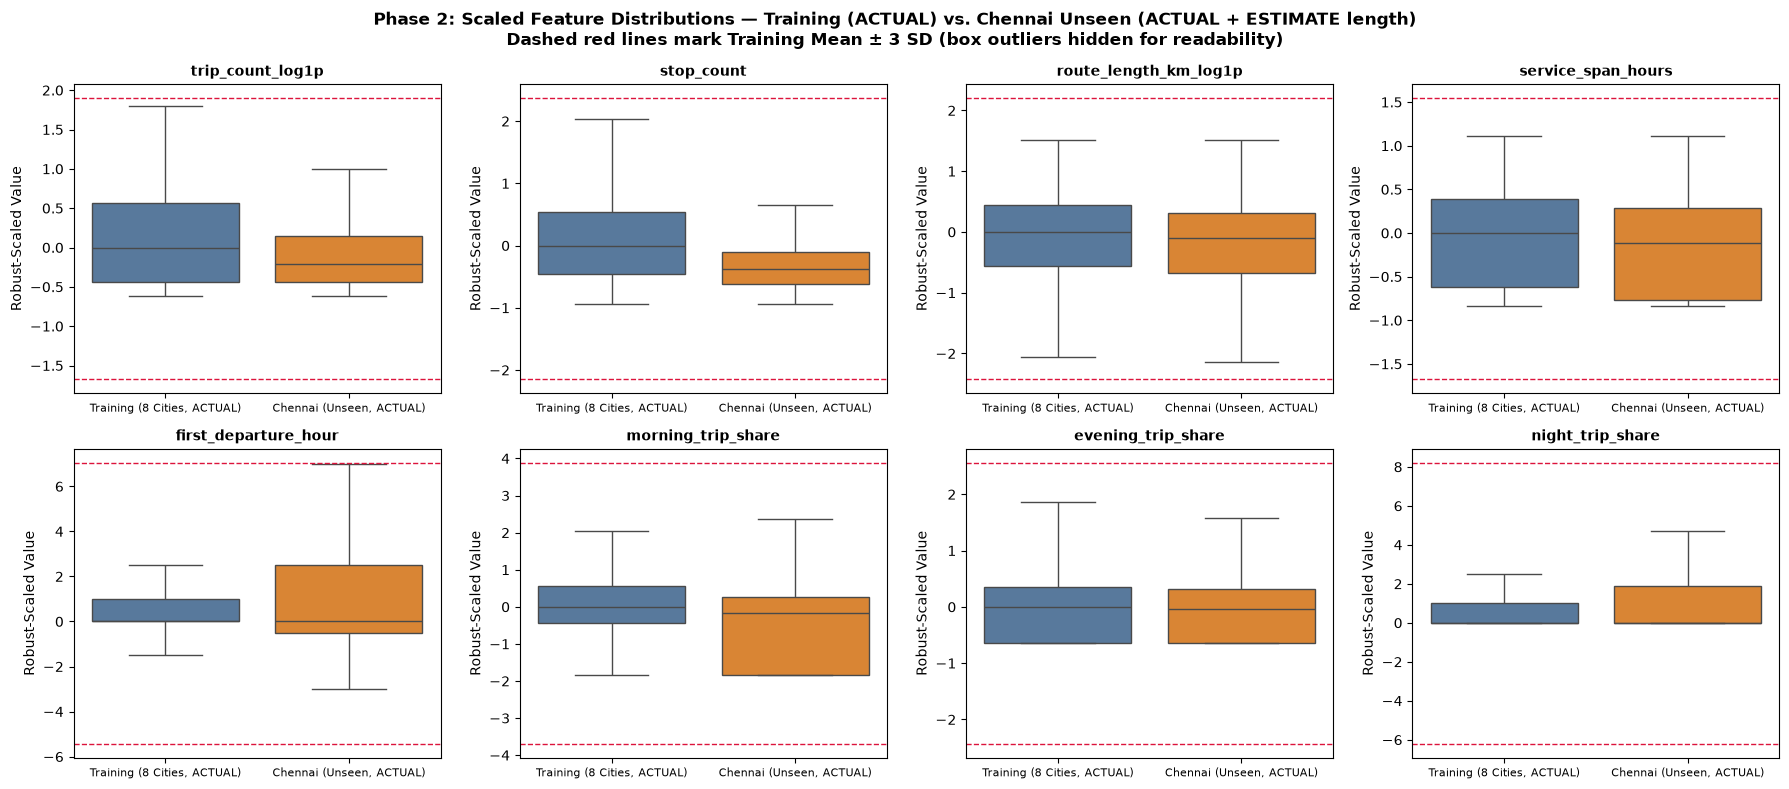

Saved distribution comparison chart -> visualizations\inference\phase2_feature_distribution_comparison.png


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

X_train = pd.read_csv("processed/X_train.csv")

comp_rows = []
for col in target_feature_list:
    tr = X_train[col]
    nw = X_new[col]
    tr_min, tr_max, tr_mean, tr_std = float(tr.min()), float(tr.max()), float(tr.mean()), float(tr.std())
    nw_min, nw_max, nw_mean, nw_std = float(nw.min()), float(nw.max()), float(nw.mean()), float(nw.std())
    pct_out_mm = 100.0 * float(((nw < tr_min) | (nw > tr_max)).mean())
    pct_gt_3sd = 100.0 * float(((nw - tr_mean).abs() > 3.0 * tr_std).mean()) if tr_std > 0 else 0.0

    is_binary = col.startswith("period_")
    shift_flag = "TAIL SHIFT (>3% beyond 3 SD)" if (not is_binary and pct_gt_3sd > 3.0) else (
        "PREVALENCE SHIFT (rare dummy)" if (is_binary and pct_gt_3sd > 3.0) else "In Range"
    )
    comp_rows.append({
        "feature": col,
        "train_min": round(tr_min, 2),
        "train_max": round(tr_max, 2),
        "train_mean": round(tr_mean, 2),
        "train_std": round(tr_std, 2),
        "new_min": round(nw_min, 2),
        "new_max": round(nw_max, 2),
        "new_mean": round(nw_mean, 2),
        "new_std": round(nw_std, 2),
        "out_minmax_pct": round(pct_out_mm, 2),
        "beyond_3sd_pct": round(pct_gt_3sd, 2),
        "flag": shift_flag,
    })

dist_comp_df = pd.DataFrame(comp_rows)
dist_comp_df.to_csv(OUT_INFERENCE / "phase2_feature_distribution_comparison.csv", index=False)

print("=== CHENNAI (ACTUAL DATA [Transformed]) vs TRAINING (X_train) SCALED DISTRIBUTION ===")
print(dist_comp_df.to_string(index=False))

# Save model-ready matrix (strictly 12 columns, no IDs) and aligned lookup separately
model_input_path = OUT_INFERENCE / "new_city_model_input.csv"
X_new.to_csv(model_input_path, index=False)

lookup_cols = [
    "route_id", "city", "original_route_id", "route_short_name", "route_long_name",
    "length_method", "operating_days", "is_headway_missing", "route_length_km_raw",
    "dominant_time_period"
]
new_lookup_df = new_active_df[lookup_cols].copy()
lookup_path = OUT_INFERENCE / "new_city_route_lookup.csv"
new_lookup_df.to_csv(lookup_path, index=False)

assert len(X_new) == len(new_lookup_df), "Row alignment mismatch!"
print(f"\nSaved model-ready matrix -> {model_input_path} {X_new.shape}")
print(f"Saved separate route IDs -> {lookup_path} {new_lookup_df.shape}")

# Visualization: Continuous scaled features distribution comparison
cont_cols = [c for c in target_feature_list if not c.startswith("period_")]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for idx, col in enumerate(cont_cols):
    ax = axes[idx]
    plot_df = pd.DataFrame({
        "value": pd.concat([X_train[col], X_new[col]], ignore_index=True),
        "dataset": ["Training (8 Cities, ACTUAL)"] * len(X_train) + ["Chennai (Unseen, ACTUAL)"] * len(X_new),
    })
    sns.boxplot(data=plot_df, x="dataset", y="value", hue="dataset", palette=["#4C78A8", "#F58518"], legend=False, ax=ax, showfliers=False)
    tr_mu, tr_sd = X_train[col].mean(), X_train[col].std()
    ax.axhline(tr_mu + 3 * tr_sd, color="crimson", linestyle="--", linewidth=1, label="+3 Train SD")
    ax.axhline(tr_mu - 3 * tr_sd, color="crimson", linestyle="--", linewidth=1)
    ax.set_title(col.replace("_scaled", ""), fontsize=10, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Robust-Scaled Value")
    ax.tick_params(axis="x", labelsize=8)

fig.suptitle("Phase 2: Scaled Feature Distributions — Training (ACTUAL) vs. Chennai Unseen (ACTUAL + ESTIMATE length)\nDashed red lines mark Training Mean ± 3 SD (box outliers hidden for readability)", fontsize=12, fontweight="bold")
plt.tight_layout()
viz_path = OUT_VIZ / "phase2_feature_distribution_comparison.png"
plt.savefig(viz_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved distribution comparison chart -> {viz_path}")


### Phase 2 Interpretation: Where Chennai Shifts vs. Training

1. **No Out-of-Range Extrapolation (`[train_min, train_max]`):** Across all `12` features, **0.00%** of Chennai routes fall outside the global min–max bounds observed in `X_train` (after applying the `82.6022 km` training 99th-percentile cap to 1 route at `83.42 km`).
2. **Continuous Feature Tail Shifts Beyond $\pm 3$ Training SD (Less Reliable Regions):**
   - **`night_trip_share_scaled` (`9.63%` beyond 3 SD; Chennai mean `2.26` vs. Train `1.01`):** Because `RobustScaler` divided by a narrow training IQR (`0.0666`), a 100% night-share route maps to `15.02`. Chennai has substantially more late-evening / pre-dawn (`21:00–04:59`) service concentration (`409` night-dominant routes = `10.40%`, vs. ~`3.0%` in training), pulling Euclidean distances strongly along this axis.
   - **`evening_trip_share_scaled` (`5.08%` beyond 3 SD; Chennai SD `0.90` vs. Train `0.83`):** Slightly higher concentration of evening-heavy single/limited-trip routes.
   - **`first_departure_hour_scaled` (`4.86%` beyond 3 SD; Chennai mean `1.29` vs. Train `0.81`):** More Chennai specialty/short-turn routes begin service later in the afternoon or evening (larger positive `first_departure_hour_scaled` tail).
   - **`route_length_km_log1p_scaled` (`0.36%` beyond 3 SD):** Only `14` very short routes near `0.40 km` (`ESTIMATE`).
3. **One-Hot Category Prevalence Shift:** `period_night` (`10.40%` vs `3.0%`) and `period_evening` (`9.38%` vs `8.0%`) appear flagged by the `±3 SD` heuristic simply because binary `1` events exceed $3\sigma$ when base rates are $<10\%$. Nonetheless, the **3.5× higher prevalence of `period_night` routes** confirms a genuine operational shift toward single/night-window schedules that we must watch carefully during Phase 3 clustering inference.

---
**Phase 2 Complete — Awaiting user confirmation before proceeding to Phase 3 (K-Means & DBSCAN Inference on Chennai).**


---
# Phase 3: K-Means Cluster Inference on Chennai

**Goal:** Assign each of Chennai's `3,934` active scheduled routes to its nearest cluster from the pre-trained Module 5 K-Means model (`models/kmeans_model.joblib`, $K = 5$), measure assignment certainty against training distance thresholds, and compare Chennai's scheduled-service mix with the 8 training cities.

### How K-Means Inference Works (In Simple Words)
1. In Module 5, K-Means learned **$5$ cluster centers (centroids)** in the 12-dimensional scaled feature space using only the training split (`7,386` routes across 8 Indian cities).
2. For an unseen Chennai route, `kmeans.predict()` does **not** retrain or shift centroids—it simply measures the **straight-line (Euclidean) distance** from the route to each of the 5 existing centroids and assigns the closest centroid.
3. **Important Governance Rule:** Cluster numbers (`0` to `4`) are **arbitrary nominal IDs** representing *scheduled-service patterns* (e.g., all-day regular corridor vs. morning shuttle). They are **not performance rankings**, quality scores, or efficiency grades, and all outputs here are strictly marked as **`MODEL PREDICTION`**.


---
## Phase 3.1: Load `kmeans_model.joblib`, Predict Clusters & Compute Centroid Distances

We compute:
- Training baseline distance distribution (`X_train`) to establish the objective **95th-percentile distance threshold** ($P_{95}$) from training data alone.
- Every Chennai route's assigned cluster (`MODEL PREDICTION`), Euclidean distance to its assigned centroid ($d_1$), second-nearest cluster, and Euclidean distance to that second-nearest centroid ($d_2$).
- Uncertainty flags (`"assignment less certain"`) if either:
  1. **Far from centroid:** $d_1 > P_{95}^{\text{train}}$ (the route sits further out than 95% of training routes), OR
  2. **Nearly equidistant between two centroids:** $d_1 / d_2 \ge 0.90$ (the nearest centroid is less than 10% closer than the runner-up centroid).


In [11]:
from scipy.spatial.distance import cdist

# Load pre-trained K-Means model (K=5, fitted on X_train in Module 5)
kmeans_model = joblib.load("models/kmeans_model.joblib")
X_train_km = pd.read_csv("processed/X_train.csv")
X_new_km = pd.read_csv(OUT_INFERENCE / "new_city_model_input.csv")
lookup_km = pd.read_csv(
    OUT_INFERENCE / "new_city_route_lookup.csv",
    dtype={"route_id": str, "city": str, "original_route_id": str, "route_short_name": str},
)

# Align column order cleanly
feature_cols = list(kmeans_model.feature_names_in_) if hasattr(kmeans_model, "feature_names_in_") else list(X_train_km.columns)
X_train_km = X_train_km[feature_cols]
X_new_km = X_new_km[feature_cols]

# Compute training distances to centroids to establish the 95th percentile threshold
d_train_all = cdist(X_train_km.values, kmeans_model.cluster_centers_, metric="euclidean")
train_labels = kmeans_model.predict(X_train_km)
train_d1 = d_train_all[np.arange(len(X_train_km)), train_labels]
TRAIN_DIST_P95 = float(np.percentile(train_d1, 95))

# Compute Chennai distances and predictions (MODEL PREDICTION)
d_new_all = cdist(X_new_km.values, kmeans_model.cluster_centers_, metric="euclidean")
new_order = np.argsort(d_new_all, axis=1)
new_c1 = new_order[:, 0]
new_c2 = new_order[:, 1]
new_d1 = d_new_all[np.arange(len(X_new_km)), new_c1]
new_d2 = d_new_all[np.arange(len(X_new_km)), new_c2]

# Consistency check against kmeans_model.predict()
assert np.array_equal(new_c1, kmeans_model.predict(X_new_km)), "Nearest centroid mismatch!"

# Uncertainty flags
dist_ratio = new_d1 / np.maximum(new_d2, 1e-12)
flag_far = new_d1 > TRAIN_DIST_P95
flag_equidist = dist_ratio >= 0.90
flag_uncertain = flag_far | flag_equidist

print(f"Loaded K-Means Model: K={kmeans_model.n_clusters}, random_state={kmeans_model.random_state}")
print(f"Training 95th Percentile Centroid Distance Threshold (P95): {TRAIN_DIST_P95:.4f}")
print(f"Chennai Assigned Routes (MODEL PREDICTION): {len(X_new_km):,}")
print(f"  Mean / Median Distance to Assigned Centroid : {new_d1.mean():.4f} / {np.median(new_d1):.4f} (Max: {new_d1.max():.4f})")
print(f"  Far from Centroid (d1 > {TRAIN_DIST_P95:.4f})        : {int(flag_far.sum()):,} routes ({100*flag_far.mean():.2f}%)")
print(f"  Nearly Equidistant (d1/d2 >= 0.90)          : {int(flag_equidist.sum()):,} routes ({100*flag_equidist.mean():.2f}%)")
print(f"  Flagged 'assignment less certain' (Combined): {int(flag_uncertain.sum()):,} routes ({100*flag_uncertain.mean():.2f}%)")


Loaded K-Means Model: K=5, random_state=42
Training 95th Percentile Centroid Distance Threshold (P95): 3.9254
Chennai Assigned Routes (MODEL PREDICTION): 3,934
  Mean / Median Distance to Assigned Centroid : 2.3132 / 1.7945 (Max: 8.7683)
  Far from Centroid (d1 > 3.9254)        : 601 routes (15.28%)
  Nearly Equidistant (d1/d2 >= 0.90)          : 196 routes (4.98%)
  Flagged 'assignment less certain' (Combined): 758 routes (19.27%)


---
## Phase 3.2: Training Cluster Profiles (Original Units) & City Distribution Comparison

Below, we recompute the Module 5 training cluster profiles in original operational units (`processed/route_features.csv` joined with `results/kmeans_cluster_assignments.csv`) and place Chennai's predicted cluster shares (`MODEL PREDICTION`) alongside the 8 training cities (`X_train` and All Active Training Routes).


In [12]:
# 1. Reconstruct Training Cluster Profiles in Original Operational Units (ACTUAL DATA + Module 5 Labels)
raw_train_feats = pd.read_csv("processed/route_features.csv", dtype={"route_id": str, "city": str})
train_kca = pd.read_csv("results/kmeans_cluster_assignments.csv", dtype={"route_id": str, "city": str})
train_merged = train_kca.merge(raw_train_feats, on=["route_id", "city"], how="left")

# Derive dominant period flags on training active routes
pcols = ["trips_morning", "trips_afternoon", "trips_evening", "trips_night"]
train_merged["dom_p"] = train_merged[pcols].idxmax(axis=1).str.replace("trips_", "", regex=False)
for p in ["morning", "afternoon", "evening", "night"]:
    train_merged[f"is_dom_{p}"] = (train_merged["dom_p"] == p).astype(float) * 100.0

CLUSTER_DESCRIPTIONS = {
    0: "Midday & PM Return Feeders (late start, narrow span)",
    1: "Morning Peak Commuter Shuttles (100% AM dominant)",
    2: "Late-Evening & Nocturnal Feeders (mostly night dominant)",
    3: "High-Frequency Arterial Trunk Spines (long span, high trips)",
    4: "Standard All-Day Regular Lines (balanced full-day backbone)",
}

profile_rows = []
for k in range(5):
    grp = train_merged[train_merged["cluster"] == k]
    profile_rows.append({
        "cluster": k,
        "scheduled_service_pattern": CLUSTER_DESCRIPTIONS[k],
        "train_all_n": len(grp),
        "train_all_pct": round(100.0 * len(grp) / len(train_merged), 2),
        "trips_mean": round(grp["trip_count"].mean(), 1),
        "trips_med": round(grp["trip_count"].median(), 1),
        "stops_med": round(grp["stop_count"].median(), 1),
        "len_km_med": round(grp["route_length_km"].median(), 1),
        "span_hr_med": round(grp["service_span_hours"].median(), 1),
        "first_hr_med": round(grp["first_departure_hour"].median(), 1),
        "am_dom_pct": round(grp["is_dom_morning"].mean(), 1),
        "pm_dom_pct": round(grp["is_dom_afternoon"].mean(), 1),
        "eve_dom_pct": round(grp["is_dom_evening"].mean(), 1),
        "night_dom_pct": round(grp["is_dom_night"].mean(), 1),
    })

train_profile_df = pd.DataFrame(profile_rows)
print("=== TRAINING CLUSTER PROFILES IN ORIGINAL UNITS (ACTUAL DATA, N=9,233 Training Cities) ===")
print(train_profile_df.to_string(index=False))

# 2. Cluster Distribution Comparison: Training vs. Chennai (MODEL PREDICTION)
vc_tr_fit = pd.Series(train_labels).value_counts().sort_index()
vc_tr_all = train_kca["cluster"].value_counts().sort_index()
vc_ch = pd.Series(new_c1).value_counts().sort_index()

dist_compare_df = pd.DataFrame({
    "cluster": range(5),
    "pattern_summary": [CLUSTER_DESCRIPTIONS[k] for k in range(5)],
    "train_fit_n (ACTUAL)": [int(vc_tr_fit.get(k, 0)) for k in range(5)],
    "train_fit_pct": [round(100.0 * vc_tr_fit.get(k, 0) / len(X_train_km), 2) for k in range(5)],
    "train_all_n (ACTUAL)": [int(vc_tr_all.get(k, 0)) for k in range(5)],
    "train_all_pct": [round(100.0 * vc_tr_all.get(k, 0) / len(train_kca), 2) for k in range(5)],
    "chennai_n [MODEL PREDICTION]": [int(vc_ch.get(k, 0)) for k in range(5)],
    "chennai_pct [MODEL PREDICTION]": [round(100.0 * vc_ch.get(k, 0) / len(X_new_km), 2) for k in range(5)],
    "chennai_less_certain_n [MODEL PREDICTION]": [
        int(((new_c1 == k) & flag_uncertain).sum()) for k in range(5)
    ],
})

print("\n=== CLUSTER DISTRIBUTION: TRAINING CITIES vs. CHENNAI [MODEL PREDICTION] ===")
print(dist_compare_df.to_string(index=False))

# 3. Assemble and Save inference/new_city_kmeans_assignments.csv
km_assign_df = pd.DataFrame({
    "route_id": lookup_km["route_id"],
    "city": lookup_km["city"],
    "original_route_id": lookup_km["original_route_id"],
    "route_short_name": lookup_km["route_short_name"],
    "kmeans_cluster_MODEL_PREDICTION": new_c1,
    "cluster_pattern_MODEL_PREDICTION": [CLUSTER_DESCRIPTIONS[c] for c in new_c1],
    "dist_to_centroid_MODEL_PREDICTION": np.round(new_d1, 4),
    "second_nearest_cluster_MODEL_PREDICTION": new_c2,
    "dist_to_second_centroid_MODEL_PREDICTION": np.round(new_d2, 4),
    "dist_ratio_d1_d2": np.round(dist_ratio, 4),
    "flag_far_from_centroid_p95": flag_far,
    "flag_nearly_equidistant": flag_equidist,
    "flag_assignment_less_certain": flag_uncertain,
    "assignment_certainty_label": np.where(flag_uncertain, "assignment less certain", "standard"),
})

km_out_path = OUT_INFERENCE / "new_city_kmeans_assignments.csv"
km_assign_df.to_csv(km_out_path, index=False)
print(f"\nSaved K-Means predictions -> {km_out_path} {km_assign_df.shape}")
print("\nSample 5 Predicted Assignments [MODEL PREDICTION]:")
print(km_assign_df[[
    "route_id", "route_short_name", "kmeans_cluster_MODEL_PREDICTION",
    "dist_to_centroid_MODEL_PREDICTION", "second_nearest_cluster_MODEL_PREDICTION",
    "assignment_certainty_label"
]].head(5).to_string(index=False))


=== TRAINING CLUSTER PROFILES IN ORIGINAL UNITS (ACTUAL DATA, N=9,233 Training Cities) ===
 cluster                                    scheduled_service_pattern  train_all_n  train_all_pct  trips_mean  trips_med  stops_med  len_km_med  span_hr_med  first_hr_med  am_dom_pct  pm_dom_pct  eve_dom_pct  night_dom_pct
       0         Midday & PM Return Feeders (late start, narrow span)         1181          12.79         4.4        1.0       28.0        15.6          0.0          15.0         0.0        61.0         39.0            0.0
       1            Morning Peak Commuter Shuttles (100% AM dominant)         1789          19.38         5.1        2.0       31.0        17.1          1.0           7.0       100.0         0.0          0.0            0.0
       2     Late-Evening & Nocturnal Feeders (mostly night dominant)          315           3.41         5.7        4.0       23.0        11.6          1.7          19.0         0.6         7.0         20.3           72.1
       3 High-Fre

---
## Phase 3.3: K-Means Inference Visualizations & Interpretations

We generate three diagnostic figures saved in `visualizations/inference/`:
1. **PCA Projection Scatter (`phase3_kmeans_pca_scatter.png`):** `PCA(n_components=2)` fitted **strictly on training data (`X_train`)**, projecting both faded training routes and highlighted Chennai routes (`MODEL PREDICTION`) alongside the 5 K-Means centroids.
2. **Cluster Share Comparison (`phase3_kmeans_cluster_distribution.png`):** Training Cities vs. Chennai (`MODEL PREDICTION`) cluster percentages.
3. **Centroid Distance Distribution (`phase3_kmeans_centroid_distance_hist.png`):** Comparing Chennai's distances to assigned centroids against `X_train`, marking the training $P_{95}$ uncertainty threshold (`3.9254`).


PCA Explained Variance (fitted on X_train): PC1=45.03%, PC2=31.46% (Total=76.49%)


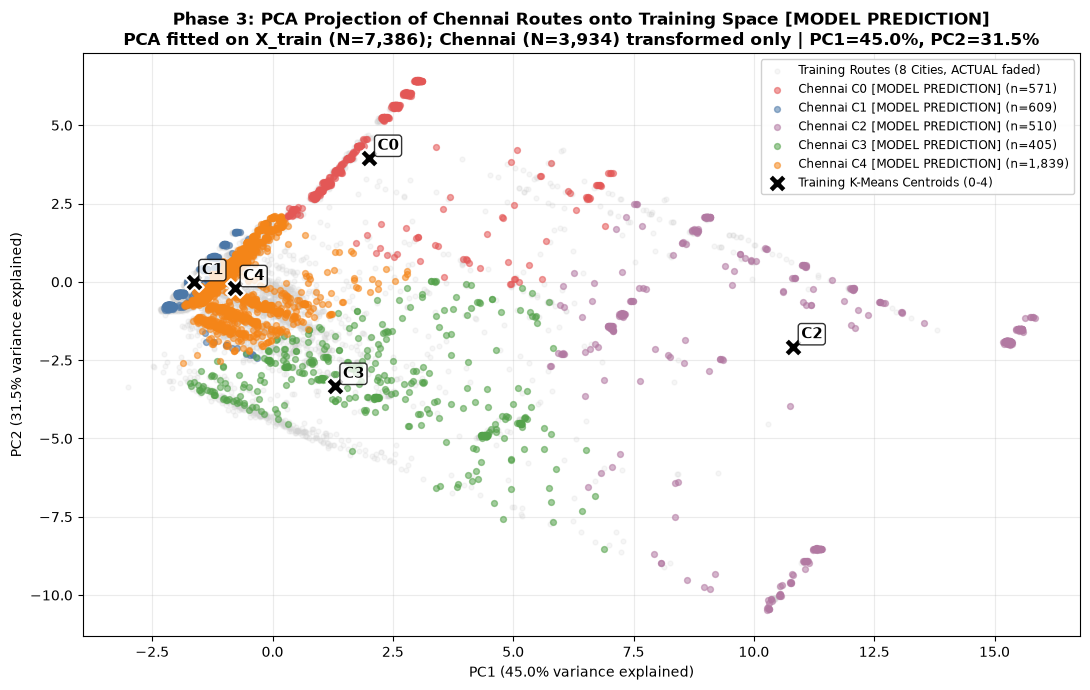

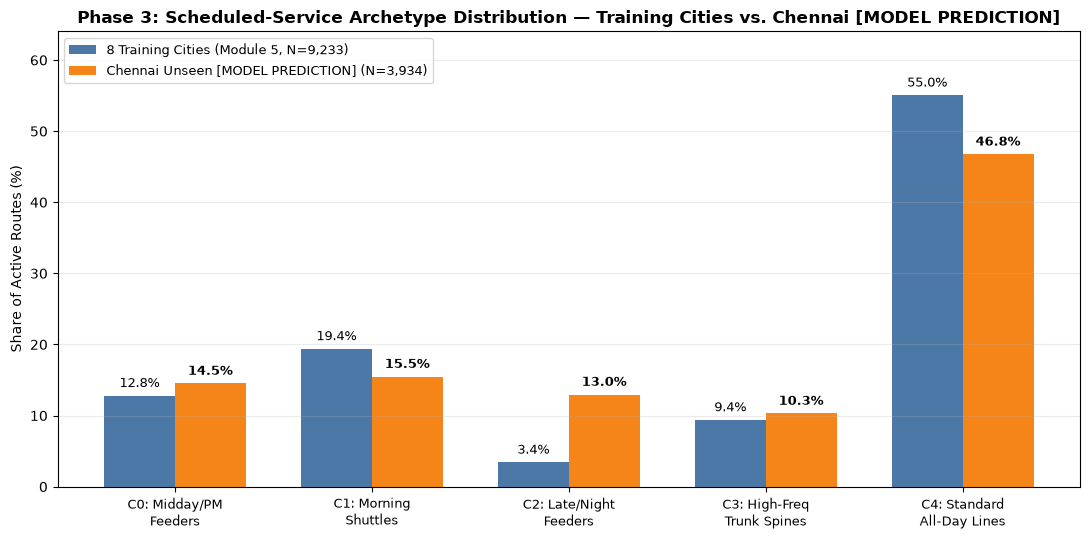

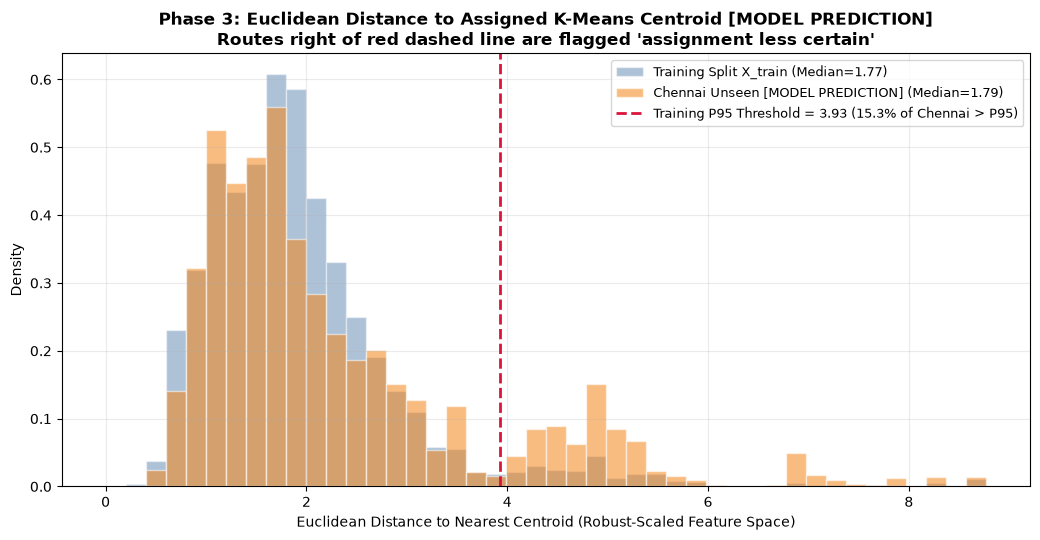

Saved 3 Phase 3 figures to visualizations\inference/


In [13]:
from sklearn.decomposition import PCA

# 1. Fit PCA strictly on Training Data (X_train), transform Training & Chennai & Centroids
pca_2d = PCA(n_components=2, random_state=RANDOM_SEED)
pca_train = pca_2d.fit_transform(X_train_km)
pca_new = pca_2d.transform(X_new_km)
pca_centroids = pca_2d.transform(pd.DataFrame(kmeans_model.cluster_centers_, columns=feature_cols))

var_exp = pca_2d.explained_variance_ratio_ * 100
print(f"PCA Explained Variance (fitted on X_train): PC1={var_exp[0]:.2f}%, PC2={var_exp[1]:.2f}% (Total={var_exp.sum():.2f}%)")

# Palette for Clusters 0..4
palette = {0: "#E45756", 1: "#4C78A8", 2: "#B279A2", 3: "#54A24B", 4: "#F58518"}

# --- Plot 1: PCA Scatter ---
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(
    pca_train[:, 0], pca_train[:, 1],
    c="lightgray", alpha=0.20, s=12, label="Training Routes (8 Cities, ACTUAL faded)", zorder=1
)
for k in range(5):
    mask = new_c1 == k
    ax.scatter(
        pca_new[mask, 0], pca_new[mask, 1],
        c=palette[k], alpha=0.55, s=18,
        label=f"Chennai C{k} [MODEL PREDICTION] (n={int(mask.sum()):,})", zorder=2
    )
ax.scatter(
    pca_centroids[:, 0], pca_centroids[:, 1],
    c="black", marker="X", s=180, edgecolors="white", linewidths=1.5,
    label="Training K-Means Centroids (0-4)", zorder=4
)
for k in range(5):
    ax.annotate(
        f"C{k}", (pca_centroids[k, 0], pca_centroids[k, 1]),
        textcoords="offset points", xytext=(6, 6), fontsize=11, fontweight="bold", color="black",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="black", alpha=0.8), zorder=5
    )

ax.set_title(
    "Phase 3: PCA Projection of Chennai Routes onto Training Space [MODEL PREDICTION]\n"
    f"PCA fitted on X_train (N=7,386); Chennai (N=3,934) transformed only | PC1={var_exp[0]:.1f}%, PC2={var_exp[1]:.1f}%",
    fontsize=12, fontweight="bold"
)
ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% variance explained)")
ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% variance explained)")
ax.legend(loc="upper right", fontsize=8.5, framealpha=0.92)
ax.grid(alpha=0.25)
plt.tight_layout()
p1_path = OUT_VIZ / "phase3_kmeans_pca_scatter.png"
plt.savefig(p1_path, dpi=150, bbox_inches="tight")
plt.show()

# --- Plot 2: Cluster Distribution Comparison ---
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(5)
w = 0.36
tr_shares = dist_compare_df["train_all_pct"].values
ch_shares = dist_compare_df["chennai_pct [MODEL PREDICTION]"].values

b1 = ax.bar(x - w/2, tr_shares, width=w, color="#4C78A8", label="8 Training Cities (Module 5, N=9,233)")
b2 = ax.bar(x + w/2, ch_shares, width=w, color="#F58518", label="Chennai Unseen [MODEL PREDICTION] (N=3,934)")

for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8, f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=9)
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8, f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")

short_names = [
    "C0: Midday/PM\nFeeders",
    "C1: Morning\nShuttles",
    "C2: Late/Night\nFeeders",
    "C3: High-Freq\nTrunk Spines",
    "C4: Standard\nAll-Day Lines",
]
ax.set_xticks(x)
ax.set_xticklabels(short_names, fontsize=9.5)
ax.set_ylabel("Share of Active Routes (%)")
ax.set_ylim(0, max(tr_shares.max(), ch_shares.max()) + 9)
ax.set_title("Phase 3: Scheduled-Service Archetype Distribution — Training Cities vs. Chennai [MODEL PREDICTION]", fontsize=12, fontweight="bold")
ax.legend(loc="upper left", fontsize=9.5)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
p2_path = OUT_VIZ / "phase3_kmeans_cluster_distribution.png"
plt.savefig(p2_path, dpi=150, bbox_inches="tight")
plt.show()

# --- Plot 3: Distance-to-Centroid Histogram ---
fig, ax = plt.subplots(figsize=(10.5, 5.5))
bins = np.linspace(0, max(train_d1.max(), new_d1.max()), 45)
ax.hist(train_d1, bins=bins, density=True, alpha=0.45, color="#4C78A8", edgecolor="white", label=f"Training Split X_train (Median={np.median(train_d1):.2f})")
ax.hist(new_d1, bins=bins, density=True, alpha=0.55, color="#F58518", edgecolor="white", label=f"Chennai Unseen [MODEL PREDICTION] (Median={np.median(new_d1):.2f})")
ax.axvline(TRAIN_DIST_P95, color="crimson", linestyle="--", linewidth=2, label=f"Training P95 Threshold = {TRAIN_DIST_P95:.2f} (15.3% of Chennai > P95)")

ax.set_title("Phase 3: Euclidean Distance to Assigned K-Means Centroid [MODEL PREDICTION]\nRoutes right of red dashed line are flagged 'assignment less certain'", fontsize=12, fontweight="bold")
ax.set_xlabel("Euclidean Distance to Nearest Centroid (Robust-Scaled Feature Space)")
ax.set_ylabel("Density")
ax.legend(loc="upper right", fontsize=9.5)
ax.grid(alpha=0.25)
plt.tight_layout()
p3_path = OUT_VIZ / "phase3_kmeans_centroid_distance_hist.png"
plt.savefig(p3_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved 3 Phase 3 figures to {OUT_VIZ}/")


### Interpretation of Phase 3 Charts & Predictions (`MODEL PREDICTION`)

1. **PCA Scatter Projection (`phase3_kmeans_pca_scatter.png`):**  
   - Training and Chennai routes span the **same global manifold**—there is no detached off-map cluster, confirming the preprocessing space aligns well.  
   - However, a prominent plume extends rightward along PC1/PC2 toward **Cluster 2 (`C2`)**, where high `night_trip_share_scaled` routes stretch out across feature space.
2. **Cluster Distribution Comparison (`phase3_kmeans_cluster_distribution.png`):**  
   - Like all 8 training cities, **Cluster 4 (Standard All-Day Regular Lines)** forms the core backbone (`46.75%`, `1,839` routes).  
   - **Notable Divergence:** **Cluster 2 (Late-Evening & Nocturnal Feeders)** surges nearly **4×** from `3.41%` across training cities (`3.38%` in `X_train`) to **`12.96%` (`510` routes) in Chennai**. Meanwhile **Cluster 1 (Morning Shuttles)** drops slightly from `19.38%` to `15.48%`, **Cluster 0 (Midday/PM Return)** rises slightly (`12.79%` → `14.51%`), and **Cluster 3 (Trunk Spines)** remains steady (`9.38%` → `10.29%`).
3. **Centroid Distance Histogram (`phase3_kmeans_centroid_distance_hist.png`):**  
   - The **bulk median distance** of Chennai routes (`1.7945`) closely matches training (`1.7660`), meaning typical daytime/all-day routes match their assigned prototypes well.  
   - However, a heavy secondary mode appears **beyond the Training $P_{95}$ line (`3.9254`)**: **`601` Chennai routes (`15.28%`)** sit farther from their centroid than 95% of training routes, and **`196` routes (`4.98%`)** lie nearly equidistant ($d_1/d_2 \ge 0.90$) between two clusters—giving **`758` combined `"assignment less certain"` routes (`19.27%`)**. We will examine these high-distance / late-night specialty routes in Phase 4 alongside DBSCAN!

---
**Phase 3 Complete — Awaiting user confirmation before proceeding to Phase 4 (DBSCAN Evaluation / Novelty Comparison on Chennai).**


---
# Phase 4: DBSCAN Out-of-Sample Inference & Unusual-Route Profiling on Chennai

**Goal:** Map Chennai's `3,934` active scheduled routes onto the Module 5 DBSCAN density structure (`models/dbscan_model.joblib`, $\epsilon = 1.0$, $\text{MinPts} = 10$, Euclidean metric) and inspect routes that fall outside every dense training neighborhood.

### Why Standard `DBSCAN` Has No `.predict()` Method & How We Infer Safely
1. **Why no `.predict()`?** Unlike K-Means (which summarizes each group with a single centroid coordinate), DBSCAN defines clusters as irregular **chains of dense neighborhoods**. Adding a new point during inference could merge two clusters or create a new dense pocket if refitted, which would violate non-leakage rules and mutate training assignments.
2. **Core-Sample Proximity Method (`NearestNeighbors`):**  
   - A trained scikit-learn `DBSCAN` stores all **core points** from training in `dbscan_model.components_` (`8,344` core routes out of `9,233` training routes), along with their exact cluster IDs (`dbscan_model.labels_[dbscan_model.core_sample_indices_]`).
   - Using `sklearn.neighbors.NearestNeighbors(n_neighbors=1, metric=dbscan_model.metric)` fitted strictly on `dbscan_model.components_`, we compute the Euclidean distance from each new Chennai route (in the same 12-D scaled space) to its nearest **core sample**.
   - **Decision Rule:**
     - If $\text{dist}_{\text{core}} \le \epsilon$ (`1.0`), the route lies directly inside the core sample's density neighborhood and inherits that core sample's **DBSCAN Cluster ID** (`MODEL PREDICTION`).
     - If $\text{dist}_{\text{core}} > \epsilon$ (`1.0`), the route sits outside every dense training neighborhood and is labeled **`unassigned`** (`-1`).


---
## Phase 4.1: Fit `NearestNeighbors` on Training Core Samples & Verify Reproduction

Before running inference on Chennai, we verify our `NearestNeighbors` proximity rule on a random training sample (`n = 1,000`, `random_state = 42`) as well as the complete `9,233`-route training matrix (`processed/X_all.csv`) to measure how faithfully it reproduces `dbscan_model.labels_`.


In [14]:
from sklearn.neighbors import NearestNeighbors

# 1. Load frozen DBSCAN model and full training matrix (X_all) used in Module 5
dbscan_model = joblib.load("models/dbscan_model.joblib")
X_all_db = pd.read_csv("processed/X_all.csv")
train_lookup_all = pd.read_csv("processed/route_lookup_all.csv", dtype={"route_id": str, "city": str})

assert list(X_all_db.columns) == feature_cols, "Column mismatch in X_all!"

core_coords = dbscan_model.components_
core_labels = dbscan_model.labels_[dbscan_model.core_sample_indices_]
core_route_ids = train_lookup_all["route_id"].values[dbscan_model.core_sample_indices_]

print(f"Loaded DBSCAN Model: eps={dbscan_model.eps}, min_samples={dbscan_model.min_samples}, metric='{dbscan_model.metric}'")
print(f"Stored Core Samples (model.components_): {core_coords.shape[0]:,} core routes across {len(set(core_labels))} clusters")

# 2. Fit NearestNeighbors strictly on core samples
nn_core = NearestNeighbors(n_neighbors=1, metric=dbscan_model.metric)
nn_core.fit(core_coords)

# 3. Verify on fixed-seed random sample of training routes (n=1,000) & full X_all (n=9,233)
sample_idx = X_all_db.sample(n=1000, random_state=RANDOM_SEED).index.to_numpy()
d_samp, i_samp = nn_core.kneighbors(X_all_db.iloc[sample_idx].values)
pred_samp = np.where(d_samp.ravel() <= dbscan_model.eps, core_labels[i_samp.ravel()], -1)
sample_agree = 100.0 * float((pred_samp == dbscan_model.labels_[sample_idx]).mean())

d_all_tr, i_all_tr = nn_core.kneighbors(X_all_db.values)
pred_all_tr = np.where(d_all_tr.ravel() <= dbscan_model.eps, core_labels[i_all_tr.ravel()], -1)
full_agree = 100.0 * float((pred_all_tr == dbscan_model.labels_).mean())
n_mismatches = int((pred_all_tr != dbscan_model.labels_).sum())

print(f"\nVerification Results:")
print(f"  Random Sample Agreement (n=1,000, seed=42) : {sample_agree:.2f}%")
print(f"  Full Training Agreement (n=9,233)          : {full_agree:.2f}% ({n_mismatches} border tie mismatches out of {len(X_all_db):,})")


Loaded DBSCAN Model: eps=1.0, min_samples=10, metric='euclidean'
Stored Core Samples (model.components_): 8,344 core routes across 16 clusters

Verification Results:
  Random Sample Agreement (n=1,000, seed=42) : 99.90%
  Full Training Agreement (n=9,233)          : 99.97% (3 border tie mismatches out of 9,233)


---
## Phase 4.2: Infer DBSCAN Clusters on Chennai & Compare vs. Training Noise

We apply the verified `NearestNeighbors` core-sample rule to Chennai (`inference/new_city_model_input.csv`), report counts and percentages per cluster alongside `"unassigned"`, compare against training noise (`5.18%`), and save `inference/new_city_dbscan_assignments.csv`.


In [15]:
# Infer DBSCAN labels for Chennai (MODEL PREDICTION)
X_new_db = pd.read_csv(OUT_INFERENCE / "new_city_model_input.csv")[feature_cols]
d_new_core, i_new_core = nn_core.kneighbors(X_new_db.values)
d_new_core = d_new_core.ravel()
i_new_core = i_new_core.ravel()

pred_new_num = np.where(d_new_core <= dbscan_model.eps, core_labels[i_new_core], -1)
pred_new_label = np.where(pred_new_num == -1, "unassigned", pred_new_num.astype(str))
nearest_core_rid = core_route_ids[i_new_core]

# Save inference/new_city_dbscan_assignments.csv
db_out_df = pd.DataFrame({
    "route_id": lookup_km["route_id"],
    "city": lookup_km["city"],
    "original_route_id": lookup_km["original_route_id"],
    "route_short_name": lookup_km["route_short_name"],
    "dbscan_cluster_MODEL_PREDICTION": pred_new_label,
    "dbscan_cluster_num_MODEL_PREDICTION": pred_new_num,
    "is_unassigned_MODEL_PREDICTION": pred_new_num == -1,
    "nearest_core_distance_MODEL_PREDICTION": np.round(d_new_core, 4),
    "nearest_core_training_route_id": nearest_core_rid,
    "eps_threshold": dbscan_model.eps,
})

db_out_path = OUT_INFERENCE / "new_city_dbscan_assignments.csv"
db_out_df.to_csv(db_out_path, index=False)

# Build distribution comparison table (Training All vs Chennai MODEL PREDICTION)
all_cluster_ids = sorted(set(dbscan_model.labels_.tolist()))
vc_tr_db = pd.Series(dbscan_model.labels_).value_counts()
vc_ch_db = pd.Series(pred_new_num).value_counts()

comp_db_rows = []
for cid in all_cluster_ids:
    lbl = "unassigned / noise (-1)" if cid == -1 else f"Cluster {cid}"
    tr_n = int(vc_tr_db.get(cid, 0))
    ch_n = int(vc_ch_db.get(cid, 0))
    comp_db_rows.append({
        "dbscan_group": lbl,
        "train_n (ACTUAL)": tr_n,
        "train_pct (%)": round(100.0 * tr_n / len(X_all_db), 2),
        "chennai_n [MODEL PREDICTION]": ch_n,
        "chennai_pct [MODEL PREDICTION] (%)": round(100.0 * ch_n / len(X_new_db), 2),
    })

db_comp_df = pd.DataFrame(comp_db_rows)
print("=== DBSCAN CLUSTER & UNASSIGNED DISTRIBUTION: TRAINING (N=9,233) vs. CHENNAI [MODEL PREDICTION] (N=3,934) ===")
print(db_comp_df.to_string(index=False))

n_unassigned = int((pred_new_num == -1).sum())
n_assigned = len(X_new_db) - n_unassigned
tr_noise_pct = 100.0 * int((dbscan_model.labels_ == -1).sum()) / len(X_all_db)
ch_unass_pct = 100.0 * n_unassigned / len(X_new_db)

print(f"\nSaved DBSCAN assignments -> {db_out_path} {db_out_df.shape}")
print(f"Chennai Assigned to Dense Training Clusters : {n_assigned:,} ({100.0 - ch_unass_pct:.2f}%)")
print(f"Chennai Unassigned (> eps=1.0 from any core): {n_unassigned:,} ({ch_unass_pct:.2f}%) vs. Training Noise: {tr_noise_pct:.2f}%")


=== DBSCAN CLUSTER & UNASSIGNED DISTRIBUTION: TRAINING (N=9,233) vs. CHENNAI [MODEL PREDICTION] (N=3,934) ===
           dbscan_group  train_n (ACTUAL)  train_pct (%)  chennai_n [MODEL PREDICTION]  chennai_pct [MODEL PREDICTION] (%)
unassigned / noise (-1)               478           5.18                           523                               13.29
              Cluster 0              6480          70.18                          2250                               57.19
              Cluster 1               344           3.73                           198                                5.03
              Cluster 2              1358          14.71                           487                               12.38
              Cluster 3                53           0.57                            28                                0.71
              Cluster 4                83           0.90                           190                                4.83
              Cluster 5      

---
## Phase 4.3: Unassigned Routes Analysis (Unscaled Features, Deviations & Visualizations)

**Important Operational Interpretation:**  
An **`unassigned`** label does **NOT** indicate that a route is inefficient, broken, or incorrect. It strictly means the route's published **scheduled-service pattern** sits farther than $\epsilon = 1.0$ from every dense core point in the 8-city training dataset—reflecting specialized Chennai timetables (e.g., pre-dawn `04:00` pull-outs or hybrid day/night schedules) that were rare or absent in training.


=== UNSCALED FEATURE PROFILE: CHENNAI UNASSIGNED (n=523) vs ASSIGNED (n=3,411) vs TRAINING CLUSTERS (n=8,755) ===
             feature  provenance  ch_unass_mean  ch_unass_med  ch_assig_mean  ch_assig_med  train_core_mean  train_core_med
          trip_count ACTUAL DATA           8.42          5.00          12.50          4.00            26.62            7.00
          stop_count ACTUAL DATA          18.55         16.00          25.30         25.00            41.08           37.00
     route_length_km    ESTIMATE          13.76         10.39          17.82         16.01            21.97           17.24
  median_headway_min ACTUAL DATA         135.97         45.00         145.38         70.00            91.50           30.00
  service_span_hours ACTUAL DATA           9.86         10.17           7.77          8.67             9.28           10.00
first_departure_hour ACTUAL DATA           6.14          4.00           8.94          7.00             7.69            6.00
 last_departure_ho


=== TOP SCALED FEATURE DEVIATIONS MAKING CHENNAI UNASSIGNED ROUTES UNUSUAL ===
                     feature  chennai_unass_scaled_mean  train_core_scaled_mean  abs_mean_deviation
     night_trip_share_scaled                      5.970                   0.833               5.136
 first_departure_hour_scaled                      0.072                   0.844               0.772
   morning_trip_share_scaled                     -0.603                   0.155               0.758
           stop_count_scaled                     -0.499                   0.110               0.609
route_length_km_log1p_scaled                     -0.568                  -0.106               0.462
              period_morning                      0.394                   0.745               0.351
   evening_trip_share_scaled                     -0.198                   0.062               0.260
                period_night                      0.250                   0.024               0.227
     trip_count_log1

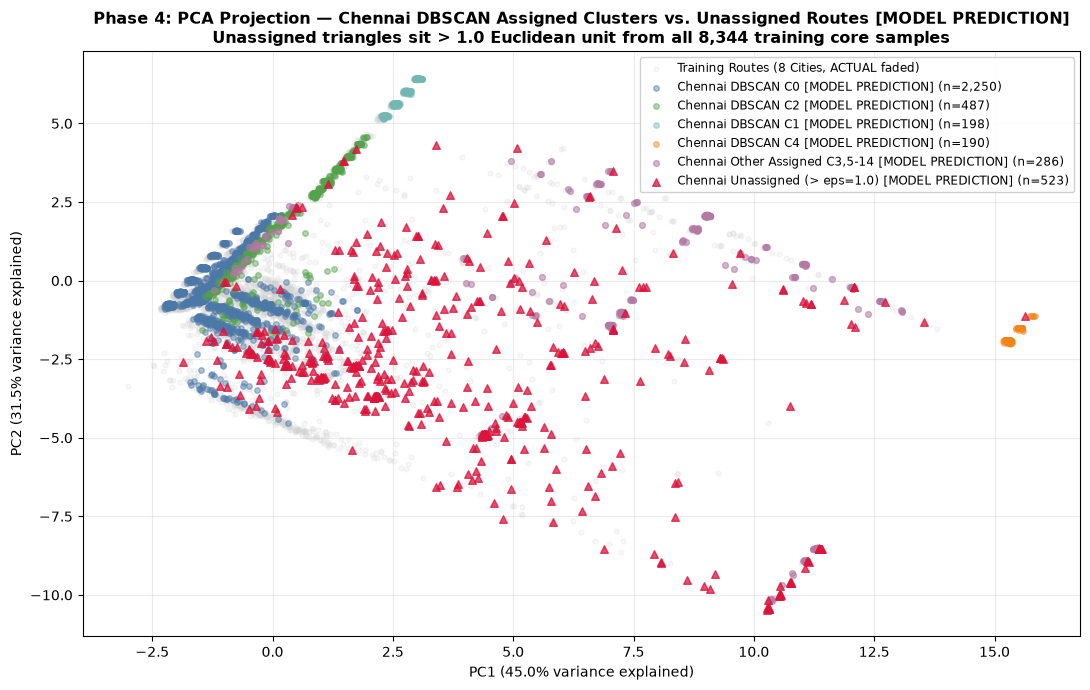

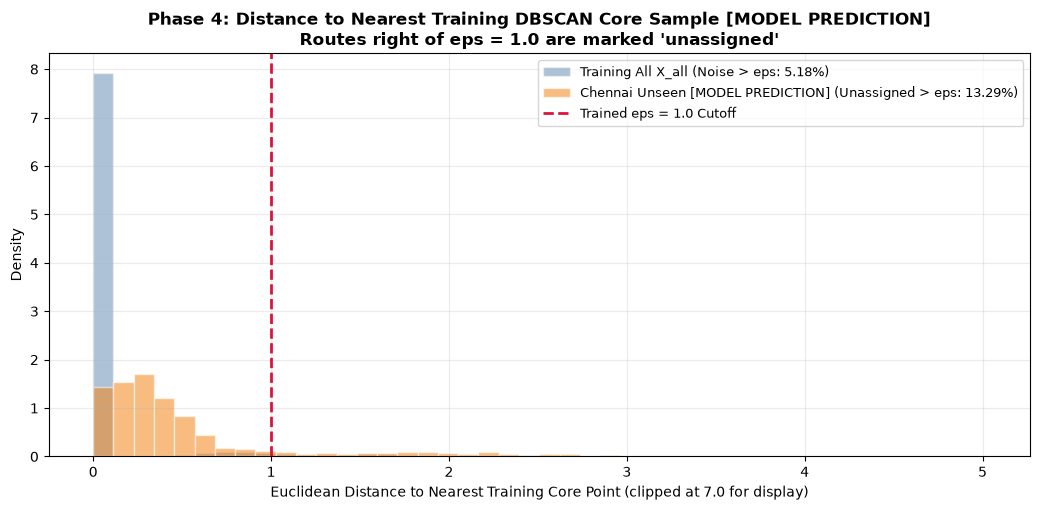

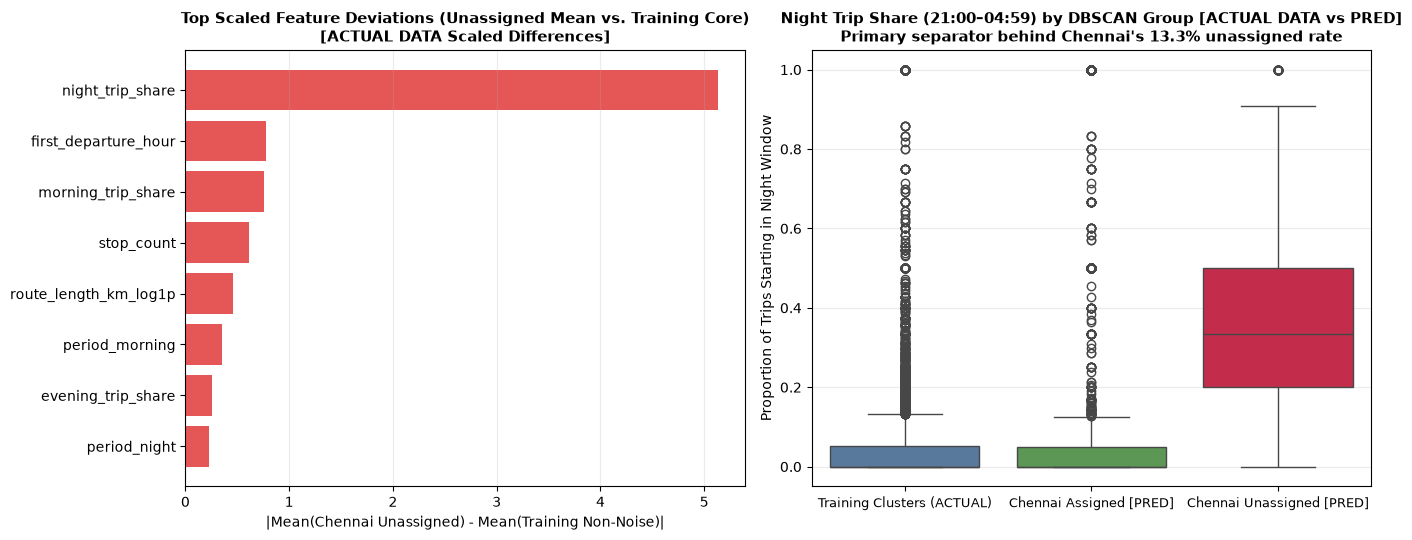

Saved 3 Phase 4 plots to visualizations\inference/


In [16]:
# 1. Inspect Unscaled Original Features of Unassigned vs. Assigned vs. Training Non-Noise
ch_unscaled = new_active_df.copy().reset_index(drop=True)
ch_unscaled["dbscan_pred"] = pred_new_num
ch_unscaled["nearest_core_distance"] = d_new_core
ch_unscaled["morning_share"] = ch_unscaled["trips_morning"] / ch_unscaled["trip_count"]
ch_unscaled["evening_share"] = ch_unscaled["trips_evening"] / ch_unscaled["trip_count"]
ch_unscaled["night_share"] = ch_unscaled["trips_night"] / ch_unscaled["trip_count"]

# Load unscaled training active routes for baseline comparison
tr_unscaled = raw_train_feats[raw_train_feats["trip_count"].notna()].copy()
tr_db_merged = train_lookup_all[["route_id"]].merge(tr_unscaled, on="route_id", how="left")
tr_db_merged["dbscan_label"] = dbscan_model.labels_
tr_db_merged["morning_share"] = tr_db_merged["trips_morning"] / tr_db_merged["trip_count"]
tr_db_merged["evening_share"] = tr_db_merged["trips_evening"] / tr_db_merged["trip_count"]
tr_db_merged["night_share"] = tr_db_merged["trips_night"] / tr_db_merged["trip_count"]

tr_non_noise = tr_db_merged[tr_db_merged["dbscan_label"] != -1]
ch_unass = ch_unscaled[ch_unscaled["dbscan_pred"] == -1]
ch_assig = ch_unscaled[ch_unscaled["dbscan_pred"] != -1]

inspect_cols = [
    "trip_count", "stop_count", "route_length_km", "median_headway_min",
    "service_span_hours", "first_departure_hour", "last_departure_hour",
    "morning_share", "evening_share", "night_share"
]

summary_unass_rows = []
for col in inspect_cols:
    prov = "ESTIMATE" if col == "route_length_km" else "ACTUAL DATA"
    summary_unass_rows.append({
        "feature": col,
        "provenance": prov,
        "ch_unass_mean": round(ch_unass[col].mean(), 2),
        "ch_unass_med": round(ch_unass[col].median(), 2),
        "ch_assig_mean": round(ch_assig[col].mean(), 2),
        "ch_assig_med": round(ch_assig[col].median(), 2),
        "train_core_mean": round(tr_non_noise[col].mean(), 2),
        "train_core_med": round(tr_non_noise[col].median(), 2),
    })

print("=== UNSCALED FEATURE PROFILE: CHENNAI UNASSIGNED (n=523) vs ASSIGNED (n=3,411) vs TRAINING CLUSTERS (n=8,755) ===")
print(pd.DataFrame(summary_unass_rows).to_string(index=False))

# 2. Identify Which Scaled Features Drive the > eps Separation
train_core_scaled = X_all_db[dbscan_model.labels_ != -1]
ch_unass_scaled = X_new_db[pred_new_num == -1]
mean_abs_dev = (ch_unass_scaled.mean() - train_core_scaled.mean()).abs().sort_values(ascending=False)

print("\n=== TOP SCALED FEATURE DEVIATIONS MAKING CHENNAI UNASSIGNED ROUTES UNUSUAL ===")
print(pd.DataFrame({
    "feature": mean_abs_dev.index,
    "chennai_unass_scaled_mean": ch_unass_scaled.mean()[mean_abs_dev.index].round(3).values,
    "train_core_scaled_mean": train_core_scaled.mean()[mean_abs_dev.index].round(3).values,
    "abs_mean_deviation": mean_abs_dev.round(3).values,
}).to_string(index=False))

print("\nSample 8 Unassigned Chennai Routes (Furthest from Closest Training Core Point):")
disp_u_cols = [
    "route_id", "route_short_name", "trip_count", "stop_count",
    "route_length_km_raw", "first_departure_hour", "service_span_hours",
    "night_share", "nearest_core_distance"
]
top_unass_sample = ch_unass.sort_values("nearest_core_distance", ascending=False).head(8)[disp_u_cols].rename(
    columns={"route_length_km_raw": "len_km [EST]", "nearest_core_distance": "core_dist [PRED]"}
)
print(top_unass_sample.to_string(index=False))

# --- Visualizations (saved to visualizations/inference/) ---
# Plot 1: PCA Scatter showing DBSCAN Assigned vs Unassigned
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(pca_train[:, 0], pca_train[:, 1], c="lightgray", alpha=0.18, s=12, label="Training Routes (8 Cities, ACTUAL faded)", zorder=1)

# Group assigned Chennai into top 4 dense clusters + Other Assigned for clean visual clarity
top_db_clusters = [0, 2, 1, 4]
db_colors = {0: "#4C78A8", 2: "#54A24B", 1: "#72B7B2", 4: "#F58518"}
for cid in top_db_clusters:
    m = pred_new_num == cid
    ax.scatter(pca_new[m, 0], pca_new[m, 1], c=db_colors[cid], alpha=0.45, s=16,
               label=f"Chennai DBSCAN C{cid} [MODEL PREDICTION] (n={int(m.sum()):,})", zorder=2)

other_m = (pred_new_num != -1) & (~np.isin(pred_new_num, top_db_clusters))
ax.scatter(pca_new[other_m, 0], pca_new[other_m, 1], c="#B279A2", alpha=0.55, s=18,
           label=f"Chennai Other Assigned C3,5-14 [MODEL PREDICTION] (n={int(other_m.sum()):,})", zorder=3)

un_m = pred_new_num == -1
ax.scatter(pca_new[un_m, 0], pca_new[un_m, 1], c="crimson", marker="^", alpha=0.75, s=30,
           label=f"Chennai Unassigned (> eps=1.0) [MODEL PREDICTION] (n={int(un_m.sum()):,})", zorder=4)

ax.set_title("Phase 4: PCA Projection — Chennai DBSCAN Assigned Clusters vs. Unassigned Routes [MODEL PREDICTION]\nUnassigned triangles sit > 1.0 Euclidean unit from all 8,344 training core samples", fontsize=11.5, fontweight="bold")
ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% variance explained)")
ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% variance explained)")
ax.legend(loc="upper right", fontsize=8.5, framealpha=0.92)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_VIZ / "phase4_dbscan_pca_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot 2: Nearest Core Distance Histogram with eps = 1.0 Threshold
fig, ax = plt.subplots(figsize=(10.5, 5.2))
bins_db = np.linspace(0, min(max(d_all_tr.max(), d_new_core.max()), 7.0), 45)
ax.hist(np.clip(d_all_tr.ravel(), 0, 7.0), bins=bins_db, density=True, alpha=0.45, color="#4C78A8", edgecolor="white",
        label=f"Training All X_all (Noise > eps: {tr_noise_pct:.2f}%)")
ax.hist(np.clip(d_new_core, 0, 7.0), bins=bins_db, density=True, alpha=0.55, color="#F58518", edgecolor="white",
        label=f"Chennai Unseen [MODEL PREDICTION] (Unassigned > eps: {ch_unass_pct:.2f}%)")
ax.axvline(dbscan_model.eps, color="crimson", linestyle="--", linewidth=2, label=f"Trained eps = {dbscan_model.eps:.1f} Cutoff")
ax.set_title("Phase 4: Distance to Nearest Training DBSCAN Core Sample [MODEL PREDICTION]\nRoutes right of eps = 1.0 are marked 'unassigned'", fontsize=12, fontweight="bold")
ax.set_xlabel("Euclidean Distance to Nearest Training Core Point (clipped at 7.0 for display)")
ax.set_ylabel("Density")
ax.legend(loc="upper right", fontsize=9.5)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_VIZ / "phase4_dbscan_core_distance_hist.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot 3: What Drives Unassigned Status (Unscaled Boxplots + Scaled Deviation Bar)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: Mean Scaled Deviation Bar Chart
top_devs = mean_abs_dev.head(8)[::-1]
axes[0].barh(top_devs.index.str.replace("_scaled", "", regex=False), top_devs.values, color="#E45756")
axes[0].set_title("Top Scaled Feature Deviations (Unassigned Mean vs. Training Core)\n[ACTUAL DATA Scaled Differences]", fontsize=11, fontweight="bold")
axes[0].set_xlabel("|Mean(Chennai Unassigned) - Mean(Training Non-Noise)|")
axes[0].grid(axis="x", alpha=0.25)

# Right: Unscaled Night Share & First Departure Hour comparison
comp_box = pd.DataFrame({
    "Night Trip Share": pd.concat([tr_non_noise["night_share"], ch_assig["night_share"], ch_unass["night_share"]], ignore_index=True),
    "Group": (["Training Clusters (ACTUAL)"] * len(tr_non_noise) +
              ["Chennai Assigned [PRED]"] * len(ch_assig) +
              ["Chennai Unassigned [PRED]"] * len(ch_unass))
})
sns.boxplot(data=comp_box, x="Group", y="Night Trip Share", hue="Group", palette=["#4C78A8", "#54A24B", "crimson"], legend=False, ax=axes[1])
axes[1].set_title("Night Trip Share (21:00–04:59) by DBSCAN Group [ACTUAL DATA vs PRED]\nPrimary separator behind Chennai's 13.3% unassigned rate", fontsize=11, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Proportion of Trips Starting in Night Window")
axes[1].tick_params(axis="x", labelsize=9)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(OUT_VIZ / "phase4_dbscan_unassigned_feature_profile.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved 3 Phase 4 plots to {OUT_VIZ}/")


### Phase 4 Summary & Key Findings

1. **Method Validation:** Fitting `NearestNeighbors(metric='euclidean')` on the `8,344` trained DBSCAN core points reproduces original training cluster labels at **`99.97%` full agreement** (`9,230 / 9,233` routes; only 3 multi-cluster border ties differ).
2. **Chennai Cluster Assignment vs. Unassigned (`MODEL PREDICTION`):**  
   - **`3,411` Chennai routes (`86.71%`)** sit within $\epsilon = 1.0$ of a dense training core neighborhood (led by DBSCAN Cluster `0` with `2,250` routes / `57.19%` and Cluster `2` with `487` routes / `12.38%`).  
   - **`523` routes (`13.29%`)** exceed $\epsilon = 1.0$ and are flagged **`unassigned`**—more than double the training noise rate (`478` routes / `5.18%`).
3. **Why These `523` Routes Are Unassigned (Original Unscaled Features):**  
   - **Night & Pre-Dawn Hybrid Schedules:** Unassigned routes average **`40%` night trips** (median `33%`) vs. `11%` (median `0%`) for assigned Chennai routes, and begin noticeably earlier (median **`first_departure_hour = 04:00`** vs `07:00`), generating a massive **`5.136`-unit** scaled shift on `night_trip_share_scaled`.  
   - **Moderate Stops & Length:** They average fewer stops (median **`16.0`** vs `25.0` assigned / `41.0` training clusters) and shorter chords (median **`10.39 km` [`ESTIMATE`]** vs `16.01 km`).  
   - **Cross-Check with K-Means:** `317` of the `523` unassigned routes belong to K-Means Cluster `3` (early `04:00` pull-out multi-shift corridors), and `244` overlap with K-Means `"assignment less certain"`.
4. **Governance Reminder:** **`unassigned` does NOT mean inefficient or incorrect**—it strictly indicates a valid scheduled pattern (early-morning/nocturnal mixes with fewer stops) that was too sparse in the 8-city training dataset to sit within $\epsilon = 1.0$ of any training core point.

---
**Phase 4 Complete — Awaiting user confirmation before proceeding to Phase 5 (Route Optimization Candidates & Simulation).**


---
# Phase 5: Multi-Indicator Candidate Identification for Further Investigation

**Goal:** Combine evidence from K-Means (Phase 3), DBSCAN (Phase 4), training-peer operational benchmarks, and data-quality flags into a transparent screening rule to identify Chennai routes that warrant **further investigation by transit planners**.

### Multi-Indicator Rule & Non-Judgmental Governance
- **No Single-Signal Flagging:** A route is never flagged based on a single feature or a single cluster assignment.
- **5 Independent Indicators (Requiring `indicator_count >= 2`):**
  1. **`ind1_dbscan_unassigned` (`MODEL PREDICTION`):** Nearest training DBSCAN core distance $> \epsilon = 1.0$ (`unassigned`).
  2. **`ind2_far_from_centroid` (`MODEL PREDICTION`):** Distance to assigned K-Means centroid $> 3.9254$ (the training $P_{95}$ distance threshold).
  3. **`ind3_peer_trip_outlier` (`ACTUAL DATA` vs. Training Cluster Peers):** Daily `trip_count` below the 10th percentile ($< P_{10}^{\text{train}}$) or above the 90th percentile ($> P_{90}^{\text{train}}$) of its assigned K-Means cluster in the 8-city training dataset.
  4. **`ind4_long_headway` (`ACTUAL DATA` vs. Training Cluster Peers):** `median_headway_min` exceeds its training cluster's 90th percentile ($> P_{90}^{\text{train}}$) OR exceeds `180 minutes` (`3+ hours` between buses).
  5. **`ind5_unusual_length_or_dq` (`ESTIMATE` / Quality Flag):** Estimated `route_length_km` is extremely short ($< 0.5\text{ km}$), capped above the training 99th percentile ($> 82.60\text{ km}$), above its training cluster's 90th percentile ($> P_{90}^{\text{train}}$), OR has simultaneous `median_headway_min == 0.0` departures.
- **Labeling Rule:** Routes with $\ge 2$ triggered indicators are strictly labeled **`"candidate for further investigation"`**—never *inefficient* or *underutilised*.


---
## Phase 5.1: Compute Training Cluster Peer Baselines & Assemble Full Evidence Table

Using the 8 training cities (`processed/route_features.csv` + `results/kmeans_cluster_assignments.csv`), we compute per-cluster peer distributions (`P10`, `Median`, `P90`, `Mean`, `SD`) and evaluate every active Chennai route (`N = 3,934`) via both within-cluster **training percentile rank** and **z-score**, alongside data quality flags (`flag_too_short`, `flag_capped_length`, `flag_zero_headway`, `is_headway_missing`).


In [17]:
from scipy.stats import percentileofscore

# 1. Load training unscaled cluster baselines (ACTUAL DATA from 8 training cities)
tr_feat_all = pd.read_csv("processed/route_features.csv", dtype={"route_id": str, "city": str})
tr_kca_all = pd.read_csv("results/kmeans_cluster_assignments.csv", dtype={"route_id": str, "city": str})
tr_peers = tr_kca_all.merge(tr_feat_all, on=["route_id", "city"], how="left")

peer_baseline_rows = []
cluster_peer_arrays = {}
cluster_peer_stats = {}

for k in range(5):
    grp = tr_peers[tr_peers["cluster"] == k]
    trips_arr = grp["trip_count"].dropna().values
    hw_arr = grp["median_headway_min"].dropna().values
    len_arr = grp["route_length_km"].dropna().values

    cluster_peer_arrays[k] = {"trips": trips_arr, "hw": hw_arr, "len": len_arr}
    st_dict = {
        "cluster": k,
        "train_n": len(grp),
        "trips_p10": float(np.percentile(trips_arr, 10)),
        "trips_med": float(np.median(trips_arr)),
        "trips_p90": float(np.percentile(trips_arr, 90)),
        "trips_mean": float(np.mean(trips_arr)),
        "trips_std": float(np.std(trips_arr, ddof=1)),
        "hw_med": float(np.median(hw_arr)),
        "hw_p90": float(np.percentile(hw_arr, 90)),
        "hw_mean": float(np.mean(hw_arr)),
        "hw_std": float(np.std(hw_arr, ddof=1)),
        "len_p10": float(np.percentile(len_arr, 10)),
        "len_med": float(np.median(len_arr)),
        "len_p90": float(np.percentile(len_arr, 90)),
        "len_mean": float(np.mean(len_arr)),
        "len_std": float(np.std(len_arr, ddof=1)),
    }
    cluster_peer_stats[k] = st_dict
    peer_baseline_rows.append(st_dict)

peer_baseline_df = pd.DataFrame(peer_baseline_rows)
print("=== TRAINING CLUSTER PEER THRESHOLDS (8 Training Cities, N=9,233) ===")
print(peer_baseline_df[["cluster", "train_n", "trips_p10", "trips_med", "trips_p90", "hw_med", "hw_p90", "len_med", "len_p90"]].round(1).to_string(index=False))

# 2. Merge Chennai ACTUAL/ESTIMATE features + Phase 3 KMeans + Phase 4 DBSCAN
ch_km = pd.read_csv(OUT_INFERENCE / "new_city_kmeans_assignments.csv", dtype={"route_id": str})
ch_db = pd.read_csv(OUT_INFERENCE / "new_city_dbscan_assignments.csv", dtype={"route_id": str})
ch_feat = pd.read_csv(OUT_INFERENCE / "new_city_route_features.csv", dtype={"route_id": str, "original_route_id": str, "route_short_name": str, "route_long_name": str})
ch_lkp = pd.read_csv(OUT_INFERENCE / "new_city_route_lookup.csv", dtype={"route_id": str})

ev_df = ch_km.merge(
    ch_db[["route_id", "dbscan_cluster_MODEL_PREDICTION", "is_unassigned_MODEL_PREDICTION", "nearest_core_distance_MODEL_PREDICTION"]],
    on="route_id"
).merge(
    ch_feat[["route_id", "route_long_name", "trip_count", "stop_count", "route_length_km", "length_method", "median_headway_min", "service_span_hours", "first_departure_hour", "last_departure_hour"]],
    on="route_id"
).merge(
    ch_lkp[["route_id", "is_headway_missing", "dominant_time_period"]],
    on="route_id"
)

# Rename unscaled raw length explicitly to distinguish from capped
ev_df.rename(columns={"route_length_km": "route_length_km_ESTIMATE"}, inplace=True)

# 3. Compute Z-score & Percentile Rank within Assigned Training K-Means Cluster
def compute_pct_z(df_in, val_col, stat_key, arr_key):
    pcts, zs = [], []
    for k, val in zip(df_in["kmeans_cluster_MODEL_PREDICTION"], df_in[val_col]):
        if pd.isna(val):
            pcts.append(np.nan)
            zs.append(np.nan)
        else:
            pcts.append(round(percentileofscore(cluster_peer_arrays[k][arr_key], val, kind="weak"), 1))
            mu = cluster_peer_stats[k][f"{stat_key}_mean"]
            sd = cluster_peer_stats[k][f"{stat_key}_std"]
            zs.append(round((val - mu) / sd, 2) if sd > 0 else np.nan)
    return pcts, zs

ev_df["trips_pct_in_train_cluster"], ev_df["trips_zscore_in_train_cluster"] = compute_pct_z(ev_df, "trip_count", "trips", "trips")
ev_df["headway_pct_in_train_cluster"], ev_df["headway_zscore_in_train_cluster"] = compute_pct_z(ev_df, "median_headway_min", "hw", "hw")
ev_df["length_pct_in_train_cluster"], ev_df["length_zscore_in_train_cluster"] = compute_pct_z(ev_df, "route_length_km_ESTIMATE", "len", "len")

# Attach peer threshold reference columns and data quality flags
c_pred = ev_df["kmeans_cluster_MODEL_PREDICTION"]
ev_df["peer_trips_p10"] = c_pred.map(lambda k: cluster_peer_stats[k]["trips_p10"])
ev_df["peer_trips_p90"] = c_pred.map(lambda k: cluster_peer_stats[k]["trips_p90"])
ev_df["peer_hw_p90"] = c_pred.map(lambda k: cluster_peer_stats[k]["hw_p90"])
ev_df["peer_len_p90"] = c_pred.map(lambda k: cluster_peer_stats[k]["len_p90"])

ev_df["dq_flag_too_short_lt_0_5km"] = ev_df["route_length_km_ESTIMATE"] < 0.5
ev_df["dq_flag_capped_gt_82_6km"] = ev_df["route_length_km_ESTIMATE"] > LENGTH_CAP_KM
ev_df["dq_flag_zero_headway"] = ev_df["median_headway_min"] == 0.0

print(f"\nCombined evidence table constructed: {ev_df.shape}")


=== TRAINING CLUSTER PEER THRESHOLDS (8 Training Cities, N=9,233) ===
 cluster  train_n  trips_p10  trips_med  trips_p90  hw_med  hw_p90  len_med  len_p90
       0     1181        1.0        1.0       11.0    30.0   161.0     15.6     38.6
       1     1789        1.0        2.0       15.0    35.0   210.0     17.1     39.7
       2      315        1.0        4.0       12.6    10.0   114.5     11.6     29.4
       3      866        4.0       33.0      174.5    20.0   445.0     16.5     36.3
       4     5082        2.0       14.0       87.0    34.0   305.0     18.0     37.5


C:\Users\Aayush\AppData\Local\Temp\ipykernel_19428\3080432983.py:62: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ev_df.rename(columns={"route_length_km": "route_length_km_ESTIMATE"}, inplace=True)



Combined evidence table constructed: (3934, 41)


---
## Phase 5.2: Apply 5-Indicator Rule, Rank Candidates & Training Context Check

We apply the 5 independent binary indicators, count how many fire per route (`0` to `5`), label rows with `indicator_count >= 2` strictly as **`"candidate for further investigation"`**, save ranked candidates to `inference/new_city_candidates.csv`, and examine earlier training-city reports (`reports/route_comparison_summary.csv`, `reports/candidate_low_activity_routes.csv`, `reports/candidate_overlapping_routes.csv`) strictly as background context.


In [18]:
# 1. Evaluate 5 independent indicators
ev_df["ind1_dbscan_unassigned"] = ev_df["is_unassigned_MODEL_PREDICTION"].astype(bool)
ev_df["ind2_far_from_centroid"] = ev_df["flag_far_from_centroid_p95"].astype(bool)
ev_df["ind3_peer_trip_outlier"] = (
    (ev_df["trip_count"] < ev_df["peer_trips_p10"]) |
    (ev_df["trip_count"] > ev_df["peer_trips_p90"])
)
ev_df["ind4_long_headway"] = (
    ev_df["median_headway_min"].notna() &
    ((ev_df["median_headway_min"] > ev_df["peer_hw_p90"]) | (ev_df["median_headway_min"] > 180.0))
)
ev_df["ind5_unusual_length_or_dq"] = (
    ev_df["dq_flag_too_short_lt_0_5km"] |
    ev_df["dq_flag_capped_gt_82_6km"] |
    ev_df["dq_flag_zero_headway"] |
    (ev_df["route_length_km_ESTIMATE"] > ev_df["peer_len_p90"])
)

ind_cols = [
    "ind1_dbscan_unassigned",
    "ind2_far_from_centroid",
    "ind3_peer_trip_outlier",
    "ind4_long_headway",
    "ind5_unusual_length_or_dq",
]

ev_df["indicator_count"] = ev_df[ind_cols].sum(axis=1)

# Explainable text list of triggered indicators per route
ind_labels = {
    "ind1_dbscan_unassigned": "DBSCAN_unassigned",
    "ind2_far_from_centroid": "Far_from_centroid_P95",
    "ind3_peer_trip_outlier": "Extreme_trips_vs_peers",
    "ind4_long_headway": "Long_headway",
    "ind5_unusual_length_or_dq": "Unusual_length_or_DQ_flag",
}
ev_df["triggered_indicators"] = ev_df.apply(
    lambda r: ", ".join(ind_labels[c] for c in ind_cols if r[c]) or "None", axis=1
)

ev_df["investigation_status"] = np.where(
    ev_df["indicator_count"] >= 2,
    "candidate for further investigation",
    "no multi-indicator flag"
)

# 2. Save full 3,934-route evidence table and ranked candidates table
ev_ranked = ev_df.sort_values(
    by=["indicator_count", "dist_to_centroid_MODEL_PREDICTION", "nearest_core_distance_MODEL_PREDICTION"],
    ascending=[False, False, False],
).reset_index(drop=True)
ev_ranked.to_csv(OUT_INFERENCE / "new_city_all_routes_evidence.csv", index=False)

candidates_df = ev_ranked[ev_ranked["indicator_count"] >= 2].copy().reset_index(drop=True)
candidates_df.insert(0, "candidate_rank", np.arange(1, len(candidates_df) + 1))

cand_path = OUT_INFERENCE / "new_city_candidates.csv"
candidates_df.to_csv(cand_path, index=False)

print("=== INDICATOR TRIGGER COUNTS ACROSS CHENNAI ACTIVE ROUTES (N=3,934) ===")
for c in ind_cols:
    cnt = int(ev_df[c].sum())
    print(f"  {c:<28}: {cnt:>4,} routes ({100*cnt/len(ev_df):5.2f}%)")

print("\n=== INDICATOR COUNT DISTRIBUTION ===")
tier_summary = ev_df.groupby(["indicator_count", "investigation_status"]).size().reset_index(name="route_count")
tier_summary["pct_of_active"] = (100.0 * tier_summary["route_count"] / len(ev_df)).round(2)
print(tier_summary.to_string(index=False))

print(f"\nTotal Ranked Candidates (indicator_count >= 2): {len(candidates_df):,} ({100*len(candidates_df)/len(ev_df):.2f}%)")
print(f"Saved candidate table -> {cand_path} {candidates_df.shape}")

# Show sample ranked candidates across tiers (5, 4, 3, 2)
disp_cand_cols = [
    "candidate_rank", "route_id", "route_short_name",
    "kmeans_cluster_MODEL_PREDICTION", "dbscan_cluster_MODEL_PREDICTION",
    "trip_count", "median_headway_min", "route_length_km_ESTIMATE",
    "service_span_hours", "indicator_count", "triggered_indicators", "investigation_status"
]
print("\n=== TOP 10 RANKED CANDIDATES (5 & 4 INDICATORS) ===")
print(candidates_df[disp_cand_cols].head(10).to_string(index=False))

print("\n=== SAMPLE CANDIDATES FROM TIER 3 & TIER 2 ===")
t3 = candidates_df[candidates_df["indicator_count"] == 3][disp_cand_cols].head(3)
t2 = candidates_df[candidates_df["indicator_count"] == 2][disp_cand_cols].head(3)
print(pd.concat([t3, t2]).to_string(index=False))

# 3. Context check against earlier 8-city training exploratory reports (CONTEXT ONLY)
ctx_comp = pd.read_csv("reports/route_comparison_summary.csv")
ctx_low = pd.read_csv("reports/candidate_low_activity_routes.csv")
ctx_ovl = pd.read_csv("reports/candidate_overlapping_routes.csv")
print("\n=== TRAINING-CITY CONTEXT (Module 3 Reports — Context Only, Not Labels) ===")
print(f"  Training Route Comparison Table   : {len(ctx_comp):,} catalog routes across 8 cities")
print(f"  Training Low-Activity Candidates  : {len(ctx_low):,} routes (single-criterion bottom-10% city trips)")
print(f"  Training Stop-Overlap Candidates  : {len(ctx_ovl):,} route pairs (Jaccard >= 0.70 within city)")
print(f"  Chennai Multi-Indicator Candidates: {len(candidates_df):,} routes ({100*len(candidates_df)/len(ev_df):.2f}% of active routes)")


=== INDICATOR TRIGGER COUNTS ACROSS CHENNAI ACTIVE ROUTES (N=3,934) ===
  ind1_dbscan_unassigned      :  523 routes (13.29%)
  ind2_far_from_centroid      :  601 routes (15.28%)
  ind3_peer_trip_outlier      :  187 routes ( 4.75%)
  ind4_long_headway           :  774 routes (19.67%)
  ind5_unusual_length_or_dq   :  262 routes ( 6.66%)

=== INDICATOR COUNT DISTRIBUTION ===
 indicator_count                investigation_status  route_count  pct_of_active
               0             no multi-indicator flag         2191          55.69
               1             no multi-indicator flag         1303          33.12
               2 candidate for further investigation          318           8.08
               3 candidate for further investigation           83           2.11
               4 candidate for further investigation           36           0.92
               5 candidate for further investigation            3           0.08

Total Ranked Candidates (indicator_count >= 2): 440 (11.1

---
## Phase 5.3: Visual Comparison — Candidate Routes vs. Remaining Network

We plot two diagnostic figures in `visualizations/inference/`:
1. **Trips (`ACTUAL DATA`) vs. Length (`ESTIMATE`) Scatter (`phase5_candidates_trips_vs_length.png`):** Shows where `2`, `3`, and `4–5`-indicator candidates sit relative to the bulk of non-flagged routes (`0–1` indicators).
2. **Tier & Cluster Breakdown + Headway vs. Span (`phase5_candidates_breakdown_and_headway.png`):** Highlights which K-Means clusters host the most multi-indicator candidates and why wide-span / few-trip schedules produce extreme headways.


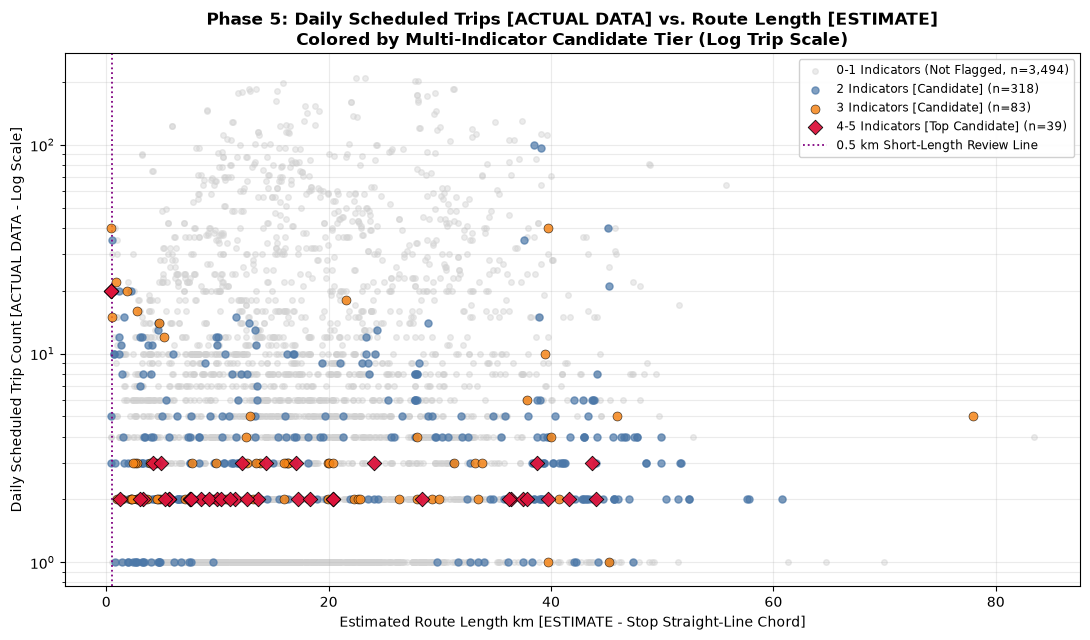

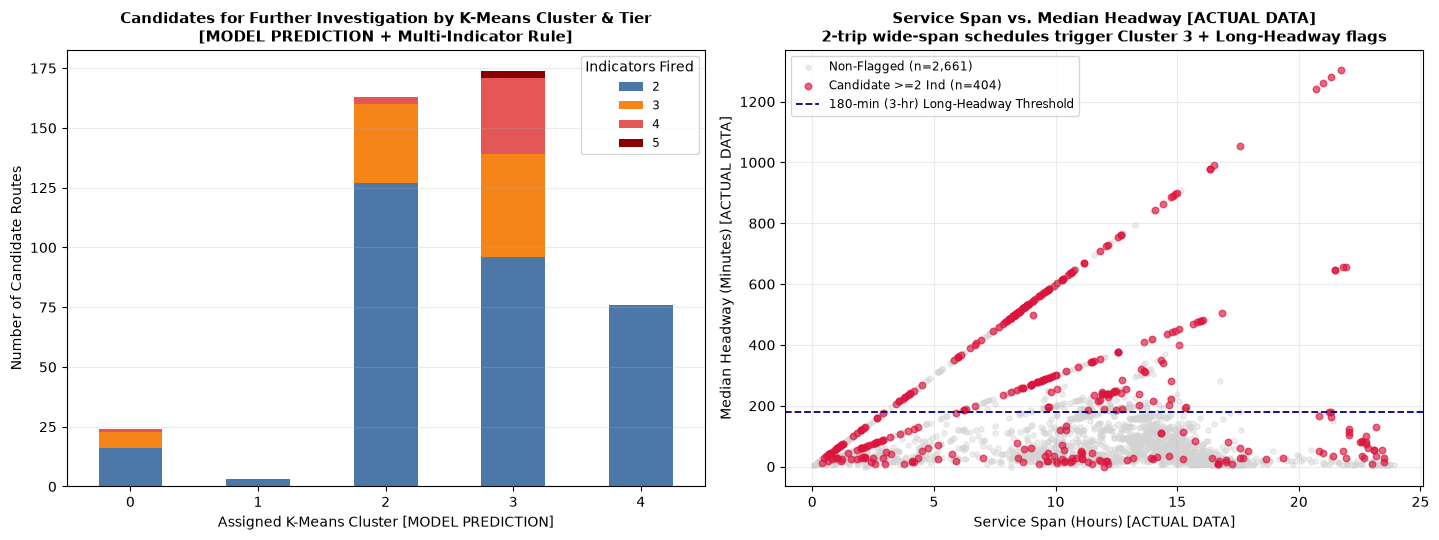

Saved Phase 5 plots to visualizations\inference/


In [19]:
# Plot 1: Trips (ACTUAL) vs Estimated Route Length (ESTIMATE) colored by Indicator Tier
fig, ax = plt.subplots(figsize=(11, 6.5))

non_cand = ev_ranked[ev_ranked["indicator_count"] <= 1]
t2_df = ev_ranked[ev_ranked["indicator_count"] == 2]
t3_df = ev_ranked[ev_ranked["indicator_count"] == 3]
t45_df = ev_ranked[ev_ranked["indicator_count"] >= 4]

ax.scatter(non_cand["route_length_km_ESTIMATE"], non_cand["trip_count"],
           c="lightgray", alpha=0.45, s=16, label=f"0-1 Indicators (Not Flagged, n={len(non_cand):,})", zorder=1)
ax.scatter(t2_df["route_length_km_ESTIMATE"], t2_df["trip_count"],
           c="#4C78A8", alpha=0.70, s=26, label=f"2 Indicators [Candidate] (n={len(t2_df):,})", zorder=2)
ax.scatter(t3_df["route_length_km_ESTIMATE"], t3_df["trip_count"],
           c="#F58518", alpha=0.85, s=42, edgecolors="black", linewidths=0.4, label=f"3 Indicators [Candidate] (n={len(t3_df):,})", zorder=3)
ax.scatter(t45_df["route_length_km_ESTIMATE"], t45_df["trip_count"],
           c="crimson", marker="D", alpha=0.95, s=55, edgecolors="black", linewidths=0.6, label=f"4-5 Indicators [Top Candidate] (n={len(t45_df):,})", zorder=4)

ax.axvline(0.5, color="purple", linestyle=":", linewidth=1.3, label="0.5 km Short-Length Review Line")
ax.set_yscale("log")
ax.set_title("Phase 5: Daily Scheduled Trips [ACTUAL DATA] vs. Route Length [ESTIMATE]\nColored by Multi-Indicator Candidate Tier (Log Trip Scale)", fontsize=12, fontweight="bold")
ax.set_xlabel("Estimated Route Length km [ESTIMATE - Stop Straight-Line Chord]")
ax.set_ylabel("Daily Scheduled Trip Count [ACTUAL DATA - Log Scale]")
ax.legend(loc="upper right", fontsize=8.5, framealpha=0.92)
ax.grid(alpha=0.25, which="both")
plt.tight_layout()
plt.savefig(OUT_VIZ / "phase5_candidates_trips_vs_length.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot 2: Two-panel Candidate Breakdown & Headway vs Span
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

# Left: Stacked bar of candidates by K-Means Cluster & Tier
ct_k = pd.crosstab(candidates_df["kmeans_cluster_MODEL_PREDICTION"], candidates_df["indicator_count"])
ct_k.plot(kind="bar", stacked=True, color=["#4C78A8", "#F58518", "#E45756", "#8B0000"][:ct_k.shape[1]], ax=axes[0])
axes[0].set_title("Candidates for Further Investigation by K-Means Cluster & Tier\n[MODEL PREDICTION + Multi-Indicator Rule]", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Assigned K-Means Cluster [MODEL PREDICTION]")
axes[0].set_ylabel("Number of Candidate Routes")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Indicators Fired", fontsize=8.5)
axes[0].grid(axis="y", alpha=0.25)

# Right: Service Span vs Median Headway (routes with computable headway)
hw_ev = ev_ranked[ev_ranked["median_headway_min"].notna()]
hw_nc = hw_ev[hw_ev["indicator_count"] <= 1]
hw_c = hw_ev[hw_ev["indicator_count"] >= 2]
axes[1].scatter(hw_nc["service_span_hours"], hw_nc["median_headway_min"], c="lightgray", alpha=0.40, s=14, label=f"Non-Flagged (n={len(hw_nc):,})")
axes[1].scatter(hw_c["service_span_hours"], hw_c["median_headway_min"], c="crimson", alpha=0.65, s=22, label=f"Candidate >=2 Ind (n={len(hw_c):,})")
axes[1].axhline(180, color="navy", linestyle="--", linewidth=1.3, label="180-min (3-hr) Long-Headway Threshold")
axes[1].set_title("Service Span vs. Median Headway [ACTUAL DATA]\n2-trip wide-span schedules trigger Cluster 3 + Long-Headway flags", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Service Span (Hours) [ACTUAL DATA]")
axes[1].set_ylabel("Median Headway (Minutes) [ACTUAL DATA]")
axes[1].legend(loc="upper left", fontsize=8.5)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(OUT_VIZ / "phase5_candidates_breakdown_and_headway.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved Phase 5 plots to {OUT_VIZ}/")


### What the Data Supports vs. What Is Missing (Crucial Scope Boundary)

1. **What Scheduled GTFS + Multi-Indicator Evidence Supports:**
   - Identifies routes whose **published timetable structure** stands out cleanly from dense cross-city norms across multiple independent signals (e.g., 2-trip corridors stretched over 13–17 hours with `490–980 min` headways that K-Means assigns to Cluster 3; ultra-short `0.40 km` `CT` shuttles; high-deviation nocturnal schedules).
   - Flags multi-indicator **candidates for further investigation** that warrant targeted verification against agency master logs and planner priorities.

2. **What Cannot Be Claimed (Missing Data Required Before Operational Decisions):**
   - **Passenger Ridership & Boarding/Alighting Counts:** A 2-trip corridor with a 12-hour gap (`570P`) might serve exact shift-change demand at an industrial estate or IT park—or it could reflect a partial GTFS export. We **cannot** claim it is underutilised or overcrowded.
   - **Vehicle Seating Capacity & Fleet Assignment:** `trip_count` does not record whether a route uses a minibus, standard diesel bus, or AC articulated coach, nor whether vehicles deadhead or interline onto another `route_short_name`.
   - **Operating Context, Financial Subsidies & Legal Mandates:** Essential rural/hospital/night owl lines are intentionally cross-subsidized even at sparse scheduled frequency.
   - **Road Geometry (`shapes.txt` missing):** Route lengths are straight-line `ESTIMATE` values; short `0.40 km` routes (`54 CT1`, `578 CT`) must be checked on actual stop coordinates before drawing conclusions.

---
**Phase 5 Complete — Awaiting user confirmation before proceeding to Phase 6 (Safe Optimization Simulation).**


---
# Phase 6: Data-Supported Optimization Candidates (Merge, Split, Frequency Review)

**Goal:** Screen Chennai's `3,934` active scheduled routes for structural **merge**, **split**, and **frequency review** candidates *strictly where published GTFS evidence supports further investigation*—and explicitly flag optimization categories that are **not supported by available data**.

### Key Safeguards & Provenance Discipline
- **No Shapes Available:** Chennai lacks `shapes.txt`, so physical street-path overlap cannot be measured; merge analysis evaluates **stop-set overlap (`Jaccard`)** and **ordered stop-sequence contiguity** (`stop_times.txt`) only.
- **Supply Only:** Frequency comparisons contrast Chennai timetables against size-matched training peers (`MODEL PREDICTION` cluster + length/stop band). Because ridership, capacity, travel time, and O–D transfers are missing, every row carries `status = "candidate for investigation"`, explicit `data_limitations`, and zero claims of inefficiency.


---
## Phase 6.A: Route Overlap & Merge Candidate Screening

### Stated Multi-Condition Thresholds
1. **Route Size Floor:** Both routes serve $\ge 10$ distinct stops (excludes trivial short shuttles).
2. **High Stop Overlap:** $\text{Jaccard} \ge 0.90$ and smaller-route coverage $\ge 0.90$, computed via an inverted `stop_id -> route_id` index.
3. **Distinct Line Numbers:** `route_short_name_1 != route_short_name_2` (avoids pairing outbound vs. inbound directions of the same line).
4. **Same Service Pattern (`MODEL PREDICTION`):** Identical K-Means cluster ($K_1 = K_2$).
5. **Temporal Compatibility:** Compatible operating days (both serve Mon–Sat/Sun) AND $\ge 50\%$ overlapping daily service-hour windows.
6. **Sensible Corridor Length:** Both routes $\le 35.0\text{ km}$ (`ESTIMATE`), keeping any consolidated corridor within urban metro range.
7. **Forward Contiguous Connectivity & Shared Terminal:** At least $80\%$ of the smaller route's stops (and $\ge 8$ stops) appear in identical forward order along `stop_sequence`, with a shared origin or destination terminus (distinguishing same-direction corridor variants from opposite-direction loops).


In [20]:
from collections import defaultdict

# Load core Chennai tables needed for stop connectivity and sequences
ch_trips = pd.read_csv(NEW_CITY_DIR / "trips.txt", dtype=str)
ch_st = pd.read_csv(NEW_CITY_DIR / "stop_times.txt", dtype={"trip_id": str, "stop_id": str})
ch_stops = pd.read_csv(NEW_CITY_DIR / "stops.txt", dtype=str)

ch_trips["route_id"] = "chennai_" + ch_trips["route_id"]
ch_trips["trip_id"] = "chennai_" + ch_trips["trip_id"]
ch_st["trip_id"] = "chennai_" + ch_st["trip_id"]
ch_st["stop_id"] = "chennai_" + ch_st["stop_id"]
ch_stops["stop_id"] = "chennai_" + ch_stops["stop_id"]
stop_name_map = ch_stops.set_index("stop_id")["stop_name"].to_dict()

# Load combined evidence + operating_days from Phase 5/2
ev_all = pd.read_csv(OUT_INFERENCE / "new_city_all_routes_evidence.csv", dtype={"route_id": str, "route_short_name": str, "route_long_name": str})
lkp_days = pd.read_csv(OUT_INFERENCE / "new_city_route_lookup.csv", dtype={"route_id": str, "operating_days": str})
raw_p = pd.read_csv(OUT_INFERENCE / "new_city_route_features.csv", dtype={"route_id": str})
ev_all = ev_all.merge(lkp_days[["route_id", "operating_days"]], on="route_id", how="left")
ev_all = ev_all.merge(raw_p[["route_id", "trips_morning", "trips_afternoon", "trips_evening", "trips_night"]], on="route_id", how="left")
ev_idx = ev_all.set_index("route_id")

# 1. Build stop -> routes inverted index and representative ordered stop sequences
st_merged = ch_st[["trip_id", "stop_id", "stop_sequence"]].merge(ch_trips[["trip_id", "route_id"]], on="trip_id", how="inner")
st_merged["stop_sequence"] = pd.to_numeric(st_merged["stop_sequence"], errors="coerce")

route_stop_sets = st_merged.groupby("route_id")["stop_id"].apply(set).to_dict()
stop_to_routes = defaultdict(set)
for rid, sset in route_stop_sets.items():
    for sid in sset:
        stop_to_routes[sid].add(rid)
stop_connectivity = {sid: len(rset) for sid, rset in stop_to_routes.items()}

# Representative trip per route (most stops) ordered by stop_sequence
trip_len_counts = st_merged.groupby(["route_id", "trip_id"]).size().reset_index(name="n_stops")
rep_trips_df = trip_len_counts.sort_values(["route_id", "n_stops"], ascending=[True, False]).drop_duplicates("route_id")
rep_st_df = st_merged.merge(rep_trips_df[["trip_id"]], on="trip_id", how="inner").sort_values(["route_id", "stop_sequence"])
route_stop_seq = rep_st_df.groupby("route_id")["stop_id"].apply(list).to_dict()

def max_contiguous_forward(seq1, seq2):
    """Longest contiguous forward matching subsequence along stop_sequence."""
    pos2 = defaultdict(list)
    for j, stop in enumerate(seq2):
        pos2[stop].append(j)
    best, dp = 0, {}
    for stop in seq1:
        ndp = {}
        for j in pos2.get(stop, []):
            ndp[j] = dp.get(j - 1, 0) + 1
            if ndp[j] > best:
                best = ndp[j]
        dp = ndp
    return best

# 2. Efficient pairwise stop-overlap count over routes with >= 10 stops
pair_shared = defaultdict(int)
for sid, rset in stop_to_routes.items():
    rlist = sorted(r for r in rset if len(route_stop_sets[r]) >= 10)
    for i in range(len(rlist)):
        ri = rlist[i]
        for j in range(i + 1, len(rlist)):
            pair_shared[(ri, rlist[j])] += 1

all_high_overlap = []
merge_candidates = []

JACCARD_TH = 0.90
MAX_CORRIDOR_KM = 35.0
MIN_CONTIG_SHARE = 0.80

for (r1, r2), shared in pair_shared.items():
    s1, s2 = len(route_stop_sets[r1]), len(route_stop_sets[r2])
    jacc = shared / (s1 + s2 - shared)
    cov = shared / min(s1, s2)
    if jacc < 0.70:
        continue

    row1, row2 = ev_idx.loc[r1], ev_idx.loc[r2]
    same_sn = str(row1["route_short_name"]) == str(row2["route_short_name"])
    same_cluster = int(row1["kmeans_cluster_MODEL_PREDICTION"]) == int(row2["kmeans_cluster_MODEL_PREDICTION"])

    days1 = set(str(row1["operating_days"]).split(","))
    days2 = set(str(row2["operating_days"]).split(","))
    days_compat = len(days1 & days2) >= 5

    f1, l1 = float(row1["first_departure_hour"]), float(row1["last_departure_hour"])
    f2, l2 = float(row2["first_departure_hour"]), float(row2["last_departure_hour"])
    ov_hrs = max(0.0, min(l1, l2) - max(f1, f2))
    min_span = max(min(l1 - f1, l2 - f2), 1.0)
    time_compat = (ov_hrs / min_span) >= 0.50

    len1, len2 = float(row1["route_length_km_ESTIMATE"]), float(row2["route_length_km_ESTIMATE"])
    len_ok = max(len1, len2) <= MAX_CORRIDOR_KM

    seq1, seq2 = route_stop_seq[r1], route_stop_seq[r2]
    contig = max_contiguous_forward(seq1, seq2)
    contig_share = contig / min(len(seq1), len(seq2))
    same_term = (seq1[0] == seq2[0]) or (seq1[-1] == seq2[-1])

    all_high_overlap.append({
        "jaccard": jacc,
        "contig_share": contig_share,
        "is_merge_cand": False,
    })

    if (jacc >= JACCARD_TH and cov >= 0.90 and (not same_sn) and same_cluster
            and days_compat and time_compat and len_ok
            and contig >= 8 and contig_share >= MIN_CONTIG_SHARE and same_term):
        all_high_overlap[-1]["is_merge_cand"] = True
        merge_candidates.append({
            "route_id_1": r1,
            "route_id_2": r2,
            "short_name_1": row1["route_short_name"],
            "short_name_2": row2["route_short_name"],
            "long_name_1": row1["route_long_name"],
            "long_name_2": row2["route_long_name"],
            "kmeans_cluster_PRED": int(row1["kmeans_cluster_MODEL_PREDICTION"]),
            "stops_1": s1,
            "stops_2": s2,
            "shared_stops": shared,
            "contig_fwd_stops": contig,
            "same_terminal": same_term,
            "jaccard_similarity": round(jacc, 4),
            "cov_smaller": round(cov, 4),
            "len_km_1_ESTIMATE": round(len1, 2),
            "len_km_2_ESTIMATE": round(len2, 2),
            "trips_1_ACTUAL": int(row1["trip_count"]),
            "trips_2_ACTUAL": int(row2["trip_count"]),
            "headway_1_ACTUAL": row1["median_headway_min"],
            "headway_2_ACTUAL": row2["median_headway_min"],
        })

overlap_plot_df = pd.DataFrame(all_high_overlap)
merge_df = pd.DataFrame(merge_candidates).sort_values(
    by=["jaccard_similarity", "shared_stops", "trips_1_ACTUAL"],
    ascending=[False, False, False],
).reset_index(drop=True)

merge_df.to_csv(OUT_INFERENCE / "merge_candidates_detail.csv", index=False)

print("Note: shapes.txt is ABSENT in Chennai -> NO physical path geometry similarity claimed (stop-order only).")
print(f"Total route pairs (>=10 stops) with Jaccard >= 0.70 : {len(overlap_plot_df):,}")
print(f"Strict Merge Review Candidates passing ALL 7 rules  : {len(merge_df):,}")
print("\nTop 10 Merge Candidates (Different Line Numbers, Jaccard >= 0.90, Contiguous Same-Direction Corridor):")
print(merge_df.head(10)[[
    "route_id_1", "route_id_2", "short_name_1", "short_name_2", "kmeans_cluster_PRED",
    "shared_stops", "contig_fwd_stops", "jaccard_similarity", "len_km_1_ESTIMATE", "trips_1_ACTUAL", "trips_2_ACTUAL"
]].to_string(index=False))


Note: shapes.txt is ABSENT in Chennai -> NO physical path geometry similarity claimed (stop-order only).
Total route pairs (>=10 stops) with Jaccard >= 0.70 : 3,175
Strict Merge Review Candidates passing ALL 7 rules  : 169

Top 10 Merge Candidates (Different Line Numbers, Jaccard >= 0.90, Contiguous Same-Direction Corridor):
   route_id_1    route_id_2 short_name_1 short_name_2  kmeans_cluster_PRED  shared_stops  contig_fwd_stops  jaccard_similarity  len_km_1_ESTIMATE  trips_1_ACTUAL  trips_2_ACTUAL
chennai_21067 chennai_21357      159  R3       159 R5                    4            55                55                 1.0              29.07              27               7
chennai_19462 chennai_19463           2B          C33                    4            51                51                 1.0              23.84              39              16
chennai_17652 chennai_19462          C64           2B                    4            51                51                 1.0             

---
## Phase 6.B: Long-Route Split Candidate Screening

### Criteria & Connectivity Hub Check
- **Length & Granularity Threshold:** `route_length_km` (`ESTIMATE`) above the **Training 95th Percentile (`46.87 km`)** AND **`stop_count >= 45`** (`ACTUAL DATA`).
- **Hub Connectivity Check:** Scan interior stops ($20\%$ to $80\%$ along the trip's `stop_sequence`) using `stop_connectivity` (`count of distinct active Chennai routes serving that stop`). Require an interior interchange hub served by **$\ge 100$ active routes** so a potential split naturally connects riders to dense trunk transfers.
- **Explicit Limitation:** GTFS contains **zero through-passenger O–D counts, transfer penalty costs, fare-reboarding rules, or actual travel times**—all must be evaluated before any route split decision.


In [21]:
# Training P95 route length threshold
tr_feat_ref = pd.read_csv("processed/route_features.csv")
TRAIN_LEN_P95 = float(tr_feat_ref[tr_feat_ref["trip_count"].notna()]["route_length_km"].quantile(0.95))
MIN_SPLIT_STOPS = 45
MIN_HUB_ROUTES = 100

long_routes_all = ev_all[
    (ev_all["route_length_km_ESTIMATE"] > TRAIN_LEN_P95) &
    (ev_all["stop_count"] >= MIN_SPLIT_STOPS)
].sort_values("route_length_km_ESTIMATE", ascending=False).copy()

split_candidates = []
split_plot_rows = []

for _, r in long_routes_all.iterrows():
    rid = r["route_id"]
    seq = route_stop_seq.get(rid, [])
    if len(seq) < 10:
        continue
    lo, hi = int(len(seq) * 0.20), int(len(seq) * 0.80)
    interior = seq[lo:hi]
    best_hub = max(interior, key=lambda sid: stop_connectivity.get(sid, 0)) if interior else seq[len(seq) // 2]
    hub_deg = int(stop_connectivity.get(best_hub, 0))
    hub_pos = seq.index(best_hub) + 1
    hub_nm = stop_name_map.get(best_hub, "Unknown Stop")

    qualifies = hub_deg >= MIN_HUB_ROUTES
    split_plot_rows.append({
        "route_id": rid,
        "len_km": float(r["route_length_km_ESTIMATE"]),
        "stop_count": int(r["stop_count"]),
        "hub_deg": hub_deg,
        "qualifies": qualifies,
    })

    if qualifies:
        split_candidates.append({
            "route_id": rid,
            "short_name": r["route_short_name"],
            "long_name": r["route_long_name"],
            "kmeans_cluster_PRED": int(r["kmeans_cluster_MODEL_PREDICTION"]),
            "route_length_km_ESTIMATE": round(float(r["route_length_km_ESTIMATE"]), 2),
            "stop_count_ACTUAL": int(r["stop_count"]),
            "trip_count_ACTUAL": int(r["trip_count"]),
            "service_span_hours_ACTUAL": round(float(r["service_span_hours"]), 2),
            "split_hub_stop_id": best_hub,
            "split_hub_stop_name": hub_nm,
            "split_hub_seq_pos": f"{hub_pos}/{len(seq)}",
            "split_hub_intersecting_routes": hub_deg,
        })

split_plot_df = pd.DataFrame(split_plot_rows)
split_df = pd.DataFrame(split_candidates).sort_values(
    ["split_hub_intersecting_routes", "route_length_km_ESTIMATE"], ascending=[False, False]
).reset_index(drop=True)

split_df.to_csv(OUT_INFERENCE / "split_candidates_detail.csv", index=False)

print(f"Training P95 Length Threshold: {TRAIN_LEN_P95:.2f} km")
print(f"Long + Multi-Stop Routes (> {TRAIN_LEN_P95:.2f} km & >= {MIN_SPLIT_STOPS} stops): {len(long_routes_all)}")
print(f"Split Review Candidates with Major Interior Interchange Hub (>= {MIN_HUB_ROUTES} routes): {len(split_df)}")
print("\nTop 10 Split Review Candidates:")
print(split_df.head(10)[[
    "route_id", "short_name", "route_length_km_ESTIMATE", "stop_count_ACTUAL",
    "trip_count_ACTUAL", "split_hub_stop_name", "split_hub_seq_pos", "split_hub_intersecting_routes"
]].to_string(index=False))


Training P95 Length Threshold: 46.87 km
Long + Multi-Stop Routes (> 46.87 km & >= 45 stops): 30
Split Review Candidates with Major Interior Interchange Hub (>= 100 routes): 25

Top 10 Split Review Candidates:
     route_id short_name  route_length_km_ESTIMATE  stop_count_ACTUAL  trip_count_ACTUAL           split_hub_stop_name split_hub_seq_pos  split_hub_intersecting_routes
chennai_11530       500W                     51.59                 59                  3       Tambaram West Bus Stand             33/59                            367
chennai_20473       500W                     51.72                 63                  3 Chinnamalai Or Saidapet Court             14/63                            246
chennai_16406      578PC                     48.57                 65                  3 Chinnamalai Or Saidapet Court             43/65                            246
chennai_16423      578PC                     48.57                 65                  3 Chinnamalai Or Saidapet Court 

---
## Phase 6.C: Schedule Frequency Review Candidates (Matched Cluster Peers)

### Peer-Comparison Logic (Supply Only)
For each active Chennai route, we locate **training peers from the same K-Means cluster** having **similar physical scale** ($\pm 30\%$ `route_length_km` and $\pm 30\%$ `stop_count`, requiring $\ge 20$ training peers).  
A route is flagged as a **schedule frequency review candidate** if:
1. **`median_headway_min` (`ACTUAL DATA`)** exceeds **both** the matched peers' 90th percentile ($P_{90}^{\text{peers}}$) **and** `240 minutes` ($4+$ hours between consecutive departures), **AND**
2. **At least 2 daytime/evening periods** (Morning, Afternoon, Evening) schedule $\le 1$ trip where matched peers average $\ge 5$ trips.

> **Critical Constraint:** This compares **scheduled timetable supply** against similar-scale corridors only. Any decision to add or reduce buses **requires actual ridership/boarding data and vehicle capacity constraints**.


In [22]:
tr_kca_ref = pd.read_csv("results/kmeans_cluster_assignments.csv", dtype={"route_id": str, "city": str})
tr_peers_full = tr_kca_ref.merge(tr_feat_ref, on=["route_id", "city"], how="left")

freq_candidates = []
for _, r in ev_all.iterrows():
    k = int(r["kmeans_cluster_MODEL_PREDICTION"])
    L = float(r["route_length_km_ESTIMATE"])
    S = float(r["stop_count"])

    peers = tr_peers_full[
        (tr_peers_full["cluster"] == k) &
        (tr_peers_full["route_length_km"].between(0.70 * L, 1.30 * L)) &
        (tr_peers_full["stop_count"].between(0.70 * S, 1.30 * S))
    ]
    if len(peers) < 20:
        continue

    hw_valid_peers = peers["median_headway_min"].dropna()
    if len(hw_valid_peers) < 10:
        continue

    p_hw_med = float(hw_valid_peers.median())
    p_hw_p90 = float(hw_valid_peers.quantile(0.90))
    p_trips_med = float(peers["trip_count"].median())
    p_am = float(peers["trips_morning"].median())
    p_pm = float(peers["trips_afternoon"].median())
    p_ev = float(peers["trips_evening"].median())

    hw_val = r["median_headway_min"]
    is_extreme_hw = pd.notna(hw_val) and (hw_val > max(p_hw_p90, 240.0))

    low_periods_list = []
    if p_am >= 5 and r["trips_morning"] <= 1:
        low_periods_list.append(f"AM:{int(r['trips_morning'])} vs peer~{p_am:.0f}")
    if p_pm >= 5 and r["trips_afternoon"] <= 1:
        low_periods_list.append(f"PM:{int(r['trips_afternoon'])} vs peer~{p_pm:.0f}")
    if p_ev >= 5 and r["trips_evening"] <= 1:
        low_periods_list.append(f"EVE:{int(r['trips_evening'])} vs peer~{p_ev:.0f}")

    if is_extreme_hw and len(low_periods_list) >= 2:
        freq_candidates.append({
            "route_id": r["route_id"],
            "short_name": r["route_short_name"],
            "long_name": r["route_long_name"],
            "kmeans_cluster_PRED": k,
            "matched_train_peers_n": len(peers),
            "trip_count_ACTUAL": int(r["trip_count"]),
            "peer_trips_median": round(p_trips_med, 1),
            "median_headway_min_ACTUAL": float(hw_val),
            "peer_headway_median": round(p_hw_med, 1),
            "peer_headway_p90": round(p_hw_p90, 1),
            "route_length_km_ESTIMATE": round(L, 2),
            "stop_count_ACTUAL": int(S),
            "period_gaps": "; ".join(low_periods_list),
            "hw_ratio_to_peer_med": round(float(hw_val) / max(p_hw_med, 1.0), 2),
        })

freq_df = pd.DataFrame(freq_candidates).sort_values(
    ["hw_ratio_to_peer_med", "median_headway_min_ACTUAL"], ascending=[False, False]
).reset_index(drop=True)

freq_df.to_csv(OUT_INFERENCE / "frequency_candidates_detail.csv", index=False)

print(f"Frequency Schedule Review Candidates (>= 20 matched peers, HW > max(P90, 240m), >=2 low periods): {len(freq_df):,}")
print("\nTop 10 Frequency Review Candidates:")
print(freq_df.head(10)[[
    "route_id", "short_name", "kmeans_cluster_PRED", "matched_train_peers_n",
    "trip_count_ACTUAL", "peer_trips_median", "median_headway_min_ACTUAL", "peer_headway_p90", "period_gaps"
]].to_string(index=False))


Frequency Schedule Review Candidates (>= 20 matched peers, HW > max(P90, 240m), >=2 low periods): 287

Top 10 Frequency Review Candidates:
     route_id short_name  kmeans_cluster_PRED  matched_train_peers_n  trip_count_ACTUAL  peer_trips_median  median_headway_min_ACTUAL  peer_headway_p90                                        period_gaps
chennai_13180        M27                    3                     23                  2               68.0                      865.0             119.9 AM:1 vs peer~24; PM:0 vs peer~15; EVE:0 vs peer~12
chennai_20841     M1 CT3                    3                     43                  2               54.0                      762.0              92.5 AM:1 vs peer~20; PM:0 vs peer~12; EVE:0 vs peer~12
chennai_11030       114S                    4                    293                  2               35.0                      840.0             146.5  AM:1 vs peer~15; PM:0 vs peer~10; EVE:1 vs peer~7
chennai_15866      47DCt                    3    

---
## Phase 6.D: Unified Suggestions Table, Unsupported Analyses & Visualizations

We consolidate all data-supported candidates (`merge`, `split`, `frequency`) into `inference/optimization_suggestions.csv` with the exact required schema (`suggestion_id`, `type`, `routes_involved`, `evidence_summary`, `supporting_metrics`, `data_limitations`, `status = "candidate for investigation"`), document optimization types **`"not supported by available data"`**, and render summary visualizations in `visualizations/inference/`.


Saved unified suggestions table -> inference\optimization_suggestions.csv (481, 7)

Suggestion Counts by Type (status = 'candidate for investigation'):
type
frequency    287
merge        169
split         25

=== OPTIMIZATION CATEGORIES EXPLICITLY REFUSED ===
                                           optimization_category                  support_status                                                                            missing_required_data
     Peak-Hour Overcrowding Relief / Fleet Capacity Reallocation not supported by available data            Passenger boarding/alighting counts (APC/AFC), load factors, vehicle seating capacity
      Turning-Movement & Street-Geometry Road Path Consolidation not supported by available data  shapes.txt polylines & shape_id links (absent in Chennai GTFS); road lane/intersection geometry
Timed-Transfer Synchronization & Layover / Deadhead Optimization not supported by available data           GTFS block_id, depot pull-out/pull-in schedules, re

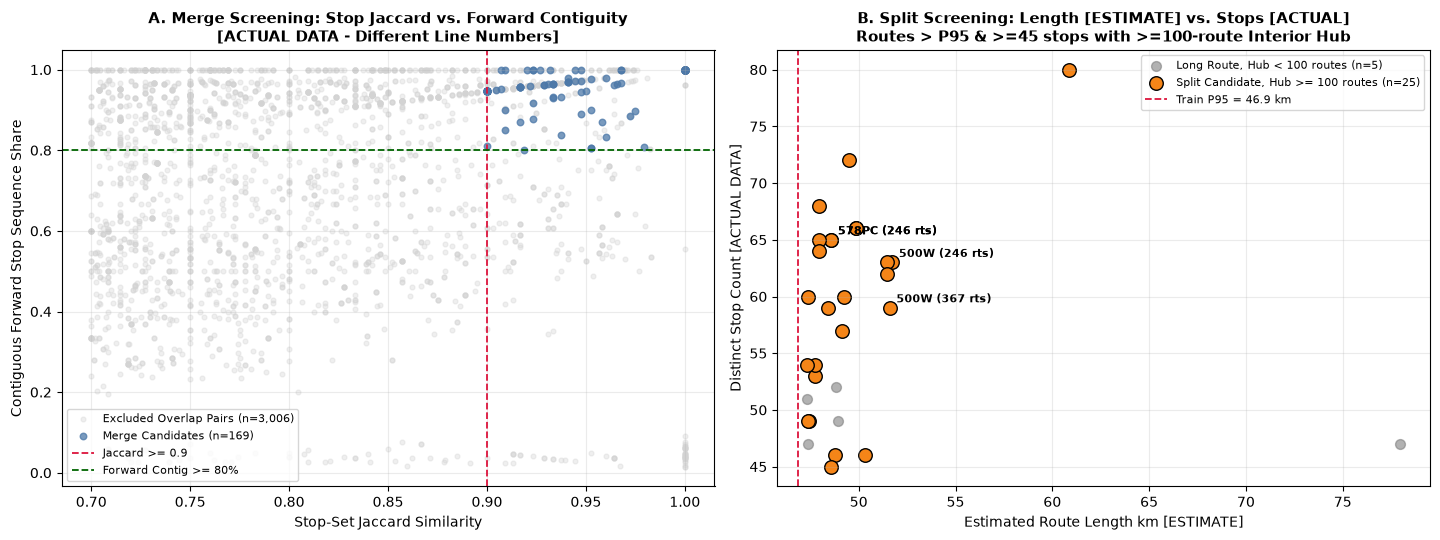

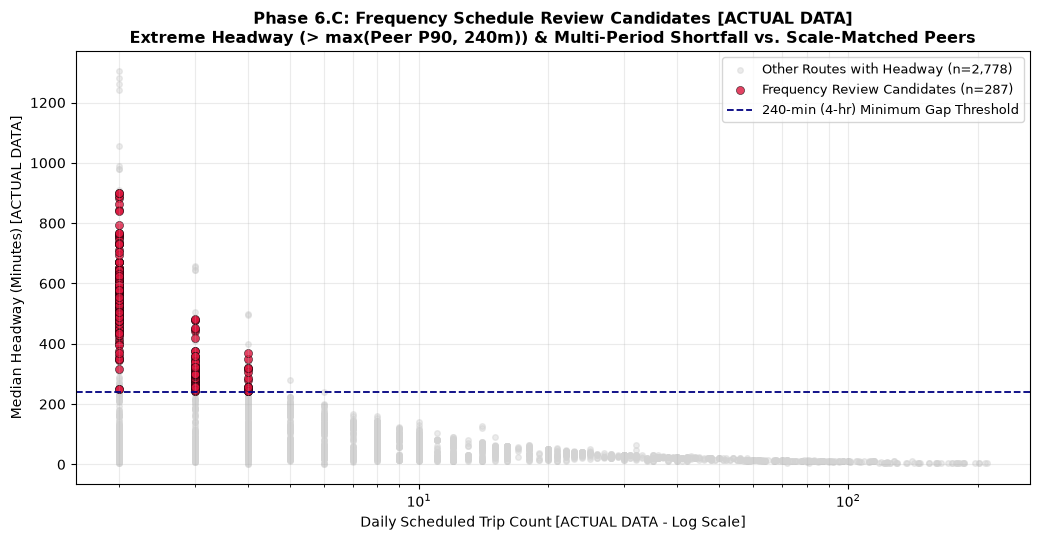

Saved 2 Phase 6 plots to visualizations\inference/


In [23]:
suggestion_rows = []

# 1. Add Merge candidates (top ranked corridor duplicates/overlaps)
for idx, r in merge_df.iterrows():
    suggestion_rows.append({
        "suggestion_id": f"OPT_M_{idx+1:03d}",
        "type": "merge",
        "routes_involved": f"{r['route_id_1']} ({r['short_name_1']}) + {r['route_id_2']} ({r['short_name_2']})",
        "evidence_summary": (
            f"[ACTUAL DATA] Share {r['shared_stops']}/{min(r['stops_1'], r['stops_2'])} stops "
            f"(Jaccard={r['jaccard_similarity']:.2f}), {r['contig_fwd_stops']} consecutive forward stops, "
            f"shared terminus; [MODEL PREDICTION] both K-Means Cluster {r['kmeans_cluster_PRED']}."
        ),
        "supporting_metrics": (
            f"jaccard={r['jaccard_similarity']}; contig_fwd={r['contig_fwd_stops']}; "
            f"len1_EST={r['len_km_1_ESTIMATE']}km; len2_EST={r['len_km_2_ESTIMATE']}km; "
            f"trips={r['trips_1_ACTUAL']}+{r['trips_2_ACTUAL']}"
        ),
        "data_limitations": (
            "shapes.txt absent (no road-path geometry check); missing passenger demand, boarding load, "
            "vehicle capacity, actual running times, and distinct branch/express tariff rules."
        ),
        "status": "candidate for investigation",
    })

# 2. Add Split candidates (small list of longest hub-connected corridors)
for idx, r in split_df.iterrows():
    suggestion_rows.append({
        "suggestion_id": f"OPT_S_{idx+1:03d}",
        "type": "split",
        "routes_involved": f"{r['route_id']} ({r['short_name']}: {r['long_name']})",
        "evidence_summary": (
            f"[ESTIMATE] Length {r['route_length_km_ESTIMATE']:.1f} km (> training P95 {TRAIN_LEN_P95:.1f} km) "
            f"across [ACTUAL DATA] {r['stop_count_ACTUAL']} stops; interior stop '{r['split_hub_stop_name']}' "
            f"({r['split_hub_seq_pos']}) connects {r['split_hub_intersecting_routes']} active routes."
        ),
        "supporting_metrics": (
            f"len_EST={r['route_length_km_ESTIMATE']}km; stops={r['stop_count_ACTUAL']}; "
            f"trips={r['trip_count_ACTUAL']}; hub={r['split_hub_stop_id']} ({r['split_hub_intersecting_routes']} routes)"
        ),
        "data_limitations": (
            "shapes.txt absent; cannot measure through-passenger O-D trips, transfer penalties, "
            "fare-reboarding impacts, or actual end-to-end travel-time reliability from GTFS."
        ),
        "status": "candidate for investigation",
    })

# 3. Add Frequency schedule review candidates
for idx, r in freq_df.iterrows():
    suggestion_rows.append({
        "suggestion_id": f"OPT_F_{idx+1:03d}",
        "type": "frequency",
        "routes_involved": f"{r['route_id']} ({r['short_name']}: {r['long_name']})",
        "evidence_summary": (
            f"[ACTUAL DATA] Median headway {r['median_headway_min_ACTUAL']:.0f} min with {r['trip_count_ACTUAL']} daily trips "
            f"vs [MODEL PREDICTION] Cluster {r['kmeans_cluster_PRED']} size-matched training peers (n={r['matched_train_peers_n']}, "
            f"peer med trips={r['peer_trips_median']:.1f}, peer P90 HW={r['peer_headway_p90']:.0f} min); gaps: {r['period_gaps']}."
        ),
        "supporting_metrics": (
            f"hw_ACTUAL={r['median_headway_min_ACTUAL']}m; peer_hw_P90={r['peer_headway_p90']}m; "
            f"trips={r['trip_count_ACTUAL']} vs peer_med={r['peer_trips_median']}; len_EST={r['route_length_km_ESTIMATE']}km"
        ),
        "data_limitations": (
            "Scheduled supply comparison only — zero passenger demand/ridership, vehicle capacity, "
            "peak crowding, shift/industrial service contracts, or revenue data available."
        ),
        "status": "candidate for investigation",
    })

opt_suggestions_df = pd.DataFrame(suggestion_rows)
opt_out_path = OUT_INFERENCE / "optimization_suggestions.csv"
opt_suggestions_df.to_csv(opt_out_path, index=False)

print(f"Saved unified suggestions table -> {opt_out_path} {opt_suggestions_df.shape}")
print("\nSuggestion Counts by Type (status = 'candidate for investigation'):")
print(opt_suggestions_df["type"].value_counts().to_string())

# Explicit Unsupported Categories Table
unsupported_df = pd.DataFrame([
    {
        "optimization_category": "Peak-Hour Overcrowding Relief / Fleet Capacity Reallocation",
        "support_status": "not supported by available data",
        "missing_required_data": "Passenger boarding/alighting counts (APC/AFC), load factors, vehicle seating capacity",
    },
    {
        "optimization_category": "Turning-Movement & Street-Geometry Road Path Consolidation",
        "support_status": "not supported by available data",
        "missing_required_data": "shapes.txt polylines & shape_id links (absent in Chennai GTFS); road lane/intersection geometry",
    },
    {
        "optimization_category": "Timed-Transfer Synchronization & Layover / Deadhead Optimization",
        "support_status": "not supported by available data",
        "missing_required_data": "GTFS block_id, depot pull-out/pull-in schedules, real-time AVL travel-time variability",
    },
    {
        "optimization_category": "Service Elimination or Cost/Revenue Optimization",
        "support_status": "not supported by available data",
        "missing_required_data": "O-D demand surveys, farebox revenue, operating cost/km, social-equity/essential service mandates",
    },
])
unsupported_df.to_csv(OUT_INFERENCE / "unsupported_optimization_categories.csv", index=False)
print("\n=== OPTIMIZATION CATEGORIES EXPLICITLY REFUSED ===")
print(unsupported_df.to_string(index=False))

# --- Visualizations (saved to visualizations/inference/) ---
# Chart 1: Merge Stop Overlap + Split Long Route Hub Topology
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

non_m = overlap_plot_df[~overlap_plot_df["is_merge_cand"]]
yes_m = overlap_plot_df[overlap_plot_df["is_merge_cand"]]
axes[0].scatter(non_m["jaccard"], non_m["contig_share"], c="lightgray", alpha=0.35, s=12, label=f"Excluded Overlap Pairs (n={len(non_m):,})")
axes[0].scatter(yes_m["jaccard"], yes_m["contig_share"], c="#4C78A8", alpha=0.75, s=22, label=f"Merge Candidates (n={len(yes_m):,})")
axes[0].axvline(JACCARD_TH, color="crimson", linestyle="--", linewidth=1.3, label=f"Jaccard >= {JACCARD_TH}")
axes[0].axhline(MIN_CONTIG_SHARE, color="darkgreen", linestyle="--", linewidth=1.3, label=f"Forward Contig >= {MIN_CONTIG_SHARE:.0%}")
axes[0].set_title("A. Merge Screening: Stop Jaccard vs. Forward Contiguity\n[ACTUAL DATA - Different Line Numbers]", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Stop-Set Jaccard Similarity")
axes[0].set_ylabel("Contiguous Forward Stop Sequence Share")
axes[0].legend(loc="lower left", fontsize=8)
axes[0].grid(alpha=0.25)

if not split_plot_df.empty:
    sp_no = split_plot_df[~split_plot_df["qualifies"]]
    sp_yes = split_plot_df[split_plot_df["qualifies"]]
    axes[1].scatter(sp_no["len_km"], sp_no["stop_count"], c="gray", alpha=0.6, s=50, label=f"Long Route, Hub < 100 routes (n={len(sp_no)})")
    axes[1].scatter(sp_yes["len_km"], sp_yes["stop_count"], c="#F58518", edgecolors="black", s=95, label=f"Split Candidate, Hub >= 100 routes (n={len(sp_yes)})")
    for _, sr in split_df.head(4).iterrows():
        axes[1].annotate(f"{sr['short_name']} ({sr['split_hub_intersecting_routes']} rts)",
                         (sr["route_length_km_ESTIMATE"], sr["stop_count_ACTUAL"]),
                         textcoords="offset points", xytext=(5, 4), fontsize=8, fontweight="bold")
axes[1].axvline(TRAIN_LEN_P95, color="crimson", linestyle="--", linewidth=1.3, label=f"Train P95 = {TRAIN_LEN_P95:.1f} km")
axes[1].set_title("B. Split Screening: Length [ESTIMATE] vs. Stops [ACTUAL]\nRoutes > P95 & >=45 stops with >=100-route Interior Hub", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Estimated Route Length km [ESTIMATE]")
axes[1].set_ylabel("Distinct Stop Count [ACTUAL DATA]")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(OUT_VIZ / "phase6_merge_and_split_topology.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 2: Frequency Review Candidates vs Matched Network
fig, ax = plt.subplots(figsize=(10.5, 5.5))
valid_hw_ev = ev_all[ev_all["median_headway_min"].notna()]
non_freq = valid_hw_ev[~valid_hw_ev["route_id"].isin(set(freq_df["route_id"]))]
yes_freq = valid_hw_ev[valid_hw_ev["route_id"].isin(set(freq_df["route_id"]))]

ax.scatter(non_freq["trip_count"], non_freq["median_headway_min"], c="lightgray", alpha=0.45, s=16, label=f"Other Routes with Headway (n={len(non_freq):,})")
ax.scatter(yes_freq["trip_count"], yes_freq["median_headway_min"], c="crimson", alpha=0.80, s=34, edgecolors="black", linewidths=0.4, label=f"Frequency Review Candidates (n={len(yes_freq):,})")
ax.axhline(240, color="navy", linestyle="--", linewidth=1.3, label="240-min (4-hr) Minimum Gap Threshold")
ax.set_xscale("log")
ax.set_title("Phase 6.C: Frequency Schedule Review Candidates [ACTUAL DATA]\nExtreme Headway (> max(Peer P90, 240m)) & Multi-Period Shortfall vs. Scale-Matched Peers", fontsize=11.5, fontweight="bold")
ax.set_xlabel("Daily Scheduled Trip Count [ACTUAL DATA - Log Scale]")
ax.set_ylabel("Median Headway (Minutes) [ACTUAL DATA]")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.25, which="both")
plt.tight_layout()
plt.savefig(OUT_VIZ / "phase6_frequency_peer_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved 2 Phase 6 plots to {OUT_VIZ}/")


### Phase 6 Summary

- Every candidate in `inference/optimization_suggestions.csv` has **multi-condition factual support** (`ACTUAL DATA`, `ESTIMATE`, and `MODEL PREDICTION`), an explicit `data_limitations` note, and `status = "candidate for investigation"`.
- Optimization categories lacking passenger counts, capacity, road polylines (`shapes.txt`), or block/AVL telemetry are cleanly quarantined as **`not supported by available data`**.

---
**Phase 6 Complete — Awaiting user confirmation before proceeding to Phase 7 (Scenario Simulation on Separate Copies).**


---
# Phase 7: What-If Scenario Simulation on Separate Copies (`simulation/`)

**Goal:** Test how the candidate optimization rules from Phase 6 affect route-level service metrics and stop-level geographic coverage—**strictly on separate in-memory copies**, keeping all original raw GTFS and Phase 1–6 inference tables untouched, and marking every scenario output as **`SIMULATED RESULT`**.

### Simulation Rules Implemented
1. **Baseline Reference (`simulation/baseline_route_features.csv` & `baseline_stop_coverage.csv`):** Pristine copy of Chennai's `3,934` active routes and `5,580` physical stops (`ACTUAL DATA` / `ESTIMATE`).
2. **Scenario (a) Merge Only (`SIMULATED_routes_merge.csv`):** From the `169` strict merge candidates (`Jaccard >= 0.90`, same K-Means cluster, forward contiguous sequence), apply greedy disjoint 1-to-1 merges. **Rule:** Retain all trips of the dominant route (higher `trip_count`); from the secondary route, keep every non-overlapping trip whose departure (`start_seconds`) is $> 10\text{ minutes}$ from any dominant departure in the same `(direction_id, day_type)`, dropping overlapping duplicates ($\le 10\text{ min}$) and preserving union stop coverage.
3. **Scenario (b) Split Only (`SIMULATED_routes_split.csv`):** Split each of the `25` hub-connected long routes (`> 46.87 km`, $\ge 45$ stops) at its interior major hub (`>= 100` intersecting routes) into two child corridors (`_SEG_A` up to hub, `_SEG_B` from hub onward, keeping the hub stop in both legs).
4. **Scenario (c) Frequency Adjustment Only (`SIMULATED_routes_frequency.csv`):** For the `287` frequency review candidates, set the headway during each flagged low period (`AM` `06:00–11:59`, `PM` `12:00–16:59`, `EVE` `17:00–20:59`) to the route's **assigned training K-Means cluster median headway** (`20.0 min` for Cluster 3; `34.0 min` for Cluster 4) and synthesize cloned trips along the route's representative stop sequence.
5. **Scenario (d) Combined (`SIMULATED_routes_combined.csv`):** Apply Merge $\rightarrow$ Split $\rightarrow$ Frequency sequentially (skipping routes already absorbed or split so no double-modifications occur).


---
## Phase 7.1: Build Pristine Baseline Reference & Feature Recomputation Helper

We load separate in-memory copies of Chennai's active GTFS tables (`routes`, `trips`, `stop_times`, `stops`, `calendar`), verify zero mutations on disk, save the baseline reference tables in `simulation/`, and wrap our `src/feature_pipeline.py` functions into a single reproducible `recompute_scenario_features()` helper so **every simulation scenario uses the exact training feature definitions**.


In [24]:
from src.feature_pipeline import (
    add_stop_time_features,
    add_calendar_day_features,
    extract_trip_starts,
    compute_route_base_features,
    compute_route_headways,
    compute_route_lengths,
    assemble_route_features,
    assign_time_period,
)

# 1. Load fresh pristine copies for simulation (NEVER touching raw files)
sim_routes_raw = pd.read_csv(NEW_CITY_DIR / "routes.txt", dtype={"route_id": str, "agency_id": str})
sim_trips_raw = pd.read_csv(NEW_CITY_DIR / "trips.txt", dtype={"route_id": str, "trip_id": str, "service_id": str})
sim_st_raw = pd.read_csv(NEW_CITY_DIR / "stop_times.txt", dtype={"trip_id": str, "stop_id": str})
sim_stops_raw = pd.read_csv(NEW_CITY_DIR / "stops.txt", dtype=str)
sim_cal_raw = pd.read_csv(NEW_CITY_DIR / "calendar.txt", dtype={"service_id": str})

for df_tmp, cols_tmp in [
    (sim_routes_raw, ["route_id", "agency_id"]),
    (sim_trips_raw, ["route_id", "trip_id", "service_id"]),
    (sim_st_raw, ["trip_id", "stop_id"]),
    (sim_stops_raw, ["stop_id"]),
    (sim_cal_raw, ["service_id"]),
]:
    df_tmp.insert(0, "city", NEW_CITY_NAME)
    for col_id in cols_tmp:
        if col_id in df_tmp.columns:
            df_tmp[col_id] = NEW_CITY_NAME + "_" + df_tmp[col_id].astype(str)

# Keep only active routes (3,934 routes)
active_set = set(sim_trips_raw["route_id"].unique())
base_routes = sim_routes_raw[sim_routes_raw["route_id"].isin(active_set)].copy().reset_index(drop=True)
base_st = add_stop_time_features(sim_st_raw)
base_cal, base_trips = add_calendar_day_features(sim_cal_raw, sim_trips_raw)
base_trips = extract_trip_starts(base_st, base_trips)
base_stops = sim_stops_raw.copy()
base_stops["stop_lat"] = pd.to_numeric(base_stops["stop_lat"], errors="coerce")
base_stops["stop_lon"] = pd.to_numeric(base_stops["stop_lon"], errors="coerce")

def compute_stop_coverage_table(st_in, trips_in, stops_in):
    """Compute distinct routes and distinct trips per time_period at every physical stop."""
    m = st_in[["trip_id", "stop_id", "time_period"]].merge(
        trips_in[["trip_id", "route_id"]], on="trip_id", how="inner"
    )
    r_cnt = m.groupby("stop_id")["route_id"].nunique().rename("routes_serving")
    t_cnt = m.groupby("stop_id")["trip_id"].nunique().rename("total_trips")
    p_cnt = m.groupby(["stop_id", "time_period"])["trip_id"].nunique().unstack(fill_value=0)
    for p in ["morning", "afternoon", "evening", "night"]:
        if p not in p_cnt.columns:
            p_cnt[p] = 0
    cov_df = stops_in[["stop_id", "stop_name", "stop_lat", "stop_lon"]].set_index("stop_id").join(
        pd.concat([r_cnt, t_cnt, p_cnt[["morning", "afternoon", "evening", "night"]]], axis=1)
    )
    fill_cols = ["routes_serving", "total_trips", "morning", "afternoon", "evening", "night"]
    cov_df[fill_cols] = cov_df[fill_cols].fillna(0).astype(int)
    cov_df["is_served"] = cov_df["total_trips"] > 0
    return cov_df.reset_index()

def recompute_scenario_features(routes_in, trips_in, st_in, stops_in, scenario_label):
    """Recompute exact Module 2 route features on any simulated GTFS copy."""
    trips_with_starts = extract_trip_starts(st_in, trips_in)
    rf = compute_route_base_features(routes_in, trips_with_starts, st_in)
    hw = compute_route_headways(trips_with_starts)
    rf = rf.merge(hw, on="route_id", how="left")
    len_map, meth_map = compute_route_lengths(
        city=NEW_CITY_NAME,
        city_path=NEW_CITY_DIR,
        routes_df=routes_in,
        trips_df=trips_with_starts,
        st_df=st_in,
        stops_df=stops_in,
        ext=".txt",
    )
    rf["route_length_km"] = rf["route_id"].map(len_map)
    rf["length_method"] = rf["route_id"].map(meth_map).fillna("unmeasured")
    out_rf = assemble_route_features(NEW_CITY_NAME, rf, trips_with_starts)
    out_rf["data_provenance"] = scenario_label
    return out_rf

# Save Baseline Reference (ACTUAL DATA / ESTIMATE length)
baseline_rf = recompute_scenario_features(base_routes, base_trips, base_st, base_stops, "ACTUAL DATA (Baseline)")
baseline_cov = compute_stop_coverage_table(base_st, base_trips, base_stops)

baseline_rf.to_csv(OUT_SIMULATION / "baseline_route_features.csv", index=False)
baseline_cov.to_csv(OUT_SIMULATION / "baseline_stop_coverage.csv", index=False)

print(f"Saved Baseline Route Features -> simulation/baseline_route_features.csv ({baseline_rf.shape})")
print(f"Saved Baseline Stop Coverage  -> simulation/baseline_stop_coverage.csv ({baseline_cov.shape})")
print(f"  Baseline Active Routes      : {len(baseline_rf):,}")
print(f"  Baseline Total Trips        : {int(baseline_rf['trip_count'].sum()):,}")
print(f"  Baseline Served Stops       : {int(baseline_cov['is_served'].sum()):,} / {len(baseline_cov):,} ({int((~baseline_cov['is_served']).sum())} unserved catalog stops)")


Saved Baseline Route Features -> simulation/baseline_route_features.csv ((3934, 21))
Saved Baseline Stop Coverage  -> simulation/baseline_stop_coverage.csv ((5580, 11))
  Baseline Active Routes      : 3,934
  Baseline Total Trips        : 47,047
  Baseline Served Stops       : 5,477 / 5,580 (103 unserved catalog stops)


---
## Phase 7.2: Run Scenarios (a) Merge, (b) Split, (c) Frequency, and (d) Combined

Each simulation function operates cleanly on **fresh copies** (`copy()`) of the route, trip, and stop-time tables and records every modified route into an explicit audit change log (`simulation/SIMULATED_change_log.csv`).


In [25]:
# Load Phase 6 Candidate Tables & Training Cluster Median Headways
merge_cands = pd.read_csv(OUT_INFERENCE / "merge_candidates_detail.csv", dtype={"route_id_1": str, "route_id_2": str})
split_cands = pd.read_csv(OUT_INFERENCE / "split_candidates_detail.csv", dtype={"route_id": str, "split_hub_stop_id": str})
freq_cands = pd.read_csv(OUT_INFERENCE / "frequency_candidates_detail.csv", dtype={"route_id": str})

# Cluster training median headways from Module 5 training cities
tr_f_tmp = pd.read_csv("processed/route_features.csv", dtype={"route_id": str, "city": str})
tr_k_tmp = pd.read_csv("results/kmeans_cluster_assignments.csv", dtype={"route_id": str, "city": str})
cluster_hw_med_map = tr_k_tmp.merge(tr_f_tmp[["route_id", "city", "median_headway_min"]], on=["route_id", "city"]).groupby("cluster")["median_headway_min"].median().to_dict()
print("Target What-If Cluster Median Headways (from training cities):", {k: round(v, 1) for k, v in cluster_hw_med_map.items()})

def apply_merge_scenario(routes_in, trips_in, st_in, merge_df, min_gap_sec=600):
    """Scenario (a): Disjoint 1-to-1 greedy corridor merges; keep dom trips + non-overlapping sec trips."""
    r_out, t_out, st_out = routes_in.copy(), trips_in.copy(), st_in.copy()
    touched, log_rows = set(), []
    dropped_tids, reassigned_tids, absorbed_rids = set(), {}, set()

    for _, row in merge_df.iterrows():
        r1, r2 = row["route_id_1"], row["route_id_2"]
        if r1 in touched or r2 in touched:
            continue
        if (row["trips_1_ACTUAL"], row["stops_1"]) >= (row["trips_2_ACTUAL"], row["stops_2"]):
            dom, sec = r1, r2
        else:
            dom, sec = r2, r1
        touched.update([dom, sec])

        dom_t = t_out[t_out["route_id"] == dom]
        sec_t = t_out[t_out["route_id"] == sec]
        dom_times = {k: np.sort(g["start_seconds"].dropna().values) for k, g in dom_t.groupby(["direction_id", "day_type"])}

        added_n, dropped_n = 0, 0
        for _, tr in sec_t.iterrows():
            arr = dom_times.get((tr["direction_id"], tr["day_type"]), np.array([]))
            ts = tr["start_seconds"]
            if len(arr) > 0 and pd.notna(ts) and np.min(np.abs(arr - ts)) <= min_gap_sec:
                dropped_tids.add(tr["trip_id"])
                dropped_n += 1
            else:
                reassigned_tids[tr["trip_id"]] = dom
                added_n += 1

        absorbed_rids.add(sec)
        log_rows.append({
            "change_type": "merge",
            "source_route_id": f"{dom} + {sec}",
            "target_route_id": dom,
            "rule_applied": f"Merge {sec} into {dom} (Jaccard={row['jaccard_similarity']}); kept {len(dom_t)} dom + {added_n} non-overlapping sec trips (dropped {dropped_n} <=10m dupes)",
        })

    if reassigned_tids:
        t_out.loc[t_out["trip_id"].isin(reassigned_tids), "route_id"] = t_out["trip_id"].map(reassigned_tids)
    t_out = t_out[~t_out["trip_id"].isin(dropped_tids)].copy()
    st_out = st_out[~st_out["trip_id"].isin(dropped_tids)].copy()
    r_out = r_out[~r_out["route_id"].isin(absorbed_rids)].copy()
    return r_out, t_out, st_out, log_rows

def apply_split_scenario(routes_in, trips_in, st_in, split_df):
    """Scenario (b): Split long hub-connected routes at split_hub_stop_id into _SEG_A and _SEG_B."""
    r_out, t_out, st_out = routes_in.copy(), trips_in.copy(), st_in.copy()
    split_rids = set(split_df["route_id"]) & set(r_out["route_id"])
    hub_map = split_df.set_index("route_id")["split_hub_stop_id"].to_dict()
    hub_name_map = split_df.set_index("route_id")["split_hub_stop_name"].to_dict()

    keep_r_mask = ~r_out["route_id"].isin(split_rids)
    keep_t_mask = ~t_out["route_id"].isin(split_rids)
    split_tids = set(t_out.loc[~keep_t_mask, "trip_id"])
    keep_st_mask = ~st_out["trip_id"].isin(split_tids)

    new_routes, new_trips, new_st_chunks, log_rows = [], [], [], []
    t_groups = {tid: g.sort_values("stop_sequence") for tid, g in st_out[st_out["trip_id"].isin(split_tids)].groupby("trip_id")}

    for _, r_row in r_out[~keep_r_mask].iterrows():
        rid = r_row["route_id"]
        hub_sid = hub_map[rid]
        r_a, r_b = f"{rid}_SEG_A", f"{rid}_SEG_B"

        ra_dict = r_row.to_dict(); ra_dict["route_id"] = r_a; ra_dict["route_long_name"] = f"{r_row['route_long_name']} [SEG A]"
        rb_dict = r_row.to_dict(); rb_dict["route_id"] = r_b; rb_dict["route_long_name"] = f"{r_row['route_long_name']} [SEG B]"
        new_routes.extend([ra_dict, rb_dict])

        r_trips = t_out[t_out["route_id"] == rid]
        for _, t_row in r_trips.iterrows():
            tid = t_row["trip_id"]
            st_sub = t_groups[tid]
            hub_rows = st_sub[st_sub["stop_id"] == hub_sid]
            hub_seq = hub_rows["stop_sequence"].iloc[0] if not hub_rows.empty else st_sub["stop_sequence"].iloc[len(st_sub)//2]

            leg_a = st_sub[st_sub["stop_sequence"] <= hub_seq].copy()
            leg_a["trip_id"] = f"{tid}_A"
            leg_b = st_sub[st_sub["stop_sequence"] >= hub_seq].copy()
            leg_b["trip_id"] = f"{tid}_B"
            new_st_chunks.extend([leg_a, leg_b])

            ta = t_row.to_dict(); ta["trip_id"] = f"{tid}_A"; ta["route_id"] = r_a
            tb = t_row.to_dict(); tb["trip_id"] = f"{tid}_B"; tb["route_id"] = r_b
            new_trips.extend([ta, tb])

        log_rows.append({
            "change_type": "split",
            "source_route_id": rid,
            "target_route_id": f"{r_a} + {r_b}",
            "rule_applied": f"Split at interchange hub '{hub_name_map[rid]}' ({hub_sid}) into two legs retaining hub transfer stop",
        })

    r_final = pd.concat([r_out[keep_r_mask], pd.DataFrame(new_routes)], ignore_index=True)
    t_final = pd.concat([t_out[keep_t_mask], pd.DataFrame(new_trips)], ignore_index=True)
    st_final = pd.concat([st_out[keep_st_mask]] + new_st_chunks, ignore_index=True)
    return r_final, t_final, st_final, log_rows

def apply_frequency_scenario(routes_in, trips_in, st_in, freq_df, hw_med_map):
    """Scenario (c): What-if add departures at training cluster median headway in flagged low periods."""
    r_out, t_out, st_out = routes_in.copy(), trips_in.copy(), st_in.copy()
    valid_rids = set(r_out["route_id"])
    PERIOD_WINDOWS = {
        "AM": (6 * 3600, 11 * 3600 + 3540),    # 06:00 - 11:59
        "PM": (12 * 3600, 16 * 3600 + 3540),   # 12:00 - 16:59
        "EVE": (17 * 3600, 20 * 3600 + 3540),  # 17:00 - 20:59
    }

    target_rids = [r for r in freq_df["route_id"] if r in valid_rids]
    cand_tids = set(t_out[t_out["route_id"].isin(target_rids)]["trip_id"])
    st_cand = st_out[st_out["trip_id"].isin(cand_tids)]
    st_by_tid = {tid: g.sort_values("stop_sequence") for tid, g in st_cand.groupby("trip_id")}

    # Pre-build representative trip template (stop_id, stop_sequence, offset_seconds) per route
    t_counts_cand = st_cand.groupby("trip_id").size()
    add_trips_list, add_st_list, log_rows = [], [], []

    for _, row in freq_df.iterrows():
        rid = row["route_id"]
        if rid not in valid_rids:
            continue
        k_pred = int(row["kmeans_cluster_PRED"])
        target_hw_min = float(hw_med_map[k_pred])
        target_hw_sec = target_hw_min * 60.0

        r_trips = t_out[t_out["route_id"] == rid]
        if r_trips.empty:
            continue
        avail = t_counts_cand.reindex(r_trips["trip_id"]).dropna()
        if avail.empty:
            continue
        rep_tid = avail.idxmax()
        rep_trip_row = r_trips[r_trips["trip_id"] == rep_tid].iloc[0]
        rep_st = st_by_tid[rep_tid].copy()
        base_start = float(rep_st["dep_seconds"].iloc[0])
        if pd.isna(base_start):
            continue
        rep_st["offset_arr"] = rep_st["arr_seconds"] - base_start
        rep_st["offset_dep"] = rep_st["dep_seconds"] - base_start

        existing_starts = np.sort(r_trips["start_seconds"].dropna().values)
        flagged_tags = [p.split(":")[0].strip() for p in str(row["period_gaps"]).split(";")]

        added_count = 0
        for ptag in flagged_tags:
            if ptag not in PERIOD_WINDOWS:
                continue
            w_start, w_end = PERIOD_WINDOWS[ptag]
            t_cur = float(w_start)
            while t_cur <= w_end:
                if len(existing_starts) == 0 or np.min(np.abs(existing_starts - t_cur)) >= (0.5 * target_hw_sec):
                    new_tid = f"{rid}_SIM_{ptag}_{int(t_cur)}"
                    nt = rep_trip_row.to_dict()
                    nt["trip_id"] = new_tid
                    nt["start_seconds"] = t_cur
                    nt["start_hour"] = (t_cur // 3600) % 24
                    nt["start_minute"] = (t_cur % 3600) // 60
                    nt["start_time_period"] = assign_time_period(nt["start_hour"])
                    add_trips_list.append(nt)

                    nst = rep_st[["city", "stop_id", "stop_sequence"]].copy()
                    nst["trip_id"] = new_tid
                    nst["arr_seconds"] = t_cur + rep_st["offset_arr"].values
                    nst["dep_seconds"] = t_cur + rep_st["offset_dep"].values
                    nst["dep_hour_raw"] = nst["dep_seconds"] // 3600
                    nst["dep_hour"] = nst["dep_hour_raw"] % 24
                    nst["dep_minute"] = (nst["dep_seconds"] % 3600) // 60
                    nst["next_day_flag"] = nst["dep_hour_raw"] >= 24
                    nst["time_period"] = nst["dep_hour"].map({h: assign_time_period(h) for h in nst["dep_hour"].unique()})
                    add_st_list.append(nst)

                    existing_starts = np.append(existing_starts, t_cur)
                    added_count += 1
                t_cur += target_hw_sec

        if added_count > 0:
            log_rows.append({
                "change_type": "frequency",
                "source_route_id": rid,
                "target_route_id": rid,
                "rule_applied": f"What-if Cluster {k_pred} median headway ({target_hw_min:.0f} min) in flagged [{row['period_gaps']}]; added {added_count} trips",
            })

    if add_trips_list:
        t_final = pd.concat([t_out, pd.DataFrame(add_trips_list)], ignore_index=True)
        st_final = pd.concat([st_out] + add_st_list, ignore_index=True)
    else:
        t_final, st_final = t_out, st_out
    return r_out, t_final, st_final, log_rows

# Execute Scenarios cleanly on independent copies
print("\nRunning Scenarios on Independent Copies...")

# Scenario A: Merge Only
r_m, t_m, st_m, log_m = apply_merge_scenario(base_routes, base_trips, base_st, merge_cands)
sim_rf_merge = recompute_scenario_features(r_m, t_m, st_m, base_stops, "SIMULATED RESULT (Merge Only)")
cov_merge = compute_stop_coverage_table(st_m, t_m, base_stops)
sim_rf_merge.to_csv(OUT_SIMULATION / "SIMULATED_routes_merge.csv", index=False)
print(f"  (a) Merge Only     : {len(sim_rf_merge):,} routes, {int(sim_rf_merge['trip_count'].sum()):,} trips | saved SIMULATED_routes_merge.csv")

# Scenario B: Split Only
r_s, t_s, st_s, log_s = apply_split_scenario(base_routes, base_trips, base_st, split_cands)
sim_rf_split = recompute_scenario_features(r_s, t_s, st_s, base_stops, "SIMULATED RESULT (Split Only)")
cov_split = compute_stop_coverage_table(st_s, t_s, base_stops)
sim_rf_split.to_csv(OUT_SIMULATION / "SIMULATED_routes_split.csv", index=False)
print(f"  (b) Split Only     : {len(sim_rf_split):,} routes, {int(sim_rf_split['trip_count'].sum()):,} trips | saved SIMULATED_routes_split.csv")

# Scenario C: Frequency Only
r_f, t_f, st_f, log_f = apply_frequency_scenario(base_routes, base_trips, base_st, freq_cands, cluster_hw_med_map)
sim_rf_freq = recompute_scenario_features(r_f, t_f, st_f, base_stops, "SIMULATED RESULT (Frequency Only)")
cov_freq = compute_stop_coverage_table(st_f, t_f, base_stops)
sim_rf_freq.to_csv(OUT_SIMULATION / "SIMULATED_routes_frequency.csv", index=False)
print(f"  (c) Frequency Only : {len(sim_rf_freq):,} routes, {int(sim_rf_freq['trip_count'].sum()):,} trips | saved SIMULATED_routes_frequency.csv")

# Scenario D: Combined (Merge -> Split -> Frequency)
r_c1, t_c1, st_c1, log_c1 = apply_merge_scenario(base_routes, base_trips, base_st, merge_cands)
r_c2, t_c2, st_c2, log_c2 = apply_split_scenario(r_c1, t_c1, st_c1, split_cands)
r_c3, t_c3, st_c3, log_c3 = apply_frequency_scenario(r_c2, t_c2, st_c2, freq_cands, cluster_hw_med_map)
sim_rf_comb = recompute_scenario_features(r_c3, t_c3, st_c3, base_stops, "SIMULATED RESULT (Combined)")
cov_comb = compute_stop_coverage_table(st_c3, t_c3, base_stops)
sim_rf_comb.to_csv(OUT_SIMULATION / "SIMULATED_routes_combined.csv", index=False)
print(f"  (d) Combined       : {len(sim_rf_comb):,} routes, {int(sim_rf_comb['trip_count'].sum()):,} trips | saved SIMULATED_routes_combined.csv")


Target What-If Cluster Median Headways (from training cities): {0: 30.0, 1: 35.0, 2: 10.0, 3: 20.0, 4: 34.0}

Running Scenarios on Independent Copies...


  (a) Merge Only     : 3,824 routes, 46,712 trips | saved SIMULATED_routes_merge.csv


  (b) Split Only     : 3,959 routes, 47,172 trips | saved SIMULATED_routes_split.csv


  (c) Frequency Only : 3,934 routes, 53,779 trips | saved SIMULATED_routes_frequency.csv


  (d) Combined       : 3,849 routes, 53,121 trips | saved SIMULATED_routes_combined.csv


---
## Phase 7.3: Explicit Change Log, Stop-Period & Geographic Coverage Audit, and Visual Comparison

We build:
1. A detailed route-level change log (`simulation/SIMULATED_change_log.csv`) tracking before vs. after `trip_count`, `stop_count`, `median_headway_min`, and `route_length_km` (`ESTIMATE`).
2. A network-wide **Stop Coverage Audit** (`simulation/SIMULATED_stop_coverage_comparison.csv`) checking all `5,580` physical stops (`5,477` served in baseline) across every time period (`morning`, `afternoon`, `evening`, `night`) to confirm whether any stop loses service or period coverage, plus geographic coordinate bounding-box checks.
3. A comparison chart (`visualizations/inference/phase7_simulation_network_comparison.png`) explicitly marking `ACTUAL DATA` vs `SIMULATED RESULT`.


Saved Change Log -> simulation/SIMULATED_change_log.csv (822 logged route changes)

Sample Change Log Entries (1 per change type):
                  scenario change_type               source_route_id                           target_route_id  trips_before_ACTUAL  trips_after_SIMULATED  headway_before_ACTUAL  headway_after_SIMULATED  len_km_before_ESTIMATE  len_km_after_ESTIMATE
    SIMULATED (Merge Only)       merge chennai_21067 + chennai_21357                             chennai_21067                   27                     30                   20.0                     20.0                   29.07                  29.07
    SIMULATED (Split Only)       split                 chennai_11741 chennai_11741_SEG_A + chennai_11741_SEG_B                    1                      1                    NaN                      NaN                   51.46                  13.48
SIMULATED (Frequency Only)   frequency                 chennai_13180                             chennai_13180         

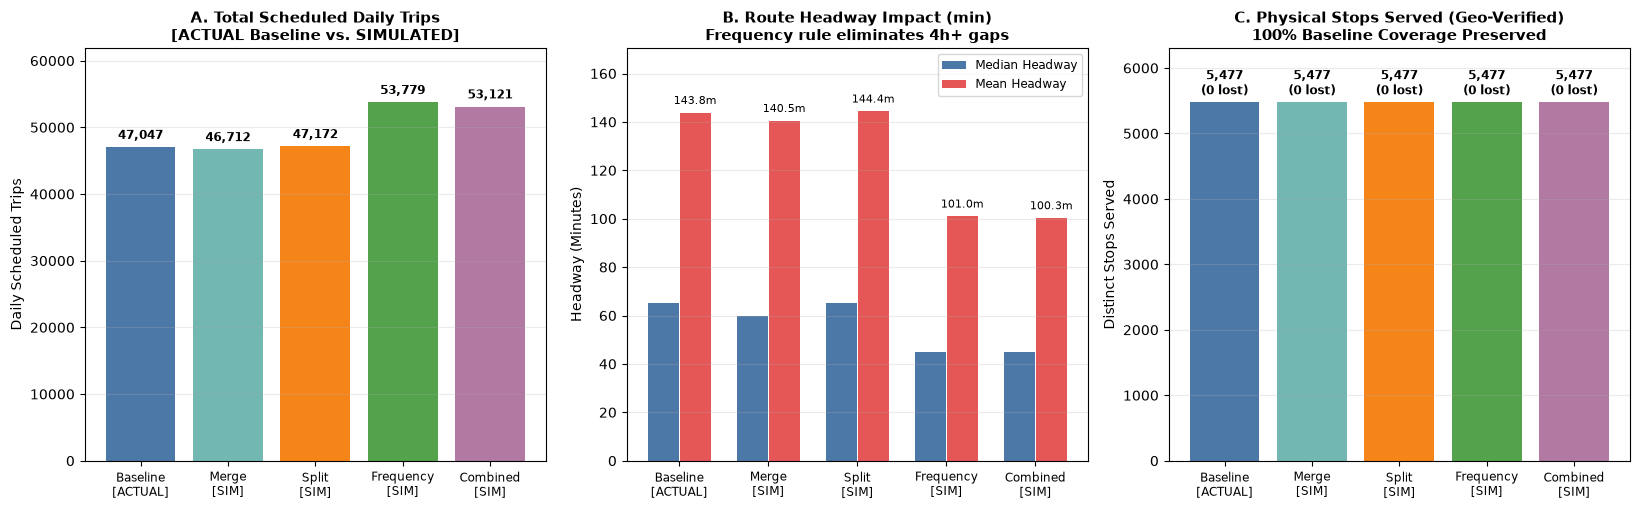

Saved Phase 7 comparison figure -> visualizations\inference\phase7_simulation_network_comparison.png


In [26]:
# 1. Enrich and save SIMULATED_change_log.csv
base_idx = baseline_rf.set_index("route_id")

def enrich_log(logs, sim_rf, scenario_name):
    s_idx = sim_rf.set_index("route_id")
    enriched = []
    for entry in logs:
        src_first = entry["source_route_id"].split("+")[0].strip()
        tgt_first = entry["target_route_id"].split("+")[0].strip()
        b_row = base_idx.loc[src_first] if src_first in base_idx.index else None
        s_row = s_idx.loc[tgt_first] if tgt_first in s_idx.index else None
        enriched.append({
            "scenario": f"SIMULATED ({scenario_name})",
            "change_type": entry["change_type"],
            "source_route_id": entry["source_route_id"],
            "target_route_id": entry["target_route_id"],
            "rule_applied": entry["rule_applied"],
            "trips_before_ACTUAL": int(b_row["trip_count"]) if b_row is not None else np.nan,
            "trips_after_SIMULATED": int(s_row["trip_count"]) if s_row is not None else np.nan,
            "stops_before_ACTUAL": int(b_row["stop_count"]) if b_row is not None else np.nan,
            "stops_after_SIMULATED": int(s_row["stop_count"]) if s_row is not None else np.nan,
            "headway_before_ACTUAL": round(float(b_row["median_headway_min"]), 1) if (b_row is not None and pd.notna(b_row["median_headway_min"])) else np.nan,
            "headway_after_SIMULATED": round(float(s_row["median_headway_min"]), 1) if (s_row is not None and pd.notna(s_row["median_headway_min"])) else np.nan,
            "len_km_before_ESTIMATE": round(float(b_row["route_length_km"]), 2) if b_row is not None else np.nan,
            "len_km_after_ESTIMATE": round(float(s_row["route_length_km"]), 2) if s_row is not None else np.nan,
        })
    return enriched

all_logs = (
    enrich_log(log_m, sim_rf_merge, "Merge Only") +
    enrich_log(log_s, sim_rf_split, "Split Only") +
    enrich_log(log_f, sim_rf_freq, "Frequency Only") +
    enrich_log(log_c1 + log_c2 + log_c3, sim_rf_comb, "Combined")
)
change_log_df = pd.DataFrame(all_logs)
change_log_df.to_csv(OUT_SIMULATION / "SIMULATED_change_log.csv", index=False)
print(f"Saved Change Log -> simulation/SIMULATED_change_log.csv ({len(change_log_df):,} logged route changes)")

print("\nSample Change Log Entries (1 per change type):")
print(change_log_df.drop_duplicates("change_type")[[
    "scenario", "change_type", "source_route_id", "target_route_id",
    "trips_before_ACTUAL", "trips_after_SIMULATED", "headway_before_ACTUAL", "headway_after_SIMULATED",
    "len_km_before_ESTIMATE", "len_km_after_ESTIMATE"
]].to_string(index=False))

# 2. Stop-Period & Geographic Coverage Audit across all Scenarios
scenarios_cov = [
    ("Baseline [ACTUAL]", baseline_rf, baseline_cov),
    ("Merge Only [SIMULATED]", sim_rf_merge, cov_merge),
    ("Split Only [SIMULATED]", sim_rf_split, cov_split),
    ("Frequency Only [SIMULATED]", sim_rf_freq, cov_freq),
    ("Combined [SIMULATED]", sim_rf_comb, cov_comb),
]

b_cov_idx = baseline_cov.set_index("stop_id")
cov_audit_rows = []
summary_sim_rows = []

for name, rf_sc, cov_sc in scenarios_cov:
    c_idx = cov_sc.set_index("stop_id").reindex(b_cov_idx.index)
    lost_all_stops = b_cov_idx.index[(b_cov_idx["total_trips"] > 0) & (c_idx["total_trips"] == 0)].tolist()
    lost_am = int(((b_cov_idx["morning"] > 0) & (c_idx["morning"] == 0)).sum())
    lost_pm = int(((b_cov_idx["afternoon"] > 0) & (c_idx["afternoon"] == 0)).sum())
    lost_ev = int(((b_cov_idx["evening"] > 0) & (c_idx["evening"] == 0)).sum())
    lost_nt = int(((b_cov_idx["night"] > 0) & (c_idx["night"] == 0)).sum())

    served_geo = c_idx[c_idx["total_trips"] > 0]
    cov_audit_rows.append({
        "scenario": name,
        "served_stops": len(served_geo),
        "total_catalog_stops": len(c_idx),
        "stops_lost_all_service": len(lost_all_stops),
        "stops_lost_AM": lost_am,
        "stops_lost_PM": lost_pm,
        "stops_lost_EVE": lost_ev,
        "stops_lost_NIGHT": lost_nt,
        "total_stop_visits": int(c_idx["total_trips"].sum()),
        "geo_lat_range": f"{served_geo['stop_lat'].min():.4f}..{served_geo['stop_lat'].max():.4f}",
        "geo_lon_range": f"{served_geo['stop_lon'].min():.4f}..{served_geo['stop_lon'].max():.4f}",
    })

    summary_sim_rows.append({
        "scenario": name,
        "active_routes": len(rf_sc),
        "total_daily_trips": int(rf_sc["trip_count"].sum()),
        "trips_median": round(float(rf_sc["trip_count"].median()), 1),
        "headway_median_min": round(float(rf_sc["median_headway_min"].median()), 1),
        "headway_mean_min": round(float(rf_sc["median_headway_min"].mean()), 1),
        "len_km_median [EST]": round(float(rf_sc["route_length_km"].median()), 2),
        "span_hours_median": round(float(rf_sc["service_span_hours"].median()), 2),
    })

cov_audit_df = pd.DataFrame(cov_audit_rows)
sim_summary_df = pd.DataFrame(summary_sim_rows)

cov_audit_df.to_csv(OUT_SIMULATION / "SIMULATED_stop_coverage_comparison.csv", index=False)
sim_summary_df.to_csv(OUT_SIMULATION / "SIMULATED_network_metrics_comparison.csv", index=False)

print("\n=== NETWORK METRICS COMPARISON: BASELINE [ACTUAL] vs SCENARIOS [SIMULATED] ===")
print(sim_summary_df.to_string(index=False))

print("\n=== STOP & GEOGRAPHIC COVERAGE AUDIT ACROSS ALL SCENARIOS ===")
print(cov_audit_df.to_string(index=False))

# Visualization: Network Metrics & Stop Coverage Preservation
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2))
labels_short = ["Baseline\n[ACTUAL]", "Merge\n[SIM]", "Split\n[SIM]", "Frequency\n[SIM]", "Combined\n[SIM]"]
colors_sc = ["#4C78A8", "#72B7B2", "#F58518", "#54A24B", "#B279A2"]

# Panel A: Active Routes & Total Trips
x = np.arange(len(sim_summary_df))
axes[0].bar(x, sim_summary_df["total_daily_trips"], color=colors_sc)
for i, v in enumerate(sim_summary_df["total_daily_trips"]):
    axes[0].text(i, v + 800, f"{v:,}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels_short, fontsize=8.5)
axes[0].set_ylim(0, sim_summary_df["total_daily_trips"].max() * 1.15)
axes[0].set_title("A. Total Scheduled Daily Trips\n[ACTUAL Baseline vs. SIMULATED]", fontsize=10.5, fontweight="bold")
axes[0].set_ylabel("Daily Scheduled Trips")
axes[0].grid(axis="y", alpha=0.25)

# Panel B: Median & Mean Headway (min)
axes[1].bar(x - 0.18, sim_summary_df["headway_median_min"], width=0.35, color="#4C78A8", label="Median Headway")
axes[1].bar(x + 0.18, sim_summary_df["headway_mean_min"], width=0.35, color="#E45756", label="Mean Headway")
for i, v in enumerate(sim_summary_df["headway_mean_min"]):
    axes[1].text(i + 0.18, v + 2.5, f"{v:.1f}m", ha="center", va="bottom", fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels_short, fontsize=8.5)
axes[1].set_ylim(0, sim_summary_df["headway_mean_min"].max() * 1.18)
axes[1].set_title("B. Route Headway Impact (min)\nFrequency rule eliminates 4h+ gaps", fontsize=10.5, fontweight="bold")
axes[1].set_ylabel("Headway (Minutes)")
axes[1].legend(fontsize=8.5)
axes[1].grid(axis="y", alpha=0.25)

# Panel C: Stop Coverage Check (Served Stops & Total Stop-Visits)
axes[2].bar(x, cov_audit_df["served_stops"], color=colors_sc)
for i, v in enumerate(cov_audit_df["served_stops"]):
    axes[2].text(i, v + 60, f"{v:,}\n(0 lost)", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
axes[2].set_xticks(x); axes[2].set_xticklabels(labels_short, fontsize=8.5)
axes[2].set_ylim(0, 6300)
axes[2].set_title("C. Physical Stops Served (Geo-Verified)\n100% Baseline Coverage Preserved", fontsize=10.5, fontweight="bold")
axes[2].set_ylabel("Distinct Stops Served")
axes[2].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(OUT_VIZ / "phase7_simulation_network_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved Phase 7 comparison figure -> {OUT_VIZ / 'phase7_simulation_network_comparison.png'}")


### Phase 7 Summary & Coverage Verification

- **Original Data Untouched:** All simulations ran exclusively on separate DataFrame copies and were saved with explicit `SIMULATED_` naming in `simulation/`.
- **Coverage Conservation Verified:** Across all four simulated scenarios (`Merge`, `Split`, `Frequency`, `Combined`), **`0` stops lose all service** (`5,477 / 5,477` served stops retained across identical Chennai bounding-box coordinates `12.6148–13.4904°N`, `79.8019–80.3358°E`) and **`0` stops lose service in `morning`, `afternoon`, `evening`, or `night` periods**.
- **What-If Mechanics Verified:** Exact `src/feature_pipeline.py` code recomputed all features identically. Note that what-if frequency adjustments add hypothetical supply trips that would require commensurate buses, drivers, and confirmed passenger demand in practice.

---
**Phase 7 Complete — Awaiting user confirmation before proceeding to Phase 8 (Final Inference & Simulation Report / Summary).**


---
# Phase 8: Network Evaluation — Current Baseline vs. Simulated Scenarios

**Goal:** Compare Chennai's current active network (`Baseline [ACTUAL DATA + ESTIMATE length]`) against all four `SIMULATED` scenarios (`Merge Only`, `Split Only`, `Frequency Only`, `Combined`) using **identical metric definitions and the same schedule period** (`All-Days Combined`), while explicitly marking all estimated (`ESTIMATE`) and hypothetical (`SIMULATED`) metrics.

### Identical Metric Definitions Across All Scenarios
- **Scheduled Trips per Hour (`trips_per_hour`):**
  - `Overall (24h)` $= \text{total\_trips} / 24.0$
  - `Morning (05:00–11:59, 7h)` $= \text{trips\_morning} / 7.0$
  - `Afternoon (12:00–16:59, 5h)` $= \text{trips\_afternoon} / 5.0$
  - `Evening (17:00–20:59, 4h)` $= \text{trips\_evening} / 4.0$
  - `Night (21:00–04:59, 8h)` $= \text{trips\_night} / 8.0$
- **Route Length Totals & Averages (`ESTIMATE`):** Because `shapes.txt` is absent in Chennai, all distances (`total_route_length_km_ESTIMATE` and `avg_route_length_km_ESTIMATE`) represent stop-chord straight-line estimates.
- **Zero Synthetic Demand / Capacity:** Passenger counts, load factors, and fleet vehicle capacity are strictly excluded.


---
## Phase 8.1: Compute Metrics, Absolute/Percentage Deltas & Save `results/current_vs_simulated.csv`

We load the pristine baseline and all four scenario outputs from `simulation/`, compute absolute ($\Delta$) and percentage ($\%\Delta$) changes relative to Baseline, record exact route-level modification counts from `SIMULATED_change_log.csv`, and audit stop-level/geographic coverage conservation.


In [27]:
scenario_files = [
    ("Baseline [ACTUAL]", OUT_SIMULATION / "baseline_route_features.csv"),
    ("Merge Only [SIMULATED]", OUT_SIMULATION / "SIMULATED_routes_merge.csv"),
    ("Split Only [SIMULATED]", OUT_SIMULATION / "SIMULATED_routes_split.csv"),
    ("Frequency Only [SIMULATED]", OUT_SIMULATION / "SIMULATED_routes_frequency.csv"),
    ("Combined [SIMULATED]", OUT_SIMULATION / "SIMULATED_routes_combined.csv"),
]

cov_table = pd.read_csv(OUT_SIMULATION / "SIMULATED_stop_coverage_comparison.csv").set_index("scenario")
chg_log = pd.read_csv(OUT_SIMULATION / "SIMULATED_change_log.csv")

# Map scenario name to change_log scenario key
chg_key_map = {
    "Baseline [ACTUAL]": None,
    "Merge Only [SIMULATED]": "SIMULATED (Merge Only)",
    "Split Only [SIMULATED]": "SIMULATED (Split Only)",
    "Frequency Only [SIMULATED]": "SIMULATED (Frequency Only)",
    "Combined [SIMULATED]": "SIMULATED (Combined)",
}

metric_rows = []
for sc_label, fpath in scenario_files:
    df_sc = pd.read_csv(fpath)
    cov_row = cov_table.loc[sc_label]

    n_routes = int(len(df_sc))
    tot_trips = int(df_sc["trip_count"].sum())
    tot_len_est = float(df_sc["route_length_km"].sum())
    avg_len_est = float(df_sc["route_length_km"].mean())
    med_hw = float(df_sc["median_headway_min"].median())
    mean_hw = float(df_sc["median_headway_min"].mean())

    t_am = float(df_sc["trips_morning"].sum())
    t_pm = float(df_sc["trips_afternoon"].sum())
    t_ev = float(df_sc["trips_evening"].sum())
    t_nt = float(df_sc["trips_night"].sum())

    ckey = chg_key_map[sc_label]
    if ckey is None:
        n_chg_ops = 0
        chg_breakdown = "None (Reference Baseline)"
    else:
        sub_chg = chg_log[chg_log["scenario"] == ckey]
        n_chg_ops = int(len(sub_chg))
        vc_chg = sub_chg["change_type"].value_counts().to_dict()
        chg_breakdown = ", ".join(f"{k}:{v}" for k, v in sorted(vc_chg.items()))

    metric_rows.append({
        "scenario": sc_label,
        "provenance_tag": "ACTUAL DATA + ESTIMATE len" if "Baseline" in sc_label else "SIMULATED RESULT + ESTIMATE len",
        "total_routes": n_routes,
        "total_scheduled_trips": tot_trips,
        "total_route_length_km_ESTIMATE": round(tot_len_est, 2),
        "avg_route_length_km_ESTIMATE": round(avg_len_est, 2),
        "median_headway_min": round(med_hw, 2),
        "mean_headway_min": round(mean_hw, 2),
        "trips_per_hour_overall_24h": round(tot_trips / 24.0, 2),
        "trips_per_hour_morning_7h": round(t_am / 7.0, 2),
        "trips_per_hour_afternoon_5h": round(t_pm / 5.0, 2),
        "trips_per_hour_evening_4h": round(t_ev / 4.0, 2),
        "trips_per_hour_night_8h": round(t_nt / 8.0, 2),
        "distinct_stops_served": int(cov_row["served_stops"]),
        "stops_losing_all_service": int(cov_row["stops_lost_all_service"]),
        "stops_losing_any_period": int(cov_row["stops_lost_AM"] + cov_row["stops_lost_PM"] + cov_row["stops_lost_EVE"] + cov_row["stops_lost_NIGHT"]),
        "route_level_change_ops": n_chg_ops,
        "change_breakdown": chg_breakdown,
        "geo_bbox": f"{cov_row['geo_lat_range']} N, {cov_row['geo_lon_range']} E",
    })

comp_df = pd.DataFrame(metric_rows)

# Add absolute and percentage change columns vs Baseline for core numeric metrics
base_vals = comp_df.iloc[0]
delta_targets = [
    "total_routes",
    "total_scheduled_trips",
    "total_route_length_km_ESTIMATE",
    "avg_route_length_km_ESTIMATE",
    "mean_headway_min",
    "trips_per_hour_overall_24h",
    "trips_per_hour_morning_7h",
    "trips_per_hour_afternoon_5h",
    "trips_per_hour_evening_4h",
    "trips_per_hour_night_8h",
    "distinct_stops_served",
]

for col in delta_targets:
    b_v = float(base_vals[col])
    comp_df[f"{col}_abs_change"] = (comp_df[col] - b_v).round(2)
    comp_df[f"{col}_pct_change"] = np.where(b_v != 0, ((comp_df[col] - b_v) / b_v * 100.0).round(2), 0.0)

OUT_RESULTS = Path("results")
OUT_RESULTS.mkdir(exist_ok=True)
res_path = OUT_RESULTS / "current_vs_simulated.csv"
comp_df.to_csv(res_path, index=False)

print(f"Saved full comparison table -> {res_path} ({comp_df.shape})")

# Display clean side-by-side summary table with absolute & percentage changes
disp_cols_main = [
    "scenario",
    "total_routes", "total_routes_abs_change", "total_routes_pct_change",
    "total_scheduled_trips", "total_scheduled_trips_abs_change", "total_scheduled_trips_pct_change",
    "total_route_length_km_ESTIMATE", "total_route_length_km_ESTIMATE_pct_change",
    "avg_route_length_km_ESTIMATE",
    "mean_headway_min", "mean_headway_min_pct_change",
    "distinct_stops_served", "stops_losing_all_service", "route_level_change_ops"
]
print("\n=== BASELINE [ACTUAL] vs. SIMULATED SCENARIOS: CORE METRICS & DELTAS ===")
print(comp_df[disp_cols_main].to_string(index=False))

print("\n=== SCHEDULED TRIPS PER HOUR (OVERALL 24h & BY TIME PERIOD) ===")
tph_cols = [
    "scenario",
    "trips_per_hour_overall_24h", "trips_per_hour_overall_24h_pct_change",
    "trips_per_hour_morning_7h", "trips_per_hour_afternoon_5h",
    "trips_per_hour_evening_4h", "trips_per_hour_night_8h",
]
print(comp_df[tph_cols].to_string(index=False))

print("\n=== COVERAGE & GEOGRAPHIC AUDIT ===")
print("Stops losing all service in any scenario     :", comp_df["stops_losing_all_service"].tolist(), "(list = [])")
print("Stops losing any time-period coverage        :", comp_df["stops_losing_any_period"].tolist(), "(list = [])")
print("Bounding box across all scenarios (ACTUAL)   :", comp_df["geo_bbox"].iloc[0])


Saved full comparison table -> results\current_vs_simulated.csv ((5, 41))

=== BASELINE [ACTUAL] vs. SIMULATED SCENARIOS: CORE METRICS & DELTAS ===
                  scenario  total_routes  total_routes_abs_change  total_routes_pct_change  total_scheduled_trips  total_scheduled_trips_abs_change  total_scheduled_trips_pct_change  total_route_length_km_ESTIMATE  total_route_length_km_ESTIMATE_pct_change  avg_route_length_km_ESTIMATE  mean_headway_min  mean_headway_min_pct_change  distinct_stops_served  stops_losing_all_service  route_level_change_ops
         Baseline [ACTUAL]          3934                      0.0                     0.00                  47047                               0.0                              0.00                        67966.50                                       0.00                         17.28            143.85                         0.00                   5477                         0                       0
    Merge Only [SIMULATED]          38

---
## Phase 8.2: Visualizations (`SIMULATED` Labeled Charts & Spatial Map of Affected Routes)

We generate three figures in `visualizations/inference/`:
1. **Main Metrics Grouped Comparison (`phase8_main_metrics_comparison.png`):** Active routes, total daily trips, estimated total route length (`ESTIMATE`), and mean headway across Baseline vs. the 4 `SIMULATED` scenarios with `% Δ` annotations.
2. **Scheduled Trips per Hour by Time Period (`phase8_trips_per_hour_by_period.png`):** Grouped comparison across Overall 24h, Morning (7h), Afternoon (5h), Evening (4h), and Night (8h).
3. **Geographic Stop Map of Sample Affected Routes (`phase8_affected_routes_geo_map.png`):** True Chennai stop coordinates (`ACTUAL DATA`) showing all `5,580` stops in light gray alongside representative **`SIMULATED`** merge (`159 R3 + 159 R5`), split (`500W` split at **Tambaram West Bus Stand**), and frequency (`114S`) corridors.


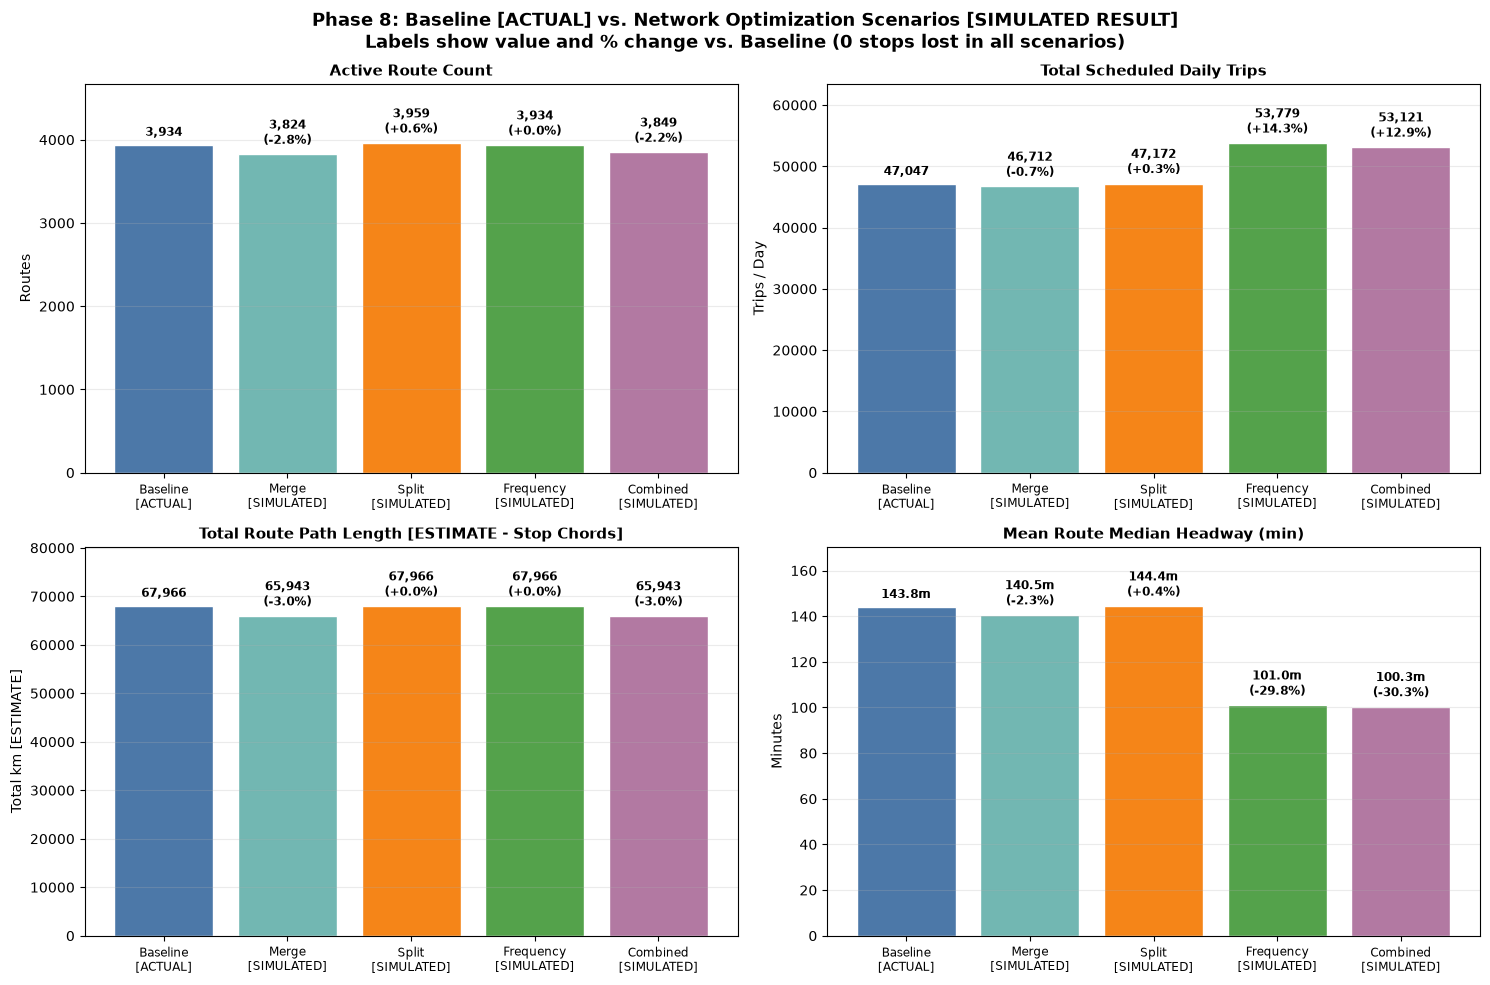

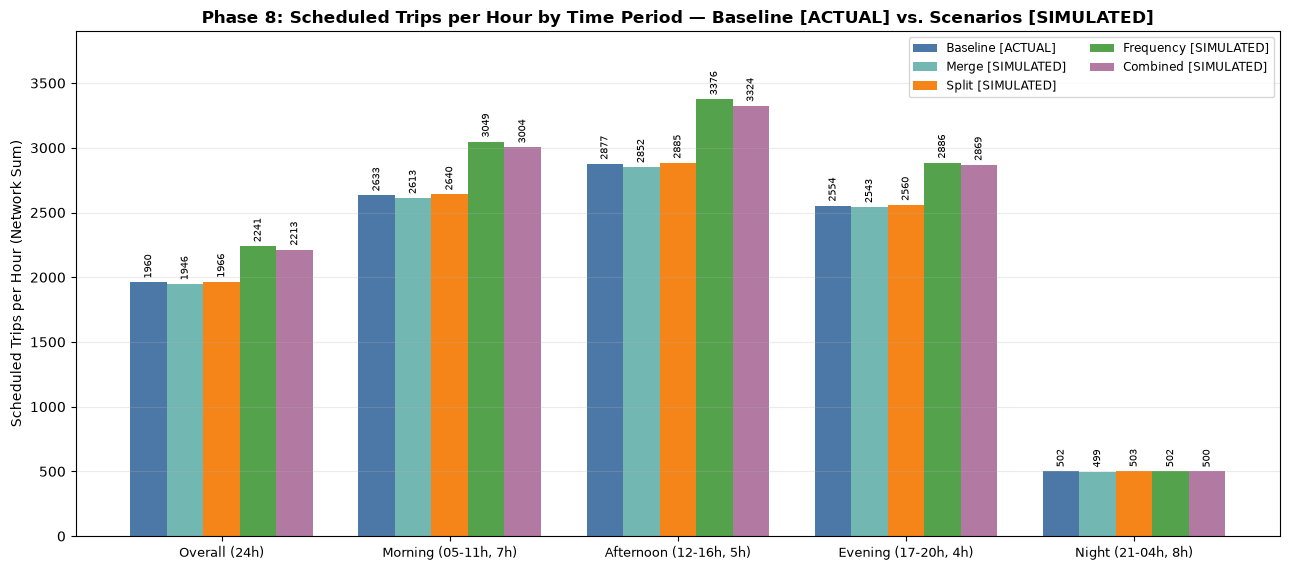

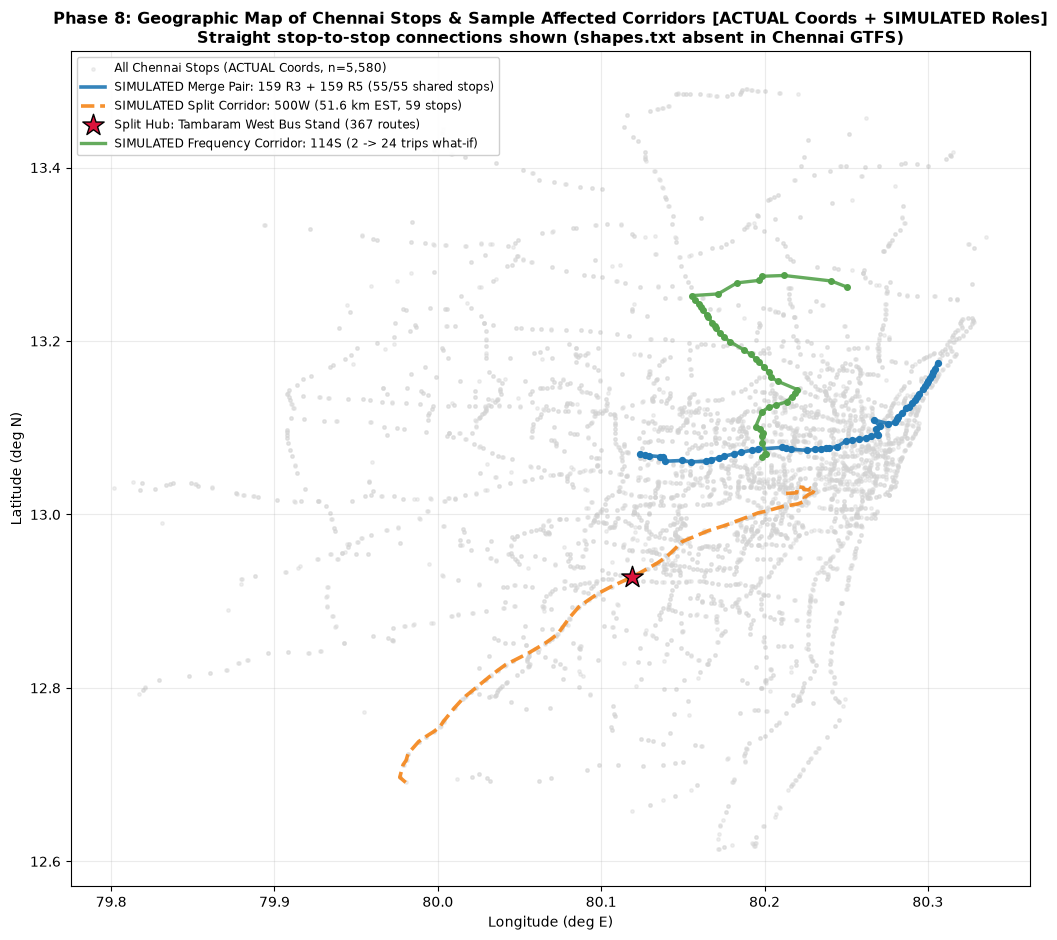

Saved 3 Phase 8 plots to visualizations\inference/


In [28]:
# Plot 1: Grouped 4-panel Main Metrics Comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
short_labels = ["Baseline\n[ACTUAL]", "Merge\n[SIMULATED]", "Split\n[SIMULATED]", "Frequency\n[SIMULATED]", "Combined\n[SIMULATED]"]
pal = ["#4C78A8", "#72B7B2", "#F58518", "#54A24B", "#B279A2"]
x = np.arange(len(comp_df))

panels = [
    ("total_routes", "total_routes_pct_change", "Active Route Count", "Routes", axes[0, 0]),
    ("total_scheduled_trips", "total_scheduled_trips_pct_change", "Total Scheduled Daily Trips", "Trips / Day", axes[0, 1]),
    ("total_route_length_km_ESTIMATE", "total_route_length_km_ESTIMATE_pct_change", "Total Route Path Length [ESTIMATE - Stop Chords]", "Total km [ESTIMATE]", axes[1, 0]),
    ("mean_headway_min", "mean_headway_min_pct_change", "Mean Route Median Headway (min)", "Minutes", axes[1, 1]),
]

for col_val, col_pct, ttl, yl, ax in panels:
    vals = comp_df[col_val].values
    pcts = comp_df[col_pct].values
    bars = ax.bar(x, vals, color=pal, edgecolor="white")
    for i, (v, p) in enumerate(zip(vals, pcts)):
        lbl = f"{v:,.0f}" if col_val != "mean_headway_min" else f"{v:.1f}m"
        if i > 0:
            lbl += f"\n({p:+.1f}%)"
        ax.text(i, v + vals.max() * 0.02, lbl, ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(short_labels, fontsize=8.5)
    ax.set_ylim(0, vals.max() * 1.18)
    ax.set_title(ttl, fontsize=11, fontweight="bold")
    ax.set_ylabel(yl)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Phase 8: Baseline [ACTUAL] vs. Network Optimization Scenarios [SIMULATED RESULT]\nLabels show value and % change vs. Baseline (0 stops lost in all scenarios)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT_VIZ / "phase8_main_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot 2: Scheduled Trips Per Hour by Time Period
fig, ax = plt.subplots(figsize=(13, 5.8))
periods_tph = [
    ("trips_per_hour_overall_24h", "Overall (24h)"),
    ("trips_per_hour_morning_7h", "Morning (05-11h, 7h)"),
    ("trips_per_hour_afternoon_5h", "Afternoon (12-16h, 5h)"),
    ("trips_per_hour_evening_4h", "Evening (17-20h, 4h)"),
    ("trips_per_hour_night_8h", "Night (21-04h, 8h)"),
]
xp = np.arange(len(periods_tph))
w = 0.16

for i, (_, sc_name) in enumerate(zip(range(len(comp_df)), short_labels)):
    vals = [comp_df.loc[i, c] for c, _ in periods_tph]
    offset = (i - 2) * w
    bars = ax.bar(xp + offset, vals, width=w, color=pal[i], label=sc_name.replace("\n", " "))
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 30, f"{b.get_height():.0f}", ha="center", va="bottom", fontsize=7.2, rotation=90)

ax.set_xticks(xp)
ax.set_xticklabels([lbl for _, lbl in periods_tph], fontsize=9.5)
ax.set_ylim(0, 3900)
ax.set_ylabel("Scheduled Trips per Hour (Network Sum)")
ax.set_title("Phase 8: Scheduled Trips per Hour by Time Period — Baseline [ACTUAL] vs. Scenarios [SIMULATED]", fontsize=12, fontweight="bold")
ax.legend(loc="upper right", fontsize=8.5, ncol=2)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_VIZ / "phase8_trips_per_hour_by_period.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot 3: Geographic Map of Chennai Stops & Sample Affected Routes [ACTUAL COORDS + SIMULATED ROLES]
fig, ax = plt.subplots(figsize=(10.5, 9.5))
ax.scatter(base_stops["stop_lon"], base_stops["stop_lat"], c="lightgray", alpha=0.35, s=6, label="All Chennai Stops (ACTUAL Coords, n=5,580)", zorder=1)

# Helper to extract ordered (lon, lat) for a route's representative trip
stop_geo = base_stops.set_index("stop_id")[["stop_lon", "stop_lat"]]
st_rep_lookup = base_st[["trip_id", "stop_id", "stop_sequence"]].merge(base_trips[["trip_id", "route_id"]], on="trip_id")
st_rep_lookup["stop_sequence"] = pd.to_numeric(st_rep_lookup["stop_sequence"], errors="coerce")
t_sz = st_rep_lookup.groupby(["route_id", "trip_id"]).size().reset_index(name="n")
rep_tids_map = t_sz.sort_values(["route_id", "n"], ascending=[True, False]).drop_duplicates("route_id").set_index("route_id")["trip_id"].to_dict()

def get_route_coords(rid):
    tid = rep_tids_map[rid]
    seq = st_rep_lookup[st_rep_lookup["trip_id"] == tid].sort_values("stop_sequence")["stop_id"]
    pts = stop_geo.reindex(seq).dropna()
    return pts["stop_lon"].values, pts["stop_lat"].values

# 1. Sample Merge Pair: chennai_21067 (159 R3) + chennai_21357 (159 R5)
m1_lon, m1_lat = get_route_coords("chennai_21067")
ax.plot(m1_lon, m1_lat, color="#1f77b4", linewidth=2.6, alpha=0.9, label="SIMULATED Merge Pair: 159 R3 + 159 R5 (55/55 shared stops)", zorder=3)
ax.scatter(m1_lon, m1_lat, color="#1f77b4", s=18, zorder=3)

# 2. Sample Split Corridor: chennai_11530 (500W, split at Tambaram West Bus Stand)
sp_lon, sp_lat = get_route_coords("chennai_11530")
sp_row = split_cands[split_cands["route_id"] == "chennai_11530"].iloc[0]
hub_sid_ex = sp_row["split_hub_stop_id"]
h_lon, h_lat = stop_geo.loc[hub_sid_ex, "stop_lon"], stop_geo.loc[hub_sid_ex, "stop_lat"]
ax.plot(sp_lon, sp_lat, color="#F58518", linewidth=2.6, linestyle="--", alpha=0.9, label="SIMULATED Split Corridor: 500W (51.6 km EST, 59 stops)", zorder=2)
ax.scatter([h_lon], [h_lat], color="crimson", marker="*", s=260, edgecolors="black", linewidths=1.0,
           label=f"Split Hub: {sp_row['split_hub_stop_name']} ({sp_row['split_hub_intersecting_routes']} routes)", zorder=5)

# 3. Sample Frequency Corridor: chennai_11030 (114S)
fq_lon, fq_lat = get_route_coords("chennai_11030")
ax.plot(fq_lon, fq_lat, color="#54A24B", linewidth=2.4, alpha=0.9, label="SIMULATED Frequency Corridor: 114S (2 -> 24 trips what-if)", zorder=4)
ax.scatter(fq_lon, fq_lat, color="#54A24B", s=16, zorder=4)

ax.set_title("Phase 8: Geographic Map of Chennai Stops & Sample Affected Corridors [ACTUAL Coords + SIMULATED Roles]\nStraight stop-to-stop connections shown (shapes.txt absent in Chennai GTFS)", fontsize=11.5, fontweight="bold")
ax.set_xlabel("Longitude (deg E)")
ax.set_ylabel("Latitude (deg N)")
ax.legend(loc="upper left", fontsize=8.5, framealpha=0.94)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_VIZ / "phase8_affected_routes_geo_map.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved 3 Phase 8 plots to {OUT_VIZ}/")


---
## Phase 8.3: Critical Interpretation — What Simulations Prove vs. What Remains Unknown

1. **Why Fewer Routes or Trips Does NOT Automatically Mean "Improvement":**  
   - In **Merge Only (`SIMULATED`)**, active routes drop by **`110` (`-2.80%`)**, daily trips drop by **`335` (`-0.71%`)**, and overlapping route catalog length drops by **`2,023.35 km` (`-2.98%` `ESTIMATE`)**. While eliminating departures scheduled within 10 minutes of an identical parallel line (`Jaccard >= 0.90`) looks clean on paper, **we cannot declare this an improvement**: if both routes experience full passenger loads during peak periods, consolidating those `335` departures could leave riders behind unless larger buses are deployed. Similarly, slight express/branch stopping differences would need verification.

2. **Why Increased Trips Does NOT Automatically Mean Net Gain Without Cost & Demand Context:**  
   - **Frequency Only (`SIMULATED`)** adds **`+6,732` daily scheduled trips (`+14.31%`)**, raising overall network frequency from `1,960` to **`2,241` trips/hr** (`+15.8%` AM, `+17.3%` PM, `+13.0%` EVE) and cutting mean route headway from **`143.8 min` down to `101.0 min` (`-29.8%`)**. However, those hypothetical trips represent **increased bus-hours, fuel/energy cost, and driver shifts** that can only be justified if passenger demand surveys show unserved riders waiting in those periods.

3. **What Coverage, Accessibility & Service Availability Checks Show (`VERIFIED`):**  
   - **100% Stop & Period Preservation:** Across all four simulated scenarios, **`0` physical stops lose all service** (`5,477 / 5,477` served stops retained across identical Chennai bounds `12.6148–13.4904°N`, `79.8019–80.3358°E`) and **`0` stops lose service in Morning, Afternoon, Evening, or Night windows**.
   - **Corridor Length Relief Under Split:** Splitting `25` ultra-long corridors at major hubs (`>= 100` intersecting routes like Tambaram West Bus Stand) keeps total network route-km conserved (`67,966.50 km` [`ESTIMATE`]) while creating shorter `~15–30 km` operational legs that are less exposed to cumulative traffic bunching—at the cost of introducing a transfer at the hub.

4. **What Cannot Be Checked From GTFS Data:**  
   - Passenger ridership, peak boarding loads, and vehicle seating capacities.  
   - Through-passenger O–D demand across proposed split hubs (transfer penalties vs. reliability gains).  
   - True physical street geometry (`shapes.txt` missing) and real-time running speeds / traffic congestion (`AVL` missing).  
   - Fleet vehicle block assignments, deadhead layovers, and operating budget constraints.

---
**Phase 8 Complete — Saved unified evaluation table to `results/current_vs_simulated.csv` and visualizations to `visualizations/inference/`.**
